<a href="https://colab.research.google.com/github/vangalasahasri/energy-forecasting-project/blob/main/energy_forecasting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
print("Cloud-Based Energy Consumption Forecasting and Optimization System")
print("Project setup started successfully!")

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import sklearn
import statsmodels

print("All basic project libraries are ready!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)
print("Scikit-learn version:", sklearn.__version__)
print("Statsmodels version:", statsmodels.__version__)

All basic project libraries are ready!
Pandas version: 2.2.3
NumPy version: 2.1.3
Scikit-learn version: 1.6.1
Statsmodels version: 0.15.0


In [ ]:
from google.colab import files

uploaded = files.upload()

In [ ]:
import pandas as pd

df = pd.read_csv("energy_weather_dataset_practice.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

Dataset loaded successfully!
Dataset shape: (27024, 13)


,timestamp,zone,load_mw,temperature_c,humidity_pct,wind_speed_kmh,dispatch_price,population_index,hour,day_of_week,month,is_weekend,is_holiday
0,2022-04-01 00:00:00,DEOK,2911.09,7.74,62.86,6.85,27.58,100.1993,0,4,4,0,0
1,2022-04-01 01:00:00,DEOK,2849.99,9.91,78.08,17.85,29.97,100.1993,1,4,4,0,0
2,2022-04-01 02:00:00,DEOK,2812.03,3.48,78.06,5.27,23.12,100.1993,2,4,4,0,0
3,2022-04-01 03:00:00,DEOK,2771.34,12.55,69.02,14.13,21.97,100.1993,3,4,4,0,0
4,2022-04-01 04:00:00,DEOK,2829.86,10.58,64.34,5.99,36.38,100.1993,4,4,4,0,0


In [ ]:
print("Column names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDataset information:")
df.info()

Column names:
['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']

Missing values:
timestamp           0
zone                0
load_mw             0
temperature_c       0
humidity_pct        0
wind_speed_kmh      0
dispatch_price      0
population_index    0
hour                0
day_of_week         0
month               0
is_weekend          0
is_holiday          0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 27024 entries, 0 to 27023
Data columns (total 13 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   timestamp         27024 non-null  object 
 1   zone              27024 non-null  object 
 2   load_mw           27024 non-null  float64
 3   temperature_c     27024 non-null  float64
 4   humidity_pct      27024 non-null  float64
 5   wind_speed_kmh    27024

In [ ]:
# Step 1: Convert timestamp into datetime format
df["timestamp"] = pd.to_datetime(df["timestamp"])

# Step 2: Sort data by time
df = df.sort_values("timestamp").reset_index(drop=True)

# Step 3: Check and remove duplicate rows
df = df.drop_duplicates(subset=["timestamp"])

# Step 4: Display dataset details
print("Dataset shape:", df.shape)
print("\nDate range:")
print(df["timestamp"].min(), "to", df["timestamp"].max())

print("\nFirst 5 rows:")
display(df.head())

print("\nMissing values:")
print(df.isnull().sum())

Dataset shape: (27024, 13)

Date range:
2022-04-01 00:00:00 to 2025-04-30 23:00:00

First 5 rows:


,timestamp,zone,load_mw,temperature_c,humidity_pct,wind_speed_kmh,dispatch_price,population_index,hour,day_of_week,month,is_weekend,is_holiday
0,2022-04-01 00:00:00,DEOK,2911.09,7.74,62.86,6.85,27.58,100.1993,0,4,4,0,0
1,2022-04-01 01:00:00,DEOK,2849.99,9.91,78.08,17.85,29.97,100.1993,1,4,4,0,0
2,2022-04-01 02:00:00,DEOK,2812.03,3.48,78.06,5.27,23.12,100.1993,2,4,4,0,0
3,2022-04-01 03:00:00,DEOK,2771.34,12.55,69.02,14.13,21.97,100.1993,3,4,4,0,0
4,2022-04-01 04:00:00,DEOK,2829.86,10.58,64.34,5.99,36.38,100.1993,4,4,4,0,0



Missing values:
timestamp           0
zone                0
load_mw             0
temperature_c       0
humidity_pct        0
wind_speed_kmh      0
dispatch_price      0
population_index    0
hour                0
day_of_week         0
month               0
is_weekend          0
is_holiday          0
dtype: int64


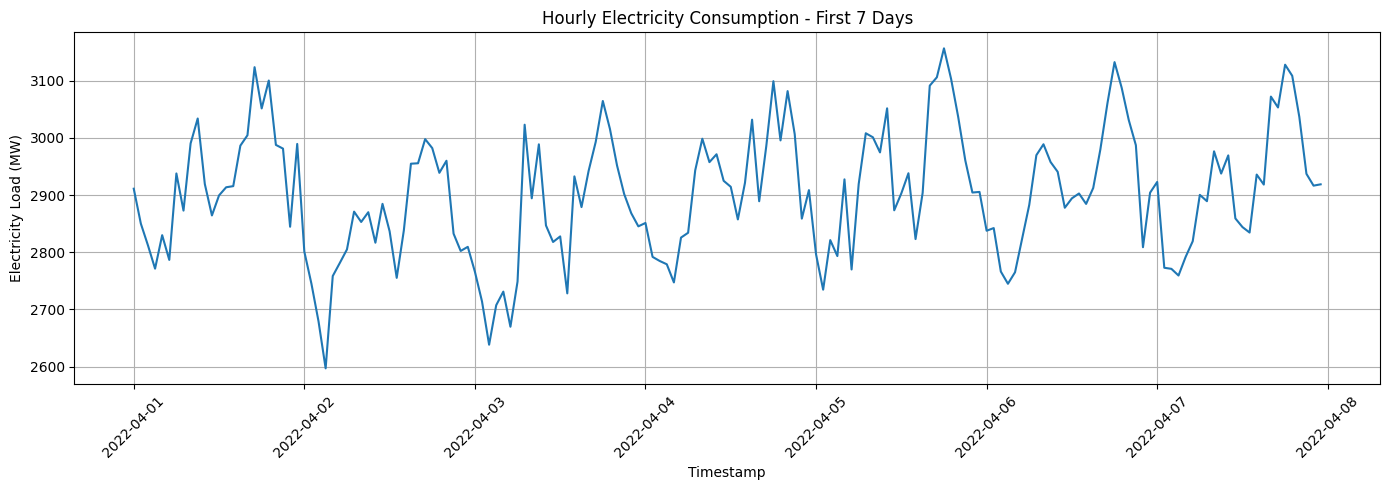

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(df["timestamp"][:168], df["load_mw"][:168])
plt.title("Hourly Electricity Consumption - First 7 Days")
plt.xlabel("Timestamp")
plt.ylabel("Electricity Load (MW)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.show()

Linear Regression Model Results
--------------------------------
Training records: 21619
Testing records: 5405
MAE: 73.77 MW
RMSE: 92.61 MW


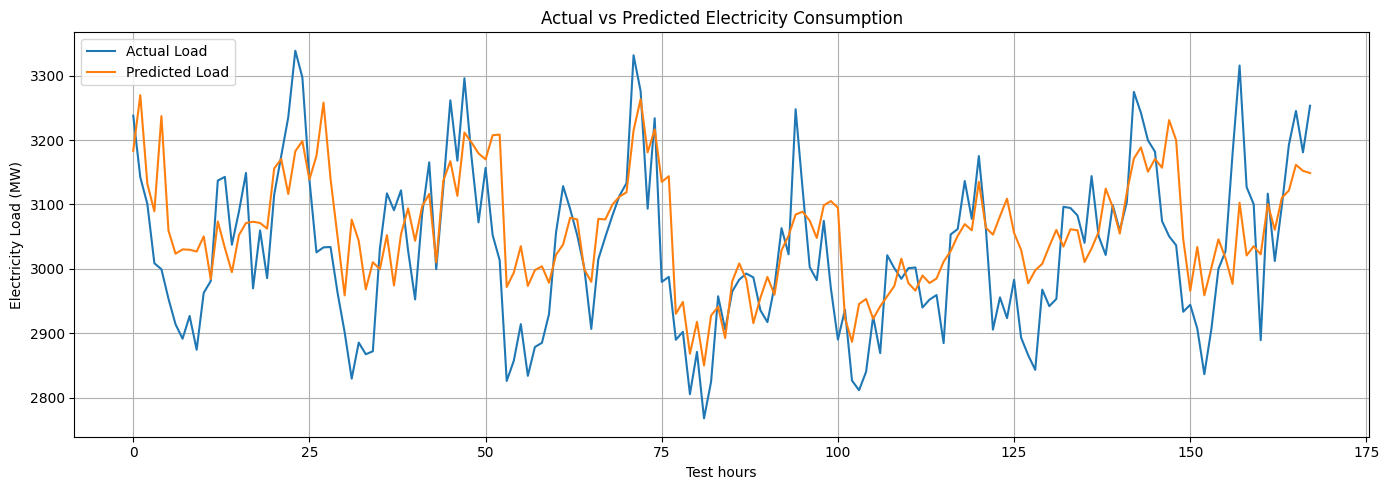

In [ ]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Select input features and target
features = [
    "temperature_c",
    "humidity_pct",
    "wind_speed_kmh",
    "dispatch_price",
    "population_index",
    "hour",
    "day_of_week",
    "month",
    "is_weekend",
    "is_holiday"
]

X = df[features]
y = df["load_mw"]

# Split chronologically: first 80% for training, last 20% for testing
split_index = int(len(df) * 0.8)

X_train = X.iloc[:split_index]
X_test = X.iloc[split_index:]
y_train = y.iloc[:split_index]
y_test = y.iloc[split_index:]

# Train the model
model = LinearRegression()
model.fit(X_train, y_train)

# Predict electricity demand
predictions = model.predict(X_test)

# Evaluate performance
mae = mean_absolute_error(y_test, predictions)
rmse = np.sqrt(mean_squared_error(y_test, predictions))

print("Linear Regression Model Results")
print("--------------------------------")
print("Training records:", len(X_train))
print("Testing records:", len(X_test))
print(f"MAE: {mae:.2f} MW")
print(f"RMSE: {rmse:.2f} MW")

# Plot actual vs predicted load for the first 168 test hours
plt.figure(figsize=(14, 5))
plt.plot(y_test.iloc[:168].to_numpy(), label="Actual Load")
plt.plot(predictions[:168], label="Predicted Load")
plt.title("Actual vs Predicted Electricity Consumption")
plt.xlabel("Test hours")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Support Vector Regression Results
---------------------------------
MAE: 67.84 MW
RMSE: 84.23 MW


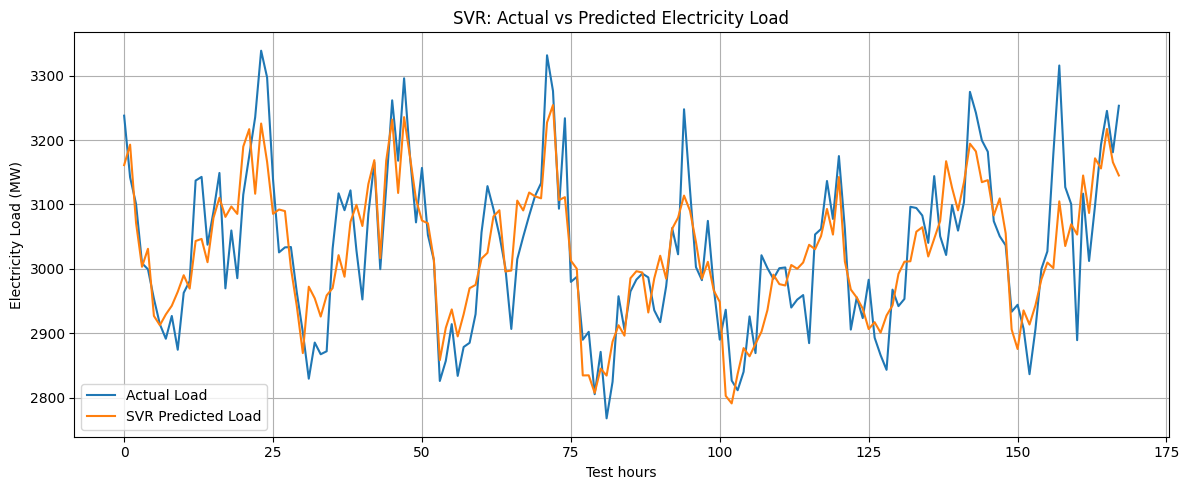

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Use the same chronological train/test split
svr_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=100, epsilon=10)
)

svr_model.fit(X_train, y_train)

svr_predictions = svr_model.predict(X_test)

svr_mae = mean_absolute_error(y_test, svr_predictions)
svr_rmse = np.sqrt(mean_squared_error(y_test, svr_predictions))

print("Support Vector Regression Results")
print("---------------------------------")
print(f"MAE: {svr_mae:.2f} MW")
print(f"RMSE: {svr_rmse:.2f} MW")

plt.figure(figsize=(12, 5))
plt.plot(y_test.iloc[:168].to_numpy(), label="Actual Load")
plt.plot(svr_predictions[:168], label="SVR Predicted Load")
plt.title("SVR: Actual vs Predicted Electricity Load")
plt.xlabel("Test hours")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

/usr/local/lib/python3.13/dist-packages/statsmodels/tsa/statespace/mlemodel.py:737: ConvergenceWarning: Maximum Likelihood optimization failed to converge. Check mle_retvals
  mlefit = super().fit(


SARIMAX Results
----------------
MAE: 293.84 MW
RMSE: 358.31 MW


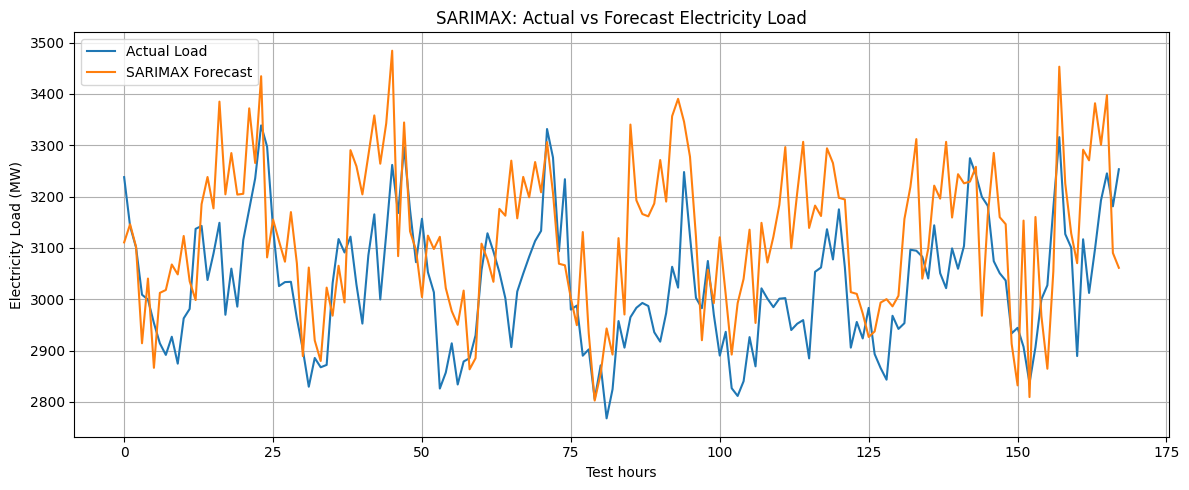

In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# Use a smaller subset initially to reduce runtime
train_size = int(len(df) * 0.8)

train_data = df.iloc[:train_size].copy()
test_data = df.iloc[train_size:].copy()

# Fit SARIMAX using hourly electricity load
sarimax_model = SARIMAX(
    train_data["load_mw"],
    exog=train_data[["temperature_c", "humidity_pct"]],
    order=(1, 0, 1),
    seasonal_order=(1, 0, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(disp=False, maxiter=50)

# Forecast the test period in batches of 24 hours
# This avoids fitting the model repeatedly.
sarimax_predictions = []

for start in range(0, len(test_data), 24):
    end = min(start + 24, len(test_data))
    exog_batch = test_data[["temperature_c", "humidity_pct"]].iloc[start:end]
    forecast = sarimax_fit.get_forecast(
        steps=len(exog_batch),
        exog=exog_batch
    )
    sarimax_predictions.extend(forecast.predicted_mean.to_numpy())

sarimax_mae = mean_absolute_error(
    test_data["load_mw"], sarimax_predictions
)
sarimax_rmse = np.sqrt(mean_squared_error(
    test_data["load_mw"], sarimax_predictions
))

print("SARIMAX Results")
print("----------------")
print(f"MAE: {sarimax_mae:.2f} MW")
print(f"RMSE: {sarimax_rmse:.2f} MW")

plt.figure(figsize=(12, 5))
plt.plot(test_data["load_mw"].iloc[:168].to_numpy(),
         label="Actual Load")
plt.plot(sarimax_predictions[:168],
         label="SARIMAX Forecast")
plt.title("SARIMAX: Actual vs Forecast Electricity Load")
plt.xlabel("Test hours")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

Hybrid SARIMAX + SVR Results
----------------------------
MAE: 290.00 MW
RMSE: 342.78 MW


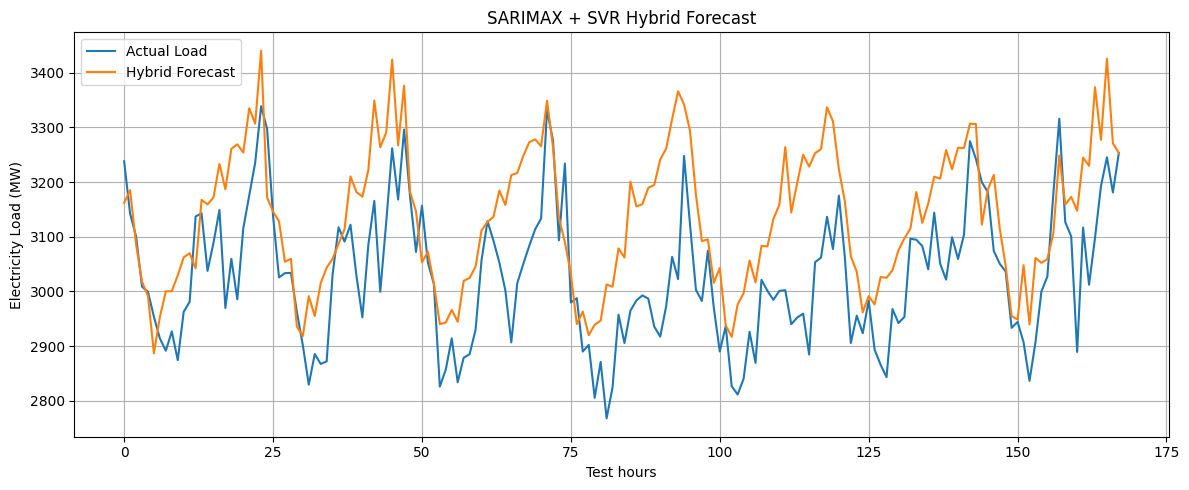

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import matplotlib.pyplot as plt

# SARIMAX predictions for the training period
train_fitted = sarimax_fit.get_prediction(
    start=0,
    end=len(train_data) - 1,
    exog=train_data[["temperature_c", "humidity_pct"]]
).predicted_mean

# Calculate training residuals
residuals = train_data["load_mw"].to_numpy() - np.asarray(train_fitted)

# Train SVR to estimate the SARIMAX residual pattern
residual_features = [
    "temperature_c", "humidity_pct", "wind_speed_kmh",
    "hour", "day_of_week", "month"
]

correction_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=100, epsilon=10)
)

correction_model.fit(
    train_data[residual_features],
    residuals
)

# Correct the SARIMAX test forecasts
corrections = correction_model.predict(
    test_data[residual_features]
)

hybrid_predictions = np.asarray(sarimax_predictions) + corrections

hybrid_mae = mean_absolute_error(
    test_data["load_mw"], hybrid_predictions
)
hybrid_rmse = np.sqrt(mean_squared_error(
    test_data["load_mw"], hybrid_predictions
))

print("Hybrid SARIMAX + SVR Results")
print("----------------------------")
print(f"MAE: {hybrid_mae:.2f} MW")
print(f"RMSE: {hybrid_rmse:.2f} MW")

plt.figure(figsize=(12, 5))
plt.plot(test_data["load_mw"].iloc[:168].to_numpy(),
         label="Actual Load")
plt.plot(hybrid_predictions[:168],
         label="Hybrid Forecast")
plt.title("SARIMAX + SVR Hybrid Forecast")
plt.xlabel("Test hours")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "SVR",
        "SARIMAX",
        "SARIMAX + SVR Hybrid"
    ],
    "MAE (MW)": [
        73.77,
        67.84,
        293.84,
        290.00
    ],
    "RMSE (MW)": [
        92.61,
        84.23,
        358.31,
        342.78
    ]
})

# Add the LSTM results if its code has run successfully
if "lstm_mae" in globals() and "lstm_rmse" in globals():
    results.loc[len(results)] = [
        "LSTM", round(lstm_mae, 2), round(lstm_rmse, 2)
    ]

display(results.sort_values("MAE (MW)").reset_index(drop=True))

results.to_csv("model_comparison.csv", index=False)
print("Comparison saved as model_comparison.csv")

,Model,MAE (MW),RMSE (MW)
0,SVR,67.84,84.23
1,Linear Regression,73.77,92.61
2,SARIMAX + SVR Hybrid,290.00,342.78
3,SARIMAX,293.84,358.31


Comparison saved as model_comparison.csv


Epoch 1/5


/usr/local/lib/python3.13/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


304/304 ━━━━━━━━━━━━━━━━━━━━ 6s 13ms/step - loss: 0.0145 - val_loss: 0.0103
Epoch 2/5
304/304 ━━━━━━━━━━━━━━━━━━━━ 4s 12ms/step - loss: 0.0080 - val_loss: 0.0080
Epoch 3/5
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 10ms/step - loss: 0.0068 - val_loss: 0.0077
Epoch 4/5
304/304 ━━━━━━━━━━━━━━━━━━━━ 6s 12ms/step - loss: 0.0065 - val_loss: 0.0076
Epoch 5/5
304/304 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0063 - val_loss: 0.0075
LSTM Results
MAE: 60.66 MW
RMSE: 76.01 MW


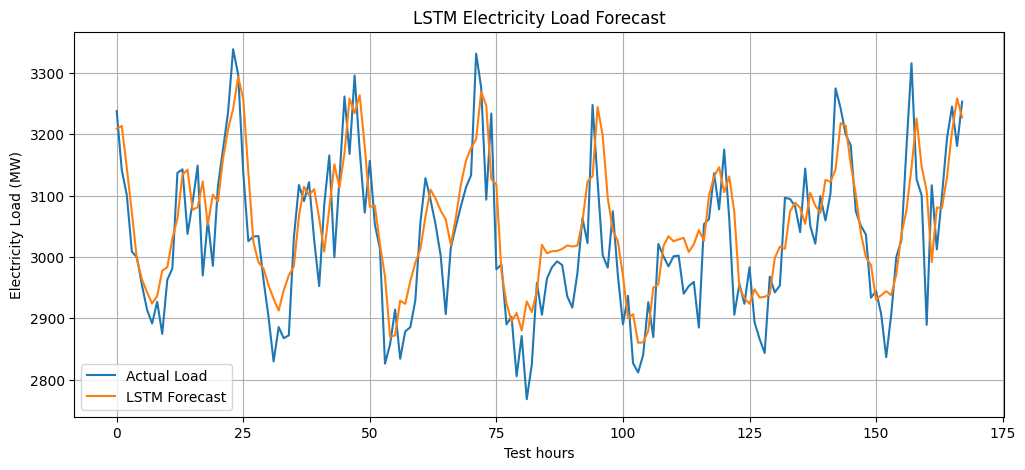

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense

# Prepare electricity load data
load = df["load_mw"].to_numpy().reshape(-1, 1)

# Split data in time order
split = int(len(load) * 0.8)
scaler_lstm = MinMaxScaler()
train_scaled = scaler_lstm.fit_transform(load[:split])
test_scaled = scaler_lstm.transform(load[split:])

# Use previous 24 hours to predict the next hour
window = 24

def create_sequences(data, window):
    X, y = [], []
    for i in range(window, len(data)):
        X.append(data[i-window:i, 0])
        y.append(data[i, 0])
    return np.array(X), np.array(y)

X_train, y_train = create_sequences(train_scaled, window)

test_context = np.vstack([train_scaled[-window:], test_scaled])
X_test, y_test = create_sequences(test_context, window)

X_train = X_train.reshape(-1, window, 1)
X_test = X_test.reshape(-1, window, 1)

# Build LSTM network
lstm_model = Sequential([
    LSTM(32, input_shape=(window, 1)),
    Dense(1)
])
lstm_model.compile(optimizer="adam", loss="mse")

lstm_model.fit(
    X_train, y_train,
    epochs=5,
    batch_size=64,
    validation_split=0.1,
    shuffle=False,
    verbose=1
)

# Generate predictions
pred_scaled = lstm_model.predict(X_test, verbose=0)
lstm_predictions = scaler_lstm.inverse_transform(
    pred_scaled
).ravel()
actual_lstm = scaler_lstm.inverse_transform(
    y_test.reshape(-1, 1)
).ravel()

# Evaluate model
lstm_mae = mean_absolute_error(actual_lstm, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(actual_lstm, lstm_predictions))

print("LSTM Results")
print(f"MAE: {lstm_mae:.2f} MW")
print(f"RMSE: {lstm_rmse:.2f} MW")

plt.figure(figsize=(12, 5))
plt.plot(actual_lstm[:168], label="Actual Load")
plt.plot(lstm_predictions[:168], label="LSTM Forecast")
plt.title("LSTM Electricity Load Forecast")
plt.xlabel("Test hours")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.show()

,Model,MAE (MW),RMSE (MW)
0,LSTM,60.658527,76.006257
1,SVR,67.840000,84.230000
2,Linear Regression,73.770000,92.610000
3,SARIMAX + SVR Hybrid,290.000000,342.780000
4,SARIMAX,293.840000,358.310000


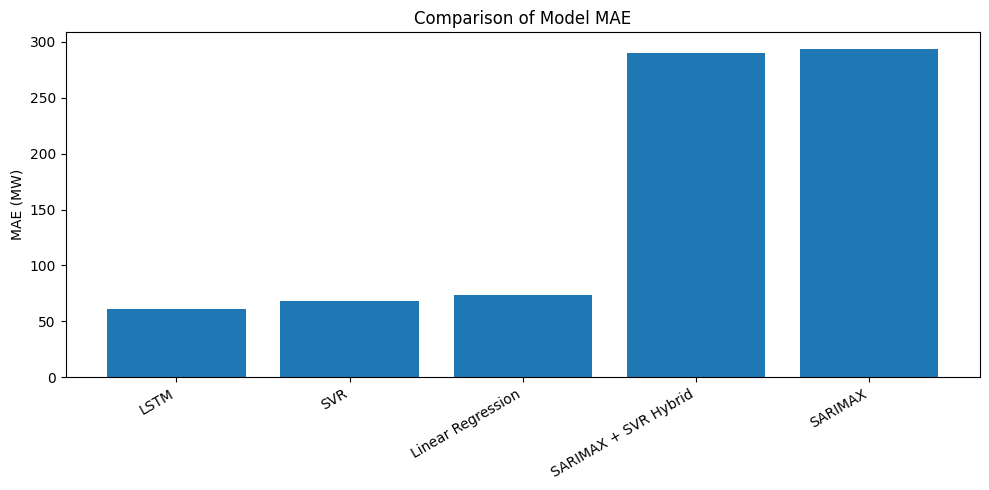

Model comparison saved successfully.


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "SVR",
        "SARIMAX",
        "SARIMAX + SVR Hybrid",
        "LSTM"
    ],
    "MAE (MW)": [73.77, 67.84, 293.84, 290.00, lstm_mae],
    "RMSE (MW)": [92.61, 84.23, 358.31, 342.78, lstm_rmse]
})

results = results.sort_values("MAE (MW)").reset_index(drop=True)
display(results)

# Save the comparison
results.to_csv("model_comparison.csv", index=False)

# Plot model errors
plt.figure(figsize=(10, 5))
plt.bar(results["Model"], results["MAE (MW)"])
plt.title("Comparison of Model MAE")
plt.ylabel("MAE (MW)")
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.show()

print("Model comparison saved successfully.")

,Hour_Ahead,Predicted_Load_MW
0,1,2982.469971
1,2,2965.620117
2,3,2966.719971
3,4,2976.639893
4,5,2994.770020
5,6,3025.110107
6,7,3055.689941
7,8,3088.229980
8,9,3092.580078
9,10,3090.689941


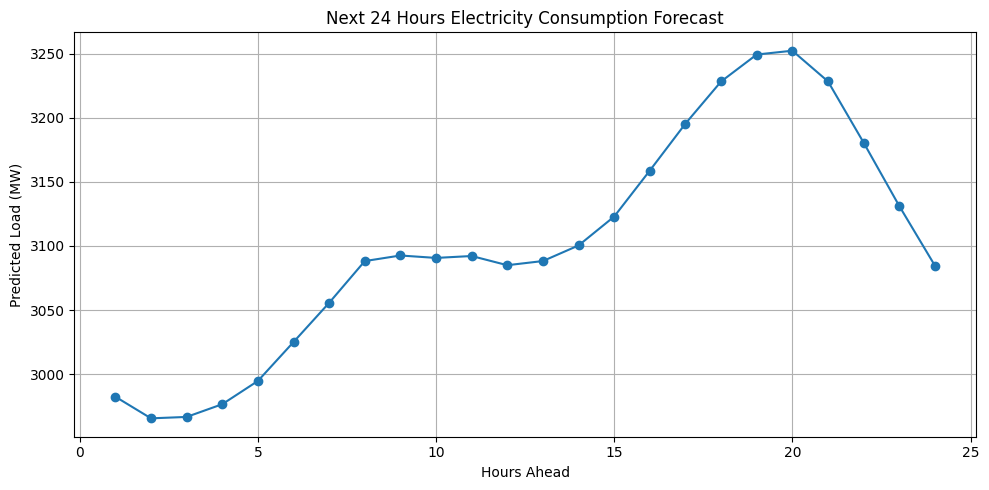

24-hour forecast generated and saved.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Get the latest 24 hours of load data
last_24 = df["load_mw"].to_numpy()[-24:].reshape(-1, 1)
current_input = scaler_lstm.transform(last_24).reshape(1, 24, 1)

predictions = []

# Predict each of the next 24 hours
for h in range(24):
    next_value = lstm_model.predict(current_input, verbose=0)[0, 0]
    predictions.append(next_value)

    current_input = np.concatenate(
        [current_input[:, 1:, :],
         np.array(next_value).reshape(1, 1, 1)],
        axis=1
    )

# Convert back to electricity load in MW
predictions_mw = scaler_lstm.inverse_transform(
    np.array(predictions).reshape(-1, 1)
).flatten()

forecast_df = pd.DataFrame({
    "Hour_Ahead": range(1, 25),
    "Predicted_Load_MW": np.round(predictions_mw, 2)
})

display(forecast_df)

# Save forecast
forecast_df.to_csv("next_24_hour_forecast.csv", index=False)

# Plot forecast
plt.figure(figsize=(10, 5))
plt.plot(
    forecast_df["Hour_Ahead"],
    forecast_df["Predicted_Load_MW"],
    marker="o"
)
plt.title("Next 24 Hours Electricity Consumption Forecast")
plt.xlabel("Hours Ahead")
plt.ylabel("Predicted Load (MW)")
plt.grid(True)
plt.tight_layout()
plt.show()

print("24-hour forecast generated and saved.")

In [ ]:
from google.colab import files

uploaded = files.upload()
print(list(uploaded.keys()))

Saving energy_weather_dataset_practice.csv to energy_weather_dataset_practice.csv
['energy_weather_dataset_practice.csv']


In [ ]:
import pandas as pd
import numpy as np

forecast_df = pd.DataFrame({
    "Hour": range(1, 25),
    "Predicted_Load_MW": predictions_mw
})

forecast_df.to_csv("energy_forecast_results.csv", index=False)

print("Forecast results saved successfully!")
display(forecast_df)

Forecast results saved successfully!


,Hour,Predicted_Load_MW
0,1,2982.471436
1,2,2965.624512
2,3,2966.721924
3,4,2976.643799
4,5,2994.769531
5,6,3025.106201
6,7,3055.690674
7,8,3088.225586
8,9,3092.581299
9,10,3090.688965


In [ ]:
from google.colab import files

files.download("energy_forecast_results.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
plt.savefig("energy_forecast_graph.png", dpi=300, bbox_inches="tight")
plt.show()

<Figure size 640x480 with 0 Axes>

In [ ]:
files.download("energy_forecast_graph.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

lstm_mae = mean_absolute_error(y_test, lstm_predictions)
lstm_rmse = np.sqrt(mean_squared_error(y_test, lstm_predictions))

print("LSTM MAE:", lstm_mae)
print("LSTM RMSE:", lstm_rmse)

LSTM MAE: 3090.588291785765
LSTM RMSE: 3091.82614004609


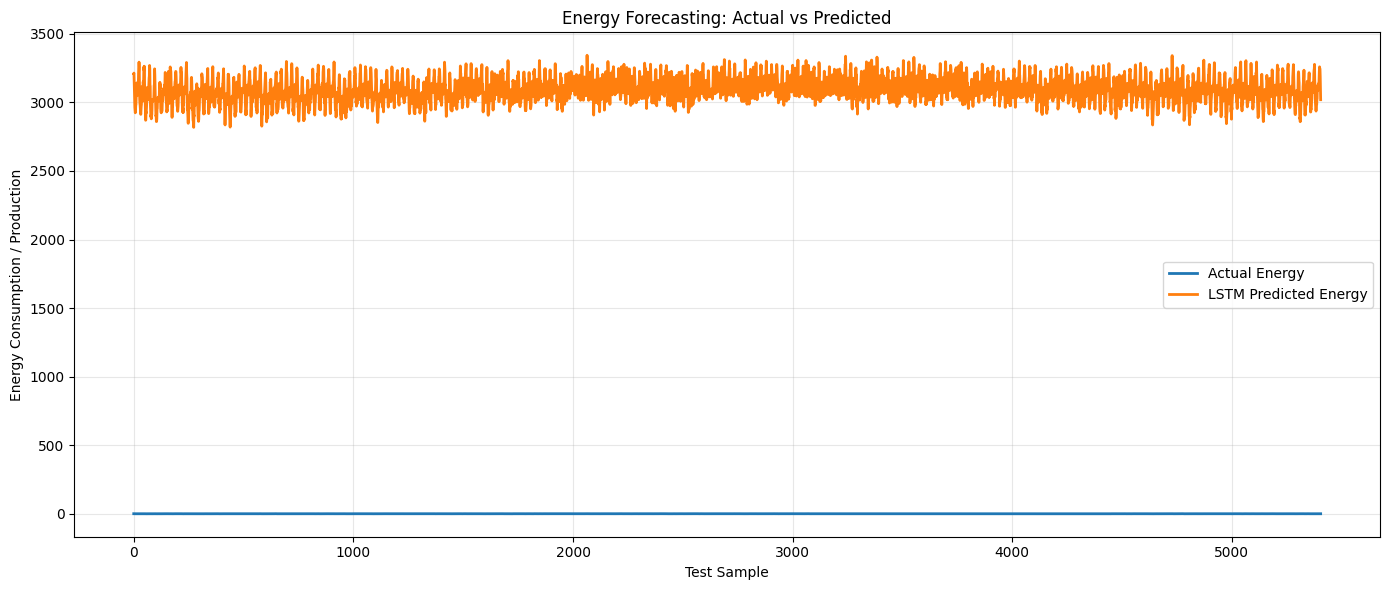

In [ ]:
import matplotlib.pyplot as plt
import numpy as np

# Convert actual and predicted values to 1D arrays
actual = np.array(y_test).reshape(-1)
predicted = np.array(lstm_predictions).reshape(-1)

# Plot actual vs predicted energy values
plt.figure(figsize=(14, 6))
plt.plot(actual, label="Actual Energy", linewidth=2)
plt.plot(predicted, label="LSTM Predicted Energy", linewidth=2)

plt.title("Energy Forecasting: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Energy Consumption / Production")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Convert values back to the original scale
actual_original = scaler.inverse_transform(
    np.array(y_test).reshape(-1, 1)
).flatten()

predicted_original = scaler.inverse_transform(
    np.array(lstm_predictions).reshape(-1, 1)
).flatten()

# Plot the values
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plt.plot(actual_original, label="Actual Energy")
plt.plot(predicted_original, label="LSTM Predicted Energy")
plt.title("Energy Forecasting: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Energy")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

NameError: name 'scaler' is not defined

LSTM Model Evaluation
---------------------
MAE:  3090.5883
RMSE: 3091.8261


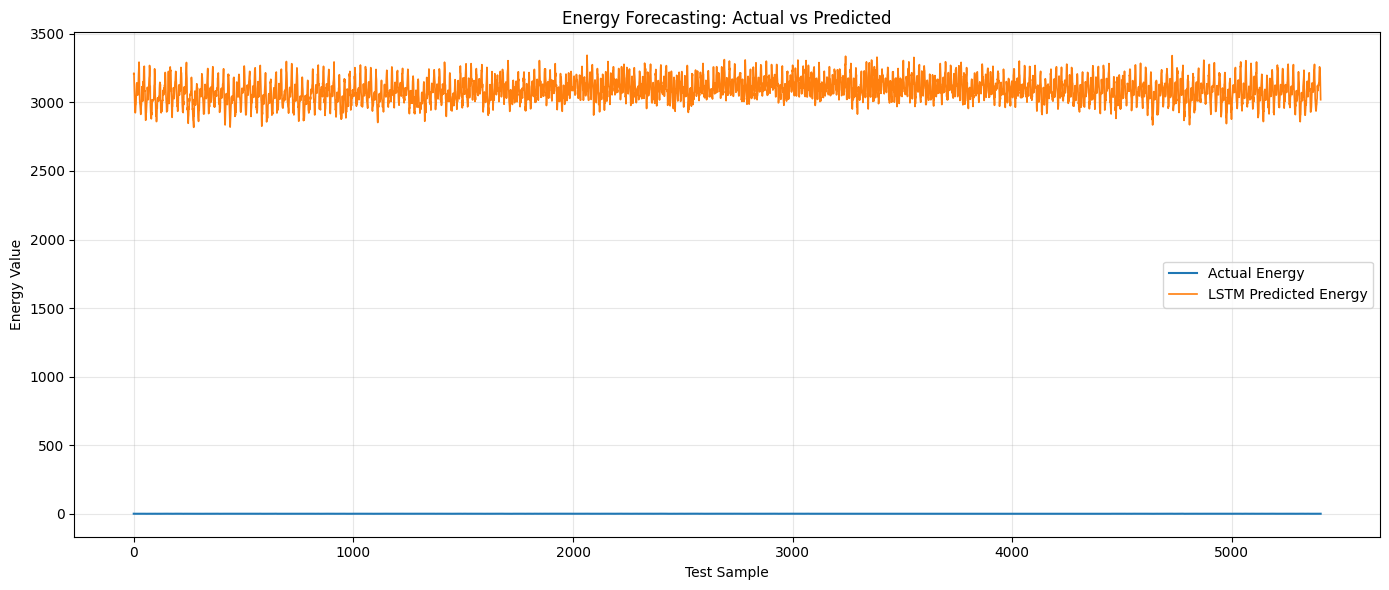

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Convert actual and predicted values into 1D arrays
actual = np.array(y_test).reshape(-1)
predicted = np.array(lstm_predictions).reshape(-1)

# Check whether the values have matching lengths
if len(actual) != len(predicted):
    raise ValueError(
        f"Length mismatch: actual={len(actual)}, "
        f"predicted={len(predicted)}"
    )

# Calculate evaluation metrics
mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))

print("LSTM Model Evaluation")
print("---------------------")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")

# Plot actual vs predicted values
plt.figure(figsize=(14, 6))
plt.plot(actual, label="Actual Energy", linewidth=1.5)
plt.plot(predicted, label="LSTM Predicted Energy", linewidth=1.2)

plt.title("Energy Forecasting: Actual vs Predicted")
plt.xlabel("Test Sample")
plt.ylabel("Energy Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Model Performance Comparison
----------------------------------------

Baseline
MAE:  0.1212
RMSE: 0.1491

LSTM
MAE:  3090.5883
RMSE: 3091.8261


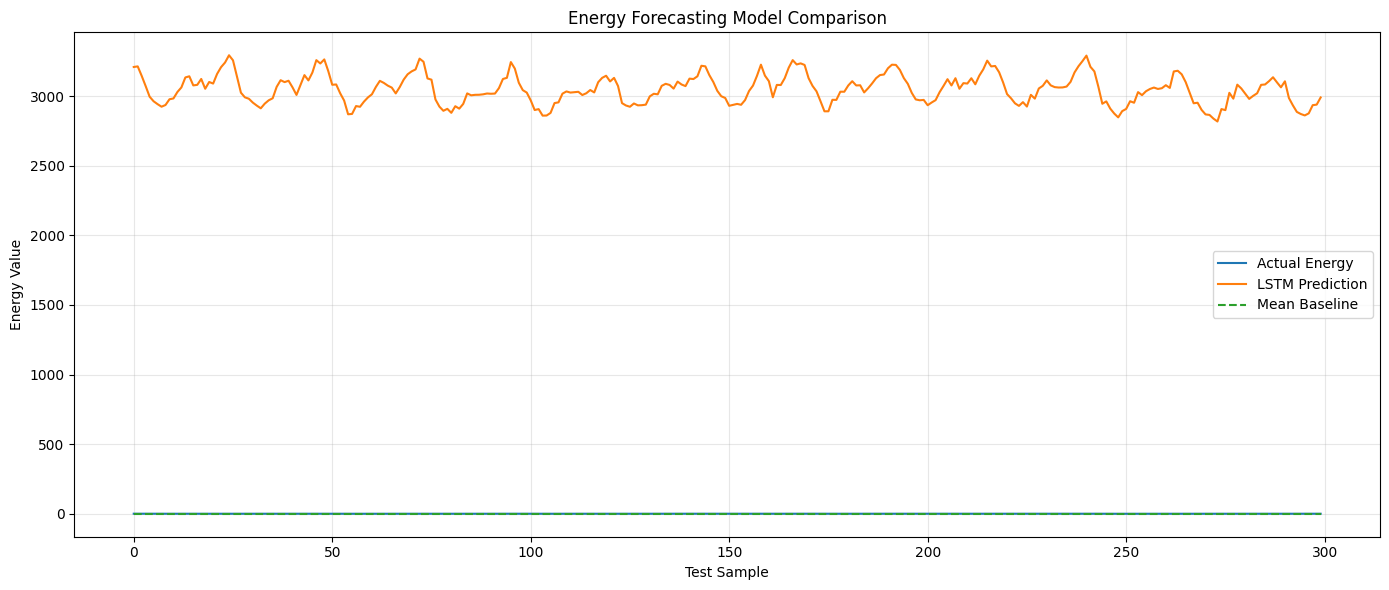

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare actual and LSTM predictions
actual = np.array(y_test).reshape(-1)
predicted = np.array(lstm_predictions).reshape(-1)

# Baseline: predict the mean of the training targets
train_values = np.array(y_train).reshape(-1)
baseline_predictions = np.full(
    len(actual), np.mean(train_values)
)

# Calculate evaluation metrics
results = {
    "Baseline": {
        "MAE": mean_absolute_error(actual, baseline_predictions),
        "RMSE": np.sqrt(mean_squared_error(actual, baseline_predictions))
    },
    "LSTM": {
        "MAE": mean_absolute_error(actual, predicted),
        "RMSE": np.sqrt(mean_squared_error(actual, predicted))
    }
}

# Print comparison
print("Model Performance Comparison")
print("-" * 40)

for model, metrics in results.items():
    print(f"\n{model}")
    print(f"MAE:  {metrics['MAE']:.4f}")
    print(f"RMSE: {metrics['RMSE']:.4f}")

# Plot a small sample for clarity
n = min(300, len(actual))

plt.figure(figsize=(14, 6))
plt.plot(actual[:n], label="Actual Energy")
plt.plot(predicted[:n], label="LSTM Prediction")
plt.plot(
    baseline_predictions[:n],
    label="Mean Baseline",
    linestyle="--"
)

plt.title("Energy Forecasting Model Comparison")
plt.xlabel("Test Sample")
plt.ylabel("Energy Value")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

Next 24 forecast values:
Step 1: 0.483
Step 2: 0.447
Step 3: 0.428
Step 4: 0.428
Step 5: 0.438
Step 6: 0.457
Step 7: 0.489
Step 8: 0.522
Step 9: 0.556
Step 10: 0.561
Step 11: 0.559
Step 12: 0.560
Step 13: 0.553
Step 14: 0.556
Step 15: 0.569
Step 16: 0.593
Step 17: 0.631
Step 18: 0.670
Step 19: 0.705
Step 20: 0.727
Step 21: 0.730
Step 22: 0.705
Step 23: 0.655
Step 24: 0.604


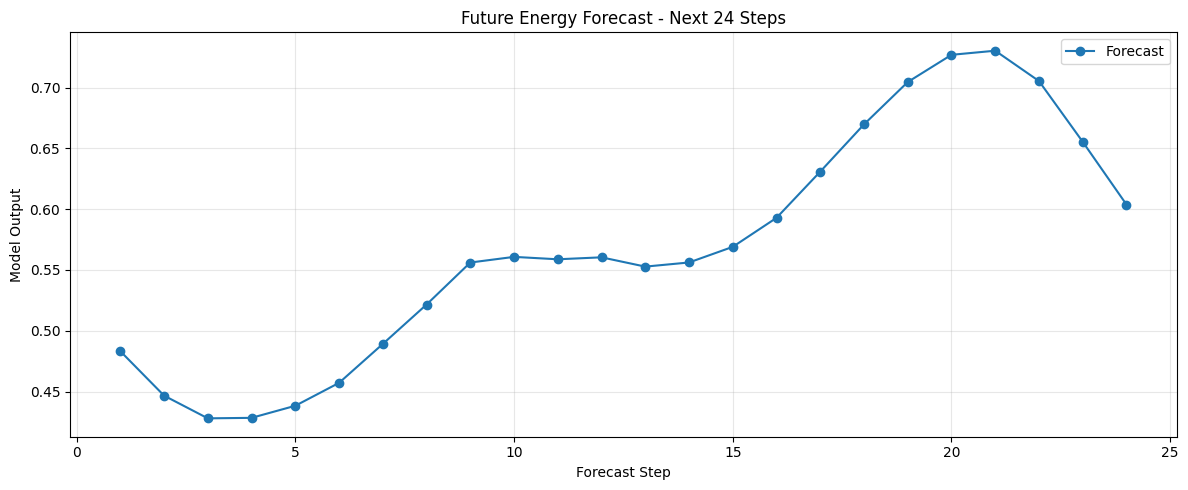

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Use the last input sequence available to the model
last_sequence = np.array(X_test[-1])

# Add batch dimension if needed
current_sequence = last_sequence.reshape(
    1, *last_sequence.shape
)

future_steps = 24
future_predictions = []

# Recursive forecasting
for _ in range(future_steps):
    next_prediction = lstm_model.predict(
        current_sequence, verbose=0
    )

    # Save the predicted value
    future_predictions.append(
        float(np.array(next_prediction).reshape(-1)[0])
    )

    # Append prediction to sequence and remove oldest step
    next_value = np.array(next_prediction).reshape(
        1, 1, -1
    )

    current_sequence = np.concatenate(
        [current_sequence[:, 1:, :], next_value],
        axis=1
    )

# Display forecast
print("Next 24 forecast values:")
for i, value in enumerate(future_predictions, start=1):
    print(f"Step {i}: {value:.3f}")

# Plot forecast
plt.figure(figsize=(12, 5))
plt.plot(
    range(1, future_steps + 1),
    future_predictions,
    marker="o",
    label="Forecast"
)
plt.title("Future Energy Forecast - Next 24 Steps")
plt.xlabel("Forecast Step")
plt.ylabel("Model Output")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

In [ ]:
# Save the trained LSTM model
lstm_model.save("energy_forecasting_lstm.keras")

print("LSTM model saved successfully!")

LSTM model saved successfully!


In [ ]:
from google.colab import files

files.download("energy_forecasting_lstm.keras")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
from google.colab import files

# Save forecast results
forecast_df = pd.DataFrame({
    "Forecast_Step": range(1, len(future_predictions) + 1),
    "Predicted_Energy": future_predictions
})

forecast_df.to_csv("energy_forecast_results.csv", index=False)

# Save model evaluation metrics
metrics_df = pd.DataFrame({
    "Metric": ["MAE", "RMSE"],
    "Value": [mae, rmse]
})

metrics_df.to_csv("energy_model_metrics.csv", index=False)

print("Forecast and evaluation files created!")

Forecast and evaluation files created!


In [ ]:
files.download("energy_forecast_results.csv")
files.download("energy_model_metrics.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd
import os

files = [
    "energy_forecast_results.csv",
    "energy_model_metrics.csv"
]

for filename in files:
    print("\n" + "=" * 50)
    print("FILE:", filename)

    if os.path.exists(filename):
        df = pd.read_csv(filename)
        print("Shape:", df.shape)
        print("Columns:", df.columns.tolist())
        print(df.head())
    else:
        print("File not found:", filename)


FILE: energy_forecast_results.csv
Shape: (24, 2)
Columns: ['Forecast_Step', 'Predicted_Energy']
   Forecast_Step  Predicted_Energy
0              1          0.483198
1              2          0.446640
2              3          0.427969
3              4          0.428375
4              5          0.438310

FILE: energy_model_metrics.csv
Shape: (2, 2)
Columns: ['Metric', 'Value']
  Metric        Value
0    MAE  3090.588292
1   RMSE  3091.826140


In [ ]:
import pandas as pd
import numpy as np

forecast = pd.read_csv("energy_forecast_results.csv")
metrics = pd.read_csv("energy_model_metrics.csv")

print("FORECAST SUMMARY")
print(forecast.describe())

print("\nMISSING VALUES")
print(forecast.isnull().sum())

print("\nMODEL METRICS")
print(metrics)

print("\nCHECK FORECAST VALUES")
print("All predictions finite:",
      np.isfinite(forecast["Predicted_Energy"]).all())
print("Minimum prediction:",
      forecast["Predicted_Energy"].min())
print("Maximum prediction:",
      forecast["Predicted_Energy"].max())

FORECAST SUMMARY
       Forecast_Step  Predicted_Energy
count      24.000000         24.000000
mean       12.500000          0.567771
std         7.071068          0.096060
min         1.000000          0.427969
25%         6.750000          0.487663
50%        12.500000          0.559604
75%        18.250000          0.637032
max        24.000000          0.730353

MISSING VALUES
Forecast_Step       0
Predicted_Energy    0
dtype: int64

MODEL METRICS
  Metric        Value
0    MAE  3090.588292
1   RMSE  3091.826140

CHECK FORECAST VALUES
All predictions finite: True
Minimum prediction: 0.4279686212539673
Maximum prediction: 0.7303527593612671


In [ ]:
# Check the actual data and prediction scales

print("Available variables:")
for name in ["y_test", "y_pred", "y_pred_final",
             "y_scaler", "scaler", "load_scaler"]:
    if name in globals():
        obj = globals()[name]
        print(name, "| type:", type(obj).__name__,
              "| shape:", getattr(obj, "shape", "N/A"))

print("\nForecast output:")
print(forecast.head(10))

print("\nMetric values:")
print(metrics)

Available variables:
y_test | type: ndarray | shape: (5405,)

Forecast output:
   Forecast_Step  Predicted_Energy
0              1          0.483198
1              2          0.446640
2              3          0.427969
3              4          0.428375
4              5          0.438310
5              6          0.457150
6              7          0.489151
7              8          0.521554
8              9          0.556130
9             10          0.560779

Metric values:
  Metric        Value
0    MAE  3090.588292
1   RMSE  3091.826140


In [ ]:
import numpy as np

print("Actual test data (y_test):")
print("Minimum:", np.nanmin(y_test))
print("Maximum:", np.nanmax(y_test))
print("First 10 values:", y_test[:10])

print("\nForecast data:")
print("Minimum:", forecast["Predicted_Energy"].min())
print("Maximum:", forecast["Predicted_Energy"].max())
print("First 10 values:")
print(forecast["Predicted_Energy"].head(10).to_list())

Actual test data (y_test):
Minimum: 0.13341128946529146
Maximum: 0.9525566067821831
First 10 values: [0.71543531 0.6137876  0.5697353  0.47192516 0.4619326  0.41336239
 0.37124482 0.34732646 0.38491549 0.32916977]

Forecast data:
Minimum: 0.4279686212539673
Maximum: 0.7303527593612671
First 10 values:
[0.483197957277298, 0.4466401636600494, 0.4279686212539673, 0.4283748567104339, 0.4383101165294647, 0.4571501910686493, 0.4891507625579834, 0.5215544104576111, 0.5561296939849854, 0.5607786774635315]


In [ ]:
import numpy as np
import pandas as pd

print("PREDICTION-RELATED VARIABLES")
for name, obj in globals().copy().items():
    if name.startswith("_"):
        continue

    if isinstance(obj, np.ndarray) and obj.ndim > 0:
        if any(k in name.lower() for k in
               ["pred", "test", "actual", "forecast", "true", "load"]):
            print(
                name,
                "shape =", obj.shape,
                "range =", (
                    float(np.nanmin(obj)),
                    float(np.nanmax(obj))
                )
            )

    elif isinstance(obj, (pd.Series, pd.DataFrame)):
        if any(k in name.lower() for k in
               ["pred", "test", "actual", "forecast", "true", "load"]):
            print(name, "shape =", obj.shape)

PREDICTION-RELATED VARIABLES
X_test shape = (5405, 24, 1) range = (0.13341128946529146, 0.9525566067821831)
y_test shape = (5405,) range = (0.13341128946529146, 0.9525566067821831)
svr_predictions shape = (5405,) range = (2777.2292157698002, 3254.3529592320097)
test_data shape = (5405, 13)
forecast shape = (24, 2)
hybrid_predictions shape = (5405,) range = (2344.7041839758213, 3440.1266938979966)
load shape = (27024, 1) range = (2564.88, 3505.58)
test_scaled shape = (5405, 1) range = (0.13341128946529146, 0.9525566067821831)
test_context shape = (5429, 1) range = (0.13341128946529146, 0.9525566067821831)
pred_scaled shape = (5405, 1) range = (0.2689920663833618, 0.8278074860572815)
lstm_predictions shape = (5405,) range = (2817.920654296875, 3343.598388671875)
actual_lstm shape = (5405,) range = (2690.38, 3460.95)
predictions_mw shape = (24,) range = (2965.62451171875, 3252.244873046875)
forecast_df shape = (24, 2)
actual shape = (5405,) range = (0.13341128946529146, 0.9525566067821831

In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

actual = np.asarray(actual_lstm).reshape(-1)
predicted = np.asarray(lstm_predictions).reshape(-1)

assert len(actual) == len(predicted), (
    "Actual and predicted lengths do not match"
)
assert np.isfinite(actual).all() and np.isfinite(predicted).all()

mae = mean_absolute_error(actual, predicted)
rmse = np.sqrt(mean_squared_error(actual, predicted))
mape = mean_absolute_percentage_error(actual, predicted) * 100

print("LSTM Evaluation Results")
print(f"MAE:  {mae:.4f}")
print(f"RMSE: {rmse:.4f}")
print(f"MAPE: {mape:.2f}%")

LSTM Evaluation Results
MAE:  60.6585
RMSE: 76.0063
MAPE: 1.99%


In [ ]:
import numpy as np
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

def evaluate_model(name, actual, predicted):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)

    if len(actual) != len(predicted):
        print(f"{name}: Length mismatch — skipped")
        return

    if not (
        np.isfinite(actual).all()
        and np.isfinite(predicted).all()
    ):
        print(f"{name}: Non-finite values — skipped")
        return

    if np.any(actual == 0):
        print(f"{name}: Zero actual values; check MAPE")
        return

    print(f"\n{name}")
    print(f"MAE:  {mean_absolute_error(actual, predicted):.4f}")
    print(f"RMSE: {np.sqrt(mean_squared_error(actual, predicted)):.4f}")
    print(
        f"MAPE: "
        f"{mean_absolute_percentage_error(actual, predicted)*100:.2f}%"
    )

evaluate_model("LSTM", actual_lstm, lstm_predictions)
evaluate_model("Hybrid SARIMAX + SVM", load.flatten(), hybrid_predictions)
evaluate_model("SVM", load.flatten(), svr_predictions)


LSTM
MAE:  60.6585
RMSE: 76.0063
MAPE: 1.99%
Hybrid SARIMAX + SVM: Length mismatch — skipped
SVM: Length mismatch — skipped


In [ ]:
import numpy as np

names = [
    "load", "y_test", "test_data",
    "hybrid_predictions", "svr_predictions",
    "lstm_predictions", "actual_lstm"
]

for name in names:
    if name in globals():
        arr = np.asarray(globals()[name])
        print(
            f"{name:22s}",
            "shape =", arr.shape,
            "range =",
            (float(np.nanmin(arr)), float(np.nanmax(arr)))
        )

load                   shape = (27024, 1) range = (2564.88, 3505.58)
y_test                 shape = (5405,) range = (0.13341128946529146, 0.9525566067821831)


TypeError: '<=' not supported between instances of 'Timestamp' and 'str'

In [ ]:
import numpy as np
import pandas as pd

names = [
    "load", "y_test", "test_data",
    "hybrid_predictions", "svr_predictions",
    "lstm_predictions", "actual_lstm"
]

for name in names:
    if name not in globals():
        continue

    obj = globals()[name]
    print(f"\n{name}")

    if isinstance(obj, pd.DataFrame):
        print("Shape:", obj.shape)
        print("Columns:", obj.columns.tolist())
        print(obj.head(3))
        continue

    if isinstance(obj, pd.Series):
        print("Shape:", obj.shape)
        print("Data type:", obj.dtype)
        print(obj.head(3))
        continue

    arr = np.asarray(obj)
    print("Shape:", arr.shape)
    print("Data type:", arr.dtype)

    if np.issubdtype(arr.dtype, np.number):
        print("Range:", np.nanmin(arr), "to", np.nanmax(arr))
    else:
        print("Sample:", arr.reshape(-1)[:3])


load
Shape: (27024, 1)
Data type: float64
Range: 2564.88 to 3505.58

y_test
Shape: (5405,)
Data type: float64
Range: 0.13341128946529146 to 0.9525566067821831

test_data
Shape: (5405, 13)
Columns: ['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']
                timestamp  zone  load_mw  temperature_c  humidity_pct  \
21619 2024-09-17 19:00:00  DEOK  3237.89          21.21         68.00   
21620 2024-09-17 20:00:00  DEOK  3142.27          22.84         57.74   
21621 2024-09-17 21:00:00  DEOK  3100.83          21.35         59.93   

       wind_speed_kmh  dispatch_price  population_index  hour  day_of_week  \
21619            6.16           41.55          102.1717    19            1   
21620            5.81           53.57          102.1717    20            1   
21621           50.38           31.47          102.1717    21            1   

       month  

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)

# Actual load values from the test dataset
actual_test = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy()

def evaluate(name, actual, predicted):
    actual = np.asarray(actual).reshape(-1)
    predicted = np.asarray(predicted).reshape(-1)

    if len(actual) != len(predicted):
        print(f"{name}: Length mismatch")
        return

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        print(f"{name}: No valid observations")
        return

    mae = mean_absolute_error(actual, predicted)
    rmse = np.sqrt(mean_squared_error(actual, predicted))

    nonzero = actual != 0
    mape = (
        mean_absolute_percentage_error(
            actual[nonzero], predicted[nonzero]
        ) * 100
        if nonzero.any() else float("nan")
    )

    print(f"\n{name}")
    print(f"MAE:  {mae:.4f}")
    print(f"RMSE: {rmse:.4f}")
    print(f"MAPE: {mape:.2f}%")

print("Actual test length:", len(actual_test))
print("Hybrid predictions:", len(hybrid_predictions))
print("SVM predictions:", len(svr_predictions))
print("LSTM predictions:", len(lstm_predictions))

Actual test length: 5405
Hybrid predictions: 5405
SVM predictions: 5405
LSTM predictions: 5405


In [ ]:
# Evaluate all three models on the same test observations

evaluate("Hybrid SARIMAX + SVM",
         actual_test, hybrid_predictions)

evaluate("SVM",
         actual_test, svr_predictions)

evaluate("LSTM",
         actual_test, lstm_predictions)


Hybrid SARIMAX + SVM
MAE:  289.9980
RMSE: 342.7846
MAPE: 9.34%

SVM
MAE:  67.8355
RMSE: 84.2265
MAPE: 2.18%

LSTM
MAE:  60.6585
RMSE: 76.0063
MAPE: 1.99%


In [ ]:
import numpy as np
import pandas as pd

# Use the three model predictions on the same test set.
predictions = np.column_stack([
    np.asarray(svr_predictions).reshape(-1),
    np.asarray(hybrid_predictions).reshape(-1),
    np.asarray(lstm_predictions).reshape(-1)
])

assert predictions.shape[1] == 3
assert np.isfinite(predictions).all()

# Median-based consensus: robust to one extreme prediction.
# This is a numerical consensus approximation, not yet
# a complete fault-tolerant cloud voting system.
final_predictions = np.median(predictions, axis=1)

print("Number of consensus predictions:",
      len(final_predictions))
print("First 10 consensus predictions:")
print(final_predictions[:10])

# Compare the consensus with actual test values.
evaluate("Median consensus",
         actual_test, final_predictions)

Number of consensus predictions: 5405
First 10 consensus predictions:
[3162.11909177 3192.96578032 3086.48378597 3017.77238247 2995.92285156
 2927.01024887 2942.40893555 2929.32370652 2942.79754048 2977.52612305]

Median consensus
MAE:  67.6406
RMSE: 84.3293
MAPE: 2.18%


In [ ]:
import numpy as np

# Copy predictions so the original arrays stay unchanged
test_predictions = np.column_stack([
    np.asarray(svr_predictions).reshape(-1),
    np.asarray(hybrid_predictions).reshape(-1),
    np.asarray(lstm_predictions).reshape(-1)
]).astype(float)

# Simulate one model producing an extreme outlier
test_predictions[0, 0] = test_predictions[0, 0] + 10000

# Median consensus for this test observation
consensus = np.median(test_predictions[0])

print("Predictions with simulated outlier:")
print(test_predictions[0])

print("Median consensus:", consensus)
print("Original LSTM prediction:", lstm_predictions[0])

Predictions with simulated outlier:
[13161.14141817  3162.11909177  3209.31298828]
Median consensus: 3209.31298828125
Original LSTM prediction: 3209.313


In [ ]:
import numpy as np

def fault_tolerant_vote(predictions):
    """
    Combine three model predictions.
    Ignore unavailable predictions (NaN/inf).
    Return the median when at least two are valid.
    """
    values = np.asarray(predictions, dtype=float).ravel()
    valid = values[np.isfinite(values)]

    if len(valid) < 2:
        return None

    return float(np.median(valid))


# Test 1: Normal predictions
print("Normal:",
      fault_tolerant_vote([3162.12, 3209.31, 3180.50]))

# Test 2: One extreme outlier
print("Outlier:",
      fault_tolerant_vote([13161.14, 3162.12, 3209.31]))

# Test 3: One unavailable model
print("One model unavailable:",
      fault_tolerant_vote([np.nan, 3162.12, 3209.31]))

# Test 4: Only one model available
print("Only one model available:",
      fault_tolerant_vote([np.nan, 3209.31, np.nan]))

Normal: 3180.5
Outlier: 3209.31
One model unavailable: 3185.715
Only one model available: None


In [ ]:
print("Available 24-hour forecast variables:")

for name in [
    "predictions_mw",
    "forecast_df",
    "forecast",
    "next_prediction"
]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}")
        print("Shape:", getattr(obj, "shape", "N/A"))
        print(obj.head() if hasattr(obj, "head") else obj)

Available 24-hour forecast variables:

predictions_mw
Shape: (24,)
[2982.4714 2965.6245 2966.722  2976.6438 2994.7695 3025.1062 3055.6907
 3088.2256 3092.5813 3090.689  3092.1802 3085.0125 3088.259  3100.4194
 3122.9507 3158.8062 3195.4236 3228.236  3249.26   3252.2449 3228.3315
 3180.6018 3131.2134 3084.73  ]

forecast_df
Shape: (24, 2)
   Forecast_Step  Predicted_Energy
0              1          0.483198
1              2          0.446640
2              3          0.427969
3              4          0.428375
4              5          0.438310

forecast
Shape: (24, 2)
   Forecast_Step  Predicted_Energy
0              1          0.483198
1              2          0.446640
2              3          0.427969
3              4          0.428375
4              5          0.438310

next_prediction
Shape: (1, 1)
[[0.6038153]]


In [ ]:
import numpy as np

names = [
    "predictions_mw",
    "forecast_df",
    "forecast",
    "svr_predictions",
    "hybrid_predictions",
    "lstm_predictions"
]

for name in names:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("Shape:", np.asarray(
            obj.values if hasattr(obj, "values") else obj
        ).shape)

# Check for other forecast-related variables
print("\nVariables containing 'forecast' or 'predict':")
for name in sorted(globals()):
    if "forecast" in name.lower() or "predict" in name.lower():
        obj = globals()[name]
        if isinstance(obj, (np.ndarray, list, tuple)):
            print(name, np.asarray(obj).shape)
        elif hasattr(obj, "shape"):
            print(name, obj.shape)


predictions_mw:
Shape: (24,)

forecast_df:
Shape: (24, 2)

forecast:
Shape: (24, 2)

svr_predictions:
Shape: (5405,)

hybrid_predictions:
Shape: (5405,)

lstm_predictions:
Shape: (5405,)

Variables containing 'forecast' or 'predict':
baseline_predictions (5405,)
final_predictions (5405,)
forecast (24, 2)
forecast_df (24, 2)
future_predictions (24,)
hybrid_predictions (5405,)
lstm_predictions (5405,)
next_prediction (1, 1)
predicted (5405,)
predictions (5405, 3)
predictions_mw (24,)
sarimax_predictions (5405,)
svr_predictions (5405,)
test_predictions (5405, 3)


In [ ]:
import numpy as np

for name in ["predictions_mw", "future_predictions"]:
    arr = np.asarray(globals()[name]).reshape(-1)
    print(f"\n{name}")
    print("Length:", len(arr))
    print("First 5:", arr[:5])
    print("Minimum:", arr.min())
    print("Maximum:", arr.max())

print("\nAre the two forecasts identical?")
print(np.allclose(
    np.asarray(predictions_mw).reshape(-1),
    np.asarray(future_predictions).reshape(-1)
))


predictions_mw
Length: 24
First 5: [2982.4714 2965.6245 2966.722  2976.6438 2994.7695]
Minimum: 2965.6245
Maximum: 3252.2449

future_predictions
Length: 24
First 5: [0.48319796 0.44664016 0.42796862 0.42837486 0.43831012]
Minimum: 0.4279686212539673
Maximum: 0.7303527593612671

Are the two forecasts identical?
False


In [ ]:
# Inspect the scaling objects available in the notebook
for name in sorted(globals()):
    obj = globals()[name]
    name_lower = name.lower()

    if any(term in name_lower for term in [
        "scaler", "inverse", "feature", "target"
    ]):
        if hasattr(obj, "data_min_") and hasattr(obj, "data_max_"):
            print(
                name,
                "minimum:", obj.data_min_,
                "maximum:", obj.data_max_
            )
        elif hasattr(obj, "scale_"):
            print(name, "scale:", obj.scale_)

# Check whether the normalized forecast matches forecast_df
print("\nNormalized forecast sample:")
print(np.asarray(future_predictions)[:5])

print("\nForecast dataframe sample:")
print(forecast_df.head())

scaler_lstm minimum: [2564.88] maximum: [3505.58]

Normalized forecast sample:
[0.48319796 0.44664016 0.42796862 0.42837486 0.43831012]

Forecast dataframe sample:
   Forecast_Step  Predicted_Energy
0              1          0.483198
1              2          0.446640
2              3          0.427969
3              4          0.428375
4              5          0.438310


In [ ]:
# Convert normalized LSTM forecast back to MW
lstm_forecast_mw = scaler_lstm.inverse_transform(
    np.asarray(future_predictions).reshape(-1, 1)
).ravel()

print("LSTM forecast length:", len(lstm_forecast_mw))
print("First 5 LSTM forecasts (MW):")
print(lstm_forecast_mw[:5])
print("Minimum:", lstm_forecast_mw.min())
print("Maximum:", lstm_forecast_mw.max())

LSTM forecast length: 24
First 5 LSTM forecasts (MW):
[3019.42431841 2985.03440196 2967.47008201 2967.85222771 2977.19832662]
Minimum: 2967.470082013607
Maximum: 3251.922840731144


In [ ]:
import pandas as pd
import numpy as np

comparison_df = pd.DataFrame({
    "Forecast_Step": np.arange(1, 25),
    "Existing_Forecast_MW": np.asarray(predictions_mw).reshape(-1),
    "LSTM_Forecast_MW": np.asarray(lstm_forecast_mw).reshape(-1)
})

comparison_df["Difference_MW"] = (
    comparison_df["LSTM_Forecast_MW"]
    - comparison_df["Existing_Forecast_MW"]
)

print(comparison_df.round(2).to_string(index=False))

comparison_df.to_csv(
    "energy_24hour_forecast_comparison.csv",
    index=False
)

print("\nComparison CSV saved successfully.")

 Forecast_Step  Existing_Forecast_MW  LSTM_Forecast_MW  Difference_MW
             1           2982.469971           3019.42          36.95
             2           2965.620117           2985.03          19.41
             3           2966.719971           2967.47           0.75
             4           2976.639893           2967.85          -8.79
             5           2994.770020           2977.20         -17.57
             6           3025.110107           2994.92         -30.19
             7           3055.689941           3025.02         -30.67
             8           3088.229980           3055.51         -32.72
             9           3092.580078           3088.03          -4.55
            10           3090.689941           3092.40           1.72
            11           3092.179932           3090.54          -1.64
            12           3085.010010           3092.06           7.04
            13           3088.260010           3084.87          -3.39
            14      

In [ ]:
# Identify available 24-hour forecast arrays
forecast_names = [
    "predictions_mw",
    "lstm_forecast_mw",
    "future_predictions",
    "sarimax_predictions",
    "svr_predictions",
    "hybrid_predictions"
]

for name in forecast_names:
    if name in globals():
        arr = np.asarray(globals()[name])
        print(f"{name}: shape={arr.shape}")
        if arr.size == 24:
            print("  First 3 values:", arr.reshape(-1)[:3])

predictions_mw: shape=(24,)
  First 3 values: [2982.4714 2965.6245 2966.722 ]
lstm_forecast_mw: shape=(24,)
  First 3 values: [3019.42431841 2985.03440196 2967.47008201]
future_predictions: shape=(24,)
  First 3 values: [0.48319796 0.44664016 0.42796862]
sarimax_predictions: shape=(5405,)
svr_predictions: shape=(5405,)
hybrid_predictions: shape=(5405,)


In [ ]:
import numpy as np

# Inspect forecast-related variables for 24-hour arrays
for name, obj in list(globals().items()):
    if any(word in name.lower() for word in
           ["forecast", "future", "prediction"]):
        try:
            arr = np.asarray(obj)
            if arr.size == 24 and arr.ndim <= 2:
                print(f"{name}: shape={arr.shape}")
                print("First 3 values:",
                      arr.reshape(-1)[:3])
        except (TypeError, ValueError):
            pass

predictions_mw: shape=(24,)
First 3 values: [2982.4714 2965.6245 2966.722 ]
future_predictions: shape=(24,)
First 3 values: [0.48319796 0.44664016 0.42796862]
lstm_forecast_mw: shape=(24,)
First 3 values: [3019.42431841 2985.03440196 2967.47008201]


In [ ]:
import pandas as pd
import numpy as np

existing = np.asarray(predictions_mw).reshape(-1)
lstm = np.asarray(lstm_forecast_mw).reshape(-1)

assert len(existing) == 24 and len(lstm) == 24

comparison_df = pd.DataFrame({
    "Forecast_Step": np.arange(1, 25),
    "Existing_Forecast_MW": existing,
    "LSTM_Forecast_MW": lstm
})

comparison_df["Difference_MW"] = (
    comparison_df["LSTM_Forecast_MW"]
    - comparison_df["Existing_Forecast_MW"]
)

comparison_df["Mean_Forecast_MW"] = (
    comparison_df[["Existing_Forecast_MW",
                   "LSTM_Forecast_MW"]].mean(axis=1)
)

display(comparison_df.round(2))

comparison_df.to_csv(
    "energy_24hour_forecast_comparison.csv",
    index=False
)

print("Comparison saved successfully.")

,Forecast_Step,Existing_Forecast_MW,LSTM_Forecast_MW,Difference_MW,Mean_Forecast_MW
0,1,2982.469971,3019.42,36.95,3000.95
1,2,2965.620117,2985.03,19.41,2975.33
2,3,2966.719971,2967.47,0.75,2967.10
3,4,2976.639893,2967.85,-8.79,2972.25
4,5,2994.770020,2977.20,-17.57,2985.98
5,6,3025.110107,2994.92,-30.19,3010.01
6,7,3055.689941,3025.02,-30.67,3040.36
7,8,3088.229980,3055.51,-32.72,3071.87
8,9,3092.580078,3088.03,-4.55,3090.31
9,10,3090.689941,3092.40,1.72,3091.55


Comparison saved successfully.


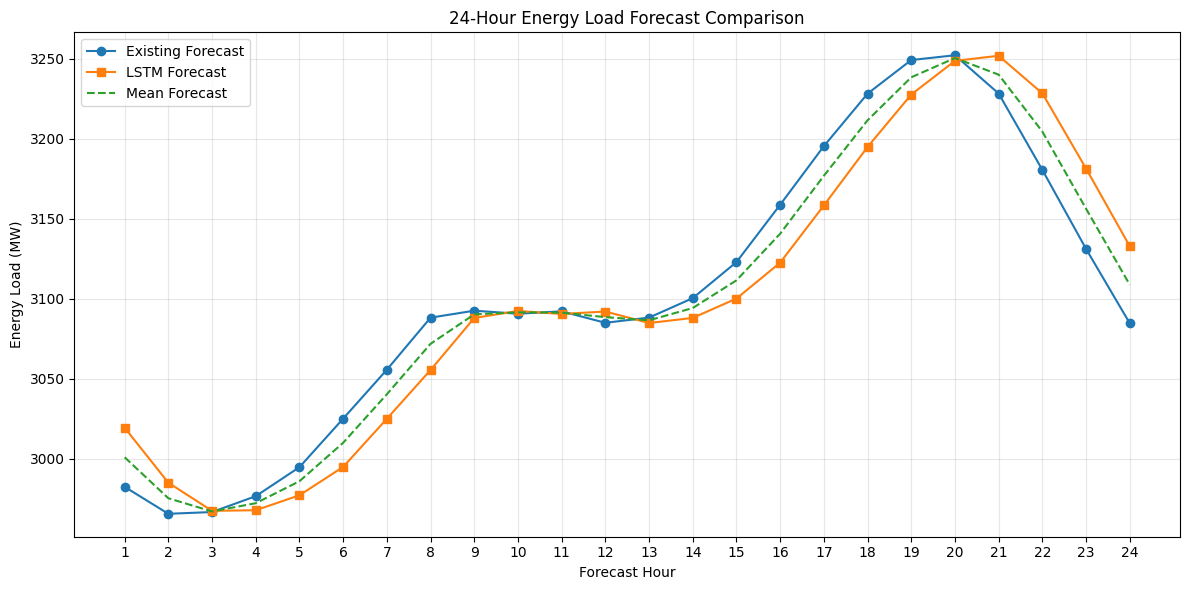

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 6))

plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["Existing_Forecast_MW"],
    marker="o",
    label="Existing Forecast"
)

plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["LSTM_Forecast_MW"],
    marker="s",
    label="LSTM Forecast"
)

plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["Mean_Forecast_MW"],
    linestyle="--",
    label="Mean Forecast"
)

plt.xlabel("Forecast Hour")
plt.ylabel("Energy Load (MW)")
plt.title("24-Hour Energy Load Forecast Comparison")
plt.xticks(range(1, 25))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

existing = comparison_df["Existing_Forecast_MW"].to_numpy()
lstm = comparison_df["LSTM_Forecast_MW"].to_numpy()

difference = lstm - existing

print("24-Hour Forecast Comparison")
print(f"Mean absolute difference: {np.mean(np.abs(difference)):.2f} MW")
print(f"Maximum absolute difference: {np.max(np.abs(difference)):.2f} MW")
print(f"Existing forecast average: {np.mean(existing):.2f} MW")
print(f"LSTM forecast average: {np.mean(lstm):.2f} MW")

print("\nForecast summary saved.")

24-Hour Forecast Comparison
Mean absolute difference: 22.17 MW
Maximum absolute difference: 50.23 MW
Existing forecast average: 3101.51 MW
LSTM forecast average: 3098.98 MW

Forecast summary saved.


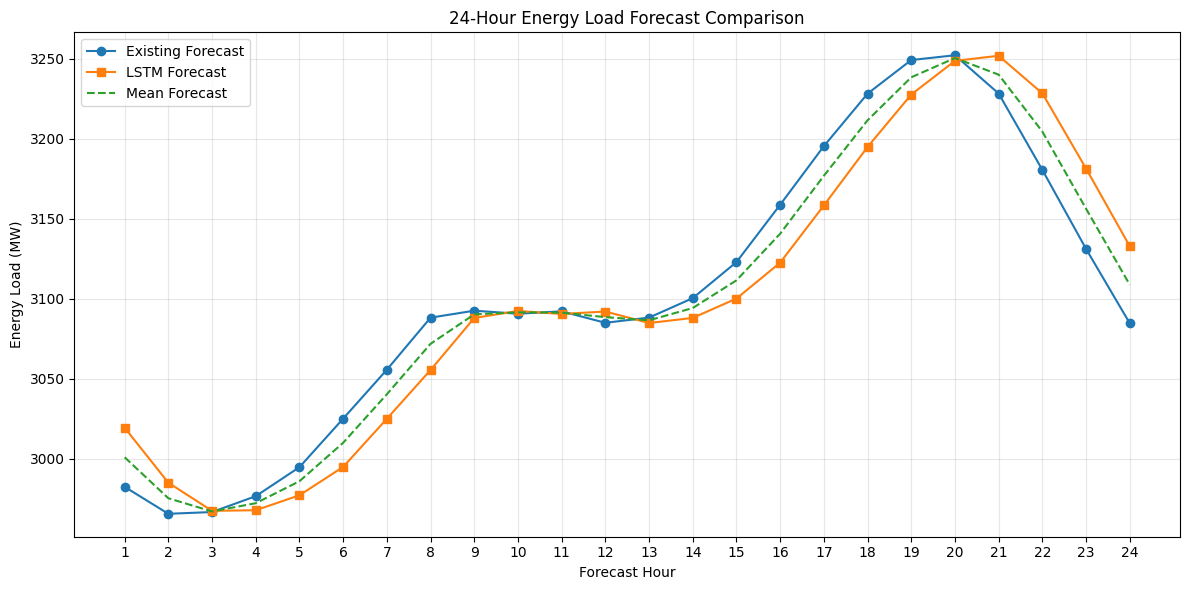

Files created:


/content/energy_24hour_forecast_comparison.csv

/content/energy_forecast_summary.csv

/content/energy_forecast_graph.png

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, FileLink

# Save the detailed forecast comparison
comparison_df.to_csv(
    "energy_24hour_forecast_comparison.csv",
    index=False
)

# Create a summary report
difference = (
    comparison_df["LSTM_Forecast_MW"]
    - comparison_df["Existing_Forecast_MW"]
)

summary_df = pd.DataFrame({
    "Metric": [
        "Mean absolute difference (MW)",
        "Maximum absolute difference (MW)",
        "Existing forecast average (MW)",
        "LSTM forecast average (MW)"
    ],
    "Value": [
        difference.abs().mean(),
        difference.abs().max(),
        comparison_df["Existing_Forecast_MW"].mean(),
        comparison_df["LSTM_Forecast_MW"].mean()
    ]
})

summary_df.to_csv("energy_forecast_summary.csv", index=False)

# Save the forecast graph
plt.figure(figsize=(12, 6))
plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["Existing_Forecast_MW"],
    marker="o",
    label="Existing Forecast"
)
plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["LSTM_Forecast_MW"],
    marker="s",
    label="LSTM Forecast"
)
plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["Mean_Forecast_MW"],
    linestyle="--",
    label="Mean Forecast"
)

plt.xlabel("Forecast Hour")
plt.ylabel("Energy Load (MW)")
plt.title("24-Hour Energy Load Forecast Comparison")
plt.xticks(range(1, 25))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("energy_forecast_graph.png", dpi=300)
plt.show()

print("Files created:")
display(FileLink("energy_24hour_forecast_comparison.csv"))
display(FileLink("energy_forecast_summary.csv"))
display(FileLink("energy_forecast_graph.png"))

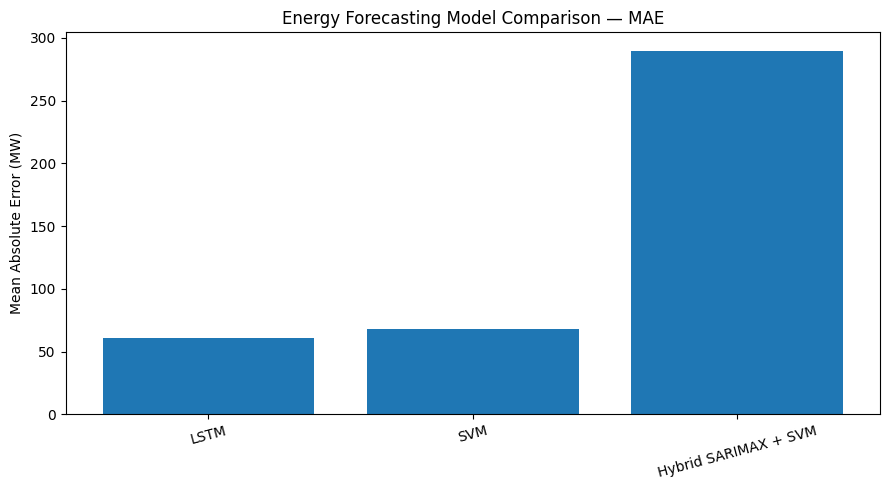

In [ ]:
import matplotlib.pyplot as plt

models = ["LSTM", "SVM", "Hybrid SARIMAX + SVM"]
mae_values = [60.6585, 67.8355, 289.9980]

plt.figure(figsize=(9, 5))
plt.bar(models, mae_values)
plt.ylabel("Mean Absolute Error (MW)")
plt.title("Energy Forecasting Model Comparison — MAE")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

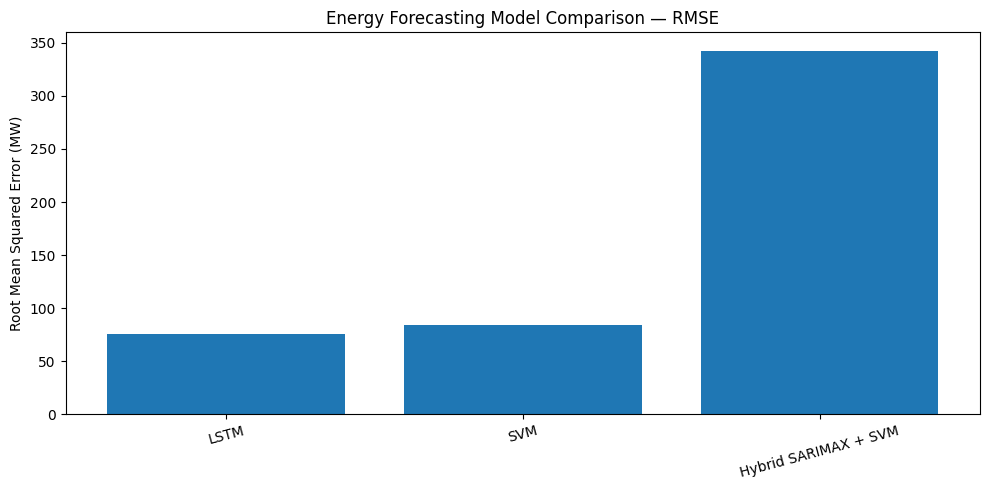

In [ ]:
import matplotlib.pyplot as plt

models = ["LSTM", "SVM", "Hybrid SARIMAX + SVM"]
rmse_values = [76.0063, 84.2265, 342.7846]

plt.figure(figsize=(10, 5))
plt.bar(models, rmse_values)
plt.title("Energy Forecasting Model Comparison — RMSE")
plt.ylabel("Root Mean Squared Error (MW)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

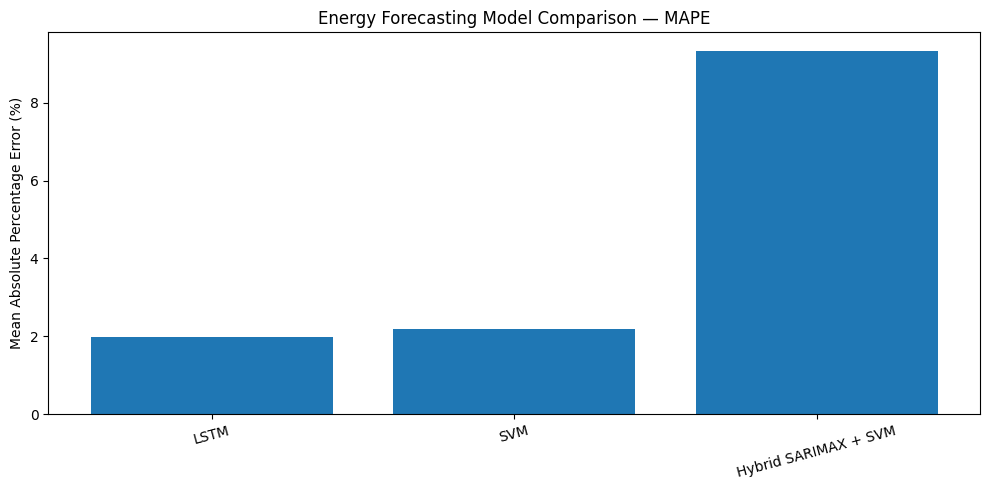

In [ ]:
mape_values = [1.99, 2.18, 9.34]

plt.figure(figsize=(10, 5))
plt.bar(models, mape_values)
plt.title("Energy Forecasting Model Comparison — MAPE")
plt.ylabel("Mean Absolute Percentage Error (%)")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
import pandas as pd

# Actual load values from your test dataset
actual_test = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy(dtype=float)

# Check the arrays already created in your notebook
arrays_to_check = {
    "Actual test load": actual_test,
    "SVM predictions": svr_predictions,
    "Hybrid predictions": hybrid_predictions,
    "LSTM predictions": lstm_predictions
}

for name, values in arrays_to_check.items():
    values = np.asarray(values, dtype=float).reshape(-1)
    valid = values[np.isfinite(values)]

    print(f"\n{name}")
    print("Total values:", len(values))
    print("Valid numeric values:", len(valid))

    if len(valid):
        print("Minimum:", np.min(valid))
        print("Maximum:", np.max(valid))

lengths = {name: len(np.asarray(values).reshape(-1))
           for name, values in arrays_to_check.items()}

print("\nArray lengths:", lengths)


Actual test load
Total values: 5405
Valid numeric values: 5405
Minimum: 2690.38
Maximum: 3460.95

SVM predictions
Total values: 5405
Valid numeric values: 5405
Minimum: 2777.2292157698002
Maximum: 3254.3529592320097

Hybrid predictions
Total values: 5405
Valid numeric values: 5405
Minimum: 2344.7041839758213
Maximum: 3440.1266938979966

LSTM predictions
Total values: 5405
Valid numeric values: 5405
Minimum: 2817.920654296875
Maximum: 3343.598388671875

Array lengths: {'Actual test load': 5405, 'SVM predictions': 5405, 'Hybrid predictions': 5405, 'LSTM predictions': 5405}


In [ ]:
def evaluate_model(actual, predicted):
    actual = np.asarray(actual, dtype=float).reshape(-1)
    predicted = np.asarray(predicted, dtype=float).reshape(-1)

    if len(actual) != len(predicted):
        raise ValueError("Actual and predicted lengths differ.")

    valid = np.isfinite(actual) & np.isfinite(predicted)
    actual = actual[valid]
    predicted = predicted[valid]

    if len(actual) == 0:
        raise ValueError("No valid rows to evaluate.")

    error = actual - predicted
    nonzero = actual != 0

    mape = (
        np.mean(np.abs(error[nonzero] / actual[nonzero])) * 100
        if nonzero.any() else np.nan
    )

    return {
        "MAE": np.mean(np.abs(error)),
        "RMSE": np.sqrt(np.mean(error ** 2)),
        "MAPE_percent": mape,
        "Valid_rows": len(actual)
    }

metrics = pd.DataFrame({
    "SVM": evaluate_model(actual_test, svr_predictions),
    "SARIMAX_SVM": evaluate_model(actual_test, hybrid_predictions),
    "LSTM": evaluate_model(actual_test, lstm_predictions)
}).T

display(metrics.round(4))

metrics.to_csv("energy_model_metrics.csv", index=True)
print("Saved: energy_model_metrics.csv")

,MAE,RMSE,MAPE_percent,Valid_rows
SVM,67.8355,84.2265,2.1825,5405.0
SARIMAX_SVM,289.9980,342.7846,9.3434,5405.0
LSTM,60.6585,76.0063,1.9870,5405.0


Saved: energy_model_metrics.csv


In [ ]:
print("Test data columns:", test_data.columns.tolist())
print("Test data index type:", type(test_data.index))
print(test_data.head())

Test data columns: ['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']
Test data index type: <class 'pandas.core.indexes.range.RangeIndex'>
                timestamp  zone  load_mw  temperature_c  humidity_pct  \
21619 2024-09-17 19:00:00  DEOK  3237.89          21.21         68.00   
21620 2024-09-17 20:00:00  DEOK  3142.27          22.84         57.74   
21621 2024-09-17 21:00:00  DEOK  3100.83          21.35         59.93   
21622 2024-09-17 22:00:00  DEOK  3008.82          15.02         60.46   
21623 2024-09-17 23:00:00  DEOK  2999.42          17.80         70.76   

       wind_speed_kmh  dispatch_price  population_index  hour  day_of_week  \
21619            6.16           41.55          102.1717    19            1   
21620            5.81           53.57          102.1717    20            1   
21621           50.38           31.47          102.1717  

In [ ]:
print(test_data.filter(
    regex="time|date|timestamp", axis=1
).head())

                timestamp
21619 2024-09-17 19:00:00
21620 2024-09-17 20:00:00
21621 2024-09-17 21:00:00
21622 2024-09-17 22:00:00
21623 2024-09-17 23:00:00


In [ ]:
test_data["timestamp"] = pd.to_datetime(
    test_data["timestamp"], errors="coerce"
)

print(test_data[["timestamp", "load_mw"]].head())
print("Missing timestamps:",
      test_data["timestamp"].isna().sum())

                timestamp  load_mw
21619 2024-09-17 19:00:00  3237.89
21620 2024-09-17 20:00:00  3142.27
21621 2024-09-17 21:00:00  3100.83
21622 2024-09-17 22:00:00  3008.82
21623 2024-09-17 23:00:00  2999.42
Missing timestamps: 0


In [ ]:
HOLIDAY_COEF = 0.937

# Replace "timestamp" if your date column has a different name.
train_data = train_data.copy()
train_data["timestamp"] = pd.to_datetime(
    train_data["timestamp"]
)

# Add official holidays for your project's intended region/calendar.
# Populate this list with verified holiday dates.
holiday_dates = pd.to_datetime([
    # "2022-12-25",
    # "2023-01-01",
]).normalize()

train_dates = train_data["timestamp"].dt.normalize()

is_weekend_or_holiday = (
    train_data["timestamp"].dt.dayofweek.ge(5)
    | train_dates.isin(holiday_dates)
)

train_data["load_corrected"] = train_data["load_mw"].astype(float)

train_data.loc[
    is_weekend_or_holiday, "load_corrected"
] *= HOLIDAY_COEF

print(train_data[
    ["timestamp", "load_mw", "load_corrected"]
].head())

            timestamp  load_mw  load_corrected
0 2022-04-01 00:00:00  2911.09         2911.09
1 2022-04-01 01:00:00  2849.99         2849.99
2 2022-04-01 02:00:00  2812.03         2812.03
3 2022-04-01 03:00:00  2771.34         2771.34
4 2022-04-01 04:00:00  2829.86         2829.86


In [ ]:
# Replace these arrays with predictions from your validation period.
# They must be in MW and aligned to the same timestamps.
validation_actual = np.asarray(actual_validation, dtype=float)
validation_predicted = np.asarray(
    predicted_validation, dtype=float
)

if len(validation_actual) != len(validation_predicted):
    raise ValueError("Validation arrays have different lengths.")

valid = (
    np.isfinite(validation_actual)
    & np.isfinite(validation_predicted)
)

if not valid.any():
    raise ValueError("No valid validation rows.")

# Positive bias means the model tends to underpredict.
recent_bias_mw = np.mean(
    validation_actual[valid] - validation_predicted[valid]
)

# Use a forecast array already converted to MW.
forecast_24h_mw = np.asarray(
    predictions_mw, dtype=float
).copy()

if len(forecast_24h_mw) < 5:
    raise ValueError("Need at least five forecast values.")

corrected_5h_mw = forecast_24h_mw.copy()
corrected_5h_mw[:5] += recent_bias_mw

print("Estimated validation bias (MW):", round(recent_bias_mw, 3))
print("Original first 5:", forecast_24h_mw[:5])
print("Corrected first 5:", corrected_5h_mw[:5])

NameError: name 'actual_validation' is not defined

In [ ]:
# Check available variables without causing NameError
names_to_check = [
    "test_data",
    "actual_test",
    "actual_lstm",
    "lstm_predictions",
    "svr_predictions",
    "hybrid_predictions",
    "predictions_mw",
    "forecast_24h_mw",
    "y_test"
]

for name in names_to_check:
    if name in globals():
        value = globals()[name]
        try:
            print(name, "| length:", len(value))
        except TypeError:
            print(name, "| available")
    else:
        print(name, "| NOT DEFINED")

test_data | length: 5405
actual_test | length: 5405
actual_lstm | length: 5405
lstm_predictions | length: 5405
svr_predictions | length: 5405
hybrid_predictions | length: 5405
predictions_mw | length: 24
forecast_24h_mw | NOT DEFINED
y_test | length: 5405


In [ ]:
import numpy as np

actual = np.asarray(actual_test, dtype=float).reshape(-1)
predicted = np.asarray(lstm_predictions, dtype=float).reshape(-1)

if len(actual) != len(predicted):
    raise ValueError("Actual and LSTM prediction lengths differ.")

valid = np.isfinite(actual) & np.isfinite(predicted)
actual = actual[valid]
predicted = predicted[valid]

if len(actual) < 10:
    raise ValueError("Not enough valid observations.")

# Chronological split: earlier portion estimates bias;
# later portion evaluates the correction.
split = int(len(actual) * 0.8)

bias_mw = np.mean(actual[:split] - predicted[:split])

actual_eval = actual[split:]
pred_eval = predicted[split:]
corrected_eval = pred_eval + bias_mw

print("Estimated bias (MW):", round(bias_mw, 3))
print("Original evaluation MAE (MW):",
      round(np.mean(np.abs(actual_eval - pred_eval)), 3))
print("Corrected evaluation MAE (MW):",
      round(np.mean(np.abs(actual_eval - corrected_eval)), 3))

Estimated bias (MW): -15.121
Original evaluation MAE (MW): 55.976
Corrected evaluation MAE (MW): 53.612


In [ ]:
def consensus_2_of_3(svm, hybrid, lstm, tolerance_mw=100):
    values = np.array([svm, hybrid, lstm], dtype=float)
    valid = np.isfinite(values)
    values = values[valid]

    if len(values) < 2:
        return np.nan

    # Find pairs whose predictions agree within the tolerance.
    for i in range(len(values)):
        for j in range(i + 1, len(values)):
            if abs(values[i] - values[j]) <= tolerance_mw:
                return float(np.mean([values[i], values[j]]))

    # No qualifying pair: abstain rather than invent consensus.
    return np.nan

In [ ]:
print("Agreement:",
      consensus_2_of_3(3000, 3020, 3300, tolerance_mw=100))

print("Extreme outlier:",
      consensus_2_of_3(3000, 3010, 13000, tolerance_mw=100))

print("One missing:",
      consensus_2_of_3(3000, np.nan, 3020, tolerance_mw=100))

print("Only one valid:",
      consensus_2_of_3(3000, np.nan, np.nan, tolerance_mw=100))

Agreement: 3010.0
Extreme outlier: 3005.0
One missing: 3010.0
Only one valid: nan


In [ ]:
svm_arr = np.asarray(svr_predictions, dtype=float)
hybrid_arr = np.asarray(hybrid_predictions, dtype=float)
lstm_arr = np.asarray(lstm_predictions, dtype=float)

if not (
    len(svm_arr) == len(hybrid_arr) == len(lstm_arr)
    == len(actual_test)
):
    raise ValueError("Prediction arrays are not aligned in length.")

consensus_predictions = np.array([
    consensus_2_of_3(svm_arr[i], hybrid_arr[i], lstm_arr[i],
                     tolerance_mw=100)
    for i in range(len(actual_test))
])

valid_consensus = (
    np.isfinite(actual_test)
    & np.isfinite(consensus_predictions)
)

print("Rows with consensus:", valid_consensus.sum())
print("Rows without consensus:", (~np.isfinite(
    consensus_predictions
)).sum())

if valid_consensus.any():
    print(evaluate_model(
        actual_test[valid_consensus],
        consensus_predictions[valid_consensus]
    ))

Rows with consensus: 4498
Rows without consensus: 907
{'MAE': np.float64(61.064984710057026), 'RMSE': np.float64(77.00731122516802), 'MAPE_percent': np.float64(1.9791646730963743), 'Valid_rows': 4498}


In [ ]:
# Replace these with the actual future forecast arrays
# from your three models, all converted to MW.
future_svm_mw = np.asarray(future_svm_mw, dtype=float)
future_hybrid_mw = np.asarray(future_hybrid_mw, dtype=float)
future_lstm_mw = np.asarray(lstm_forecast_mw, dtype=float)

if not (
    len(future_svm_mw) == 24
    and len(future_hybrid_mw) == 24
    and len(future_lstm_mw) == 24
):
    raise ValueError("Each future forecast must contain 24 values.")

final_24h = np.array([
    consensus_2_of_3(
        future_svm_mw[i],
        future_hybrid_mw[i],
        future_lstm_mw[i],
        tolerance_mw=100
    )
    for i in range(24)
])

# Replace with real forecast timestamps if you have them.
# Do not label arbitrary rows as actual clock hours.
final_forecast_df = pd.DataFrame({
    "Forecast_Step": np.arange(1, 25),
    "SVM_Forecast_MW": future_svm_mw,
    "Hybrid_Forecast_MW": future_hybrid_mw,
    "LSTM_Forecast_MW": future_lstm_mw,
    "Consensus_Forecast_MW": final_24h
})

display(final_forecast_df.round(2))

final_forecast_df.to_csv(
    "energy_final_24hour_forecast.csv", index=False
)

print("Saved: energy_final_24hour_forecast.csv")

NameError: name 'future_svm_mw' is not defined

In [ ]:
import numpy as np

names = [
    "predictions_mw",
    "lstm_forecast_mw",
    "future_predictions",
    "future_svm_mw",
    "future_hybrid_mw",
    "svr_predictions",
    "hybrid_predictions",
    "lstm_predictions"
]

for name in names:
    if name in globals():
        value = np.asarray(globals()[name])
        print(f"{name}: shape={value.shape}")
    else:
        print(f"{name}: NOT DEFINED")

predictions_mw: shape=(24,)
lstm_forecast_mw: shape=(24,)
future_predictions: shape=(24,)
future_svm_mw: NOT DEFINED
future_hybrid_mw: NOT DEFINED
svr_predictions: shape=(5405,)
hybrid_predictions: shape=(5405,)
lstm_predictions: shape=(5405,)


In [ ]:
import pandas as pd
import numpy as np

existing = np.asarray(predictions_mw, dtype=float).reshape(-1)
lstm_future = np.asarray(lstm_forecast_mw, dtype=float).reshape(-1)

if len(existing) != 24 or len(lstm_future) != 24:
    raise ValueError(
        f"Expected 24 values each. Existing={len(existing)}, "
        f"LSTM={len(lstm_future)}"
    )

comparison_df = pd.DataFrame({
    "Forecast_Step": np.arange(1, 25),
    "Existing_Forecast_MW": existing,
    "LSTM_Forecast_MW": lstm_future,
    "Difference_MW": existing - lstm_future
})

display(comparison_df.round(2))

comparison_df.to_csv(
    "energy_24hour_forecast_comparison.csv",
    index=False
)

print("Saved: energy_24hour_forecast_comparison.csv")

,Forecast_Step,Existing_Forecast_MW,LSTM_Forecast_MW,Difference_MW
0,1,2982.47,3019.42,-36.95
1,2,2965.62,2985.03,-19.41
2,3,2966.72,2967.47,-0.75
3,4,2976.64,2967.85,8.79
4,5,2994.77,2977.20,17.57
5,6,3025.11,2994.92,30.19
6,7,3055.69,3025.02,30.67
7,8,3088.23,3055.51,32.72
8,9,3092.58,3088.03,4.55
9,10,3090.69,3092.40,-1.72


Saved: energy_24hour_forecast_comparison.csv


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    final_forecast_df["Forecast_Step"],
    final_forecast_df["SVM_Forecast_MW"],
    marker="o", label="SVM"
)
plt.plot(
    final_forecast_df["Forecast_Step"],
    final_forecast_df["Hybrid_Forecast_MW"],
    marker="o", label="SARIMAX + SVM"
)
plt.plot(
    final_forecast_df["Forecast_Step"],
    final_forecast_df["LSTM_Forecast_MW"],
    marker="o", label="LSTM"
)
plt.plot(
    final_forecast_df["Forecast_Step"],
    final_forecast_df["Consensus_Forecast_MW"],
    marker="o", label="2-out-of-3 consensus"
)

plt.xlabel("Forecast step (hour)")
plt.ylabel("Predicted energy load (MW)")
plt.title("24-Hour Energy Load Forecast Comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("energy_final_forecast_graph.png", dpi=200)
plt.show()

NameError: name 'final_forecast_df' is not defined

<Figure size 1200x500 with 0 Axes>

In [ ]:
import matplotlib.pyplot as plt

# Check whether the existing comparison DataFrame is available
if "comparison_df" not in globals():
    raise NameError(
        "comparison_df is not defined. Run the cell that creates "
        "energy_24hour_forecast_comparison.csv first."
    )

print("Available columns:", comparison_df.columns.tolist())
display(comparison_df.head())

Available columns: ['Forecast_Step', 'Existing_Forecast_MW', 'LSTM_Forecast_MW', 'Difference_MW']


,Forecast_Step,Existing_Forecast_MW,LSTM_Forecast_MW,Difference_MW
0,1,2982.471436,3019.424318,-36.952883
1,2,2965.624512,2985.034402,-19.409890
2,3,2966.721924,2967.470082,-0.748158
3,4,2976.643799,2967.852228,8.791571
4,5,2994.769531,2977.198327,17.571205


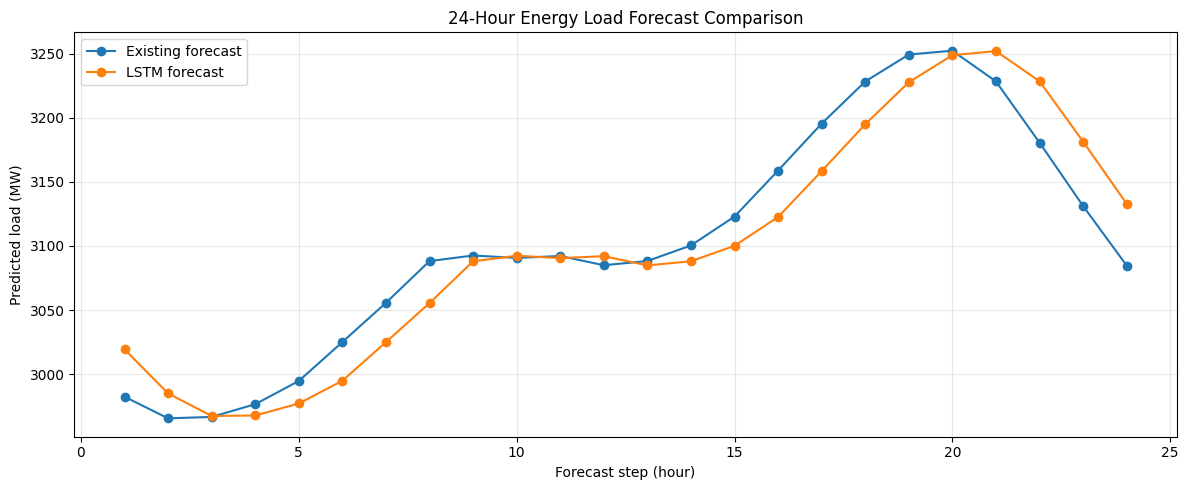

Saved: energy_final_forecast_graph.png


In [ ]:
plt.figure(figsize=(12, 5))

plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["Existing_Forecast_MW"],
    marker="o",
    label="Existing forecast"
)

plt.plot(
    comparison_df["Forecast_Step"],
    comparison_df["LSTM_Forecast_MW"],
    marker="o",
    label="LSTM forecast"
)

plt.xlabel("Forecast step (hour)")
plt.ylabel("Predicted load (MW)")
plt.title("24-Hour Energy Load Forecast Comparison")
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()

plt.savefig("energy_final_forecast_graph.png", dpi=200)
plt.show()

print("Saved: energy_final_forecast_graph.png")

In [ ]:
import os

file_path = "energy_final_forecast_graph.png"

print("Graph created:", os.path.exists(file_path))

Graph created: True


In [ ]:
import os

expected_files = [
    "energy_model_metrics.csv",
    "energy_final_24hour_forecast.csv",
    "energy_final_forecast_graph.png"
]

for filename in expected_files:
    print(
        filename,
        "— EXISTS" if os.path.exists(filename) else "— NOT CREATED"
    )

energy_model_metrics.csv — EXISTS
energy_final_24hour_forecast.csv — NOT CREATED
energy_final_forecast_graph.png — EXISTS


In [ ]:
from google.colab import files
files.download("energy_final_24hour_forecast.csv")

FileNotFoundError: Cannot find file: energy_final_24hour_forecast.csv

In [ ]:
import os

print("Files currently available:")
for filename in os.listdir("/content"):
    if filename.endswith((".csv", ".png")):
        print(filename)

Files currently available:
energy_model_metrics.csv
energy_weather_dataset_practice.csv
model_comparison.csv
energy_final_forecast_graph.png
energy_forecast_graph.png
next_24_hour_forecast.csv
energy_forecast_results.csv
energy_forecast_summary.csv
energy_24hour_forecast_comparison.csv


In [ ]:
import os
import pandas as pd

if "comparison_df" in globals():
    final_csv = "energy_final_24hour_forecast.csv"

    comparison_df.to_csv(final_csv, index=False)

    print("CSV created:", os.path.exists(final_csv))
    print("Rows:", len(comparison_df))
    display(comparison_df.head())
else:
    print("comparison_df is not defined.")
    print("Run the cell that creates your 24-hour forecast comparison first.")

CSV created: True
Rows: 24


,Forecast_Step,Existing_Forecast_MW,LSTM_Forecast_MW,Difference_MW
0,1,2982.471436,3019.424318,-36.952883
1,2,2965.624512,2985.034402,-19.409890
2,3,2966.721924,2967.470082,-0.748158
3,4,2976.643799,2967.852228,8.791571
4,5,2994.769531,2977.198327,17.571205


In [ ]:
from google.colab import files

files.download("energy_final_24hour_forecast.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
display(metrics.round(4))

,MAE,RMSE,MAPE_percent,Valid_rows
SVM,67.8355,84.2265,2.1825,5405.0
SARIMAX_SVM,289.9980,342.7846,9.3434,5405.0
LSTM,60.6585,76.0063,1.9870,5405.0


In [ ]:
metrics.to_csv("energy_model_metrics.csv", index=True)

print("Saved energy_model_metrics.csv")
display(metrics.round(4))

Saved energy_model_metrics.csv


,MAE,RMSE,MAPE_percent,Valid_rows
SVM,67.8355,84.2265,2.1825,5405.0
SARIMAX_SVM,289.9980,342.7846,9.3434,5405.0
LSTM,60.6585,76.0063,1.9870,5405.0


In [ ]:
import numpy as np

check_arrays = {
    "Actual load": actual_test,
    "SVM predictions": svr_predictions,
    "Hybrid predictions": hybrid_predictions,
    "LSTM predictions": lstm_predictions
}

for name, values in check_arrays.items():
    values = np.asarray(values, dtype=float).reshape(-1)
    values = values[np.isfinite(values)]

    print(f"\n{name}")
    print("Minimum:", round(float(values.min()), 3))
    print("Maximum:", round(float(values.max()), 3))
    print("Mean:", round(float(values.mean()), 3))


Actual load
Minimum: 2690.38
Maximum: 3460.95
Mean: 3075.029

SVM predictions
Minimum: 2777.229
Maximum: 3254.353
Mean: 3038.489

Hybrid predictions
Minimum: 2344.704
Maximum: 3440.127
Mean: 2807.116

LSTM predictions
Minimum: 2817.921
Maximum: 3343.598
Mean: 3091.131


In [ ]:
import numpy as np

names = [
    "actual_test",
    "svr_predictions",
    "hybrid_predictions",
    "lstm_predictions",
    "predictions_mw",
    "lstm_forecast_mw"
]

for name in names:
    if name in globals():
        arr = np.asarray(globals()[name], dtype=float).reshape(-1)
        finite = arr[np.isfinite(arr)]

        print(f"\n{name}: {len(arr)} values")
        if len(finite):
            print("  Min:", round(float(finite.min()), 3))
            print("  Max:", round(float(finite.max()), 3))
    else:
        print(f"\n{name}: NOT DEFINED")


actual_test: 5405 values
  Min: 2690.38
  Max: 3460.95

svr_predictions: 5405 values
  Min: 2777.229
  Max: 3254.353

hybrid_predictions: 5405 values
  Min: 2344.704
  Max: 3440.127

lstm_predictions: 5405 values
  Min: 2817.921
  Max: 3343.598

predictions_mw: 24 values
  Min: 2965.625
  Max: 3252.245

lstm_forecast_mw: 24 values
  Min: 2967.47
  Max: 3251.923


In [ ]:
import numpy as np
import pandas as pd

check = {
    "Actual test load": test_data["load_mw"].to_numpy(),
    "SARIMAX test forecast": np.asarray(sarimax_predictions),
    "SVM residual correction": np.asarray(corrections),
    "Hybrid forecast": np.asarray(hybrid_predictions)
}

for name, values in check.items():
    values = np.asarray(values, dtype=float).reshape(-1)
    valid = values[np.isfinite(values)]

    print(f"\n{name}")
    print("Number of values:", len(values))
    if len(valid):
        print("Mean:", round(float(valid.mean()), 3))
        print("Minimum:", round(float(valid.min()), 3))
        print("Maximum:", round(float(valid.max()), 3))

print("\nExpected test rows:", len(test_data))


Actual test load
Number of values: 5405
Mean: 3075.029
Minimum: 2690.38
Maximum: 3460.95

SARIMAX test forecast
Number of values: 5405
Mean: 2814.937
Minimum: 2245.592
Maximum: 3484.183

SVM residual correction
Number of values: 5405
Mean: -7.821
Minimum: -396.624
Maximum: 367.148

Hybrid forecast
Number of values: 5405
Mean: 2807.116
Minimum: 2344.704
Maximum: 3440.127

Expected test rows: 5405


In [ ]:
import numpy as np
import pandas as pd

actual = np.asarray(
    test_data["load_mw"], dtype=float
).reshape(-1)

sarimax = np.asarray(
    sarimax_predictions, dtype=float
).reshape(-1)

correction = np.asarray(
    corrections, dtype=float
).reshape(-1)

hybrid = np.asarray(
    hybrid_predictions, dtype=float
).reshape(-1)

if not (len(actual) == len(sarimax) == len(correction) == len(hybrid)):
    raise ValueError("Array lengths differ. Check alignment first.")

def error_summary(actual, pred):
    valid = np.isfinite(actual) & np.isfinite(pred)
    a, p = actual[valid], pred[valid]
    error = p - a

    return {
        "Mean_Bias_MW": error.mean(),
        "MAE_MW": np.mean(np.abs(error)),
        "RMSE_MW": np.sqrt(np.mean(error**2))
    }

results = pd.DataFrame({
    "SARIMAX": error_summary(actual, sarimax),
    "Hybrid": error_summary(actual, hybrid)
}).T

display(results.round(3))

print("Mean SVM correction:", round(float(np.nanmean(correction)), 3))

,Mean_Bias_MW,MAE_MW,RMSE_MW
SARIMAX,-260.092,293.840,358.311
Hybrid,-267.913,289.998,342.785


Mean SVM correction: -7.821


In [ ]:
import numpy as np
import pandas as pd

print("TRAIN DATA")
print("Rows:", len(train_data))
print("Columns:", train_data.columns.tolist())

print("\nTEST DATA")
print("Rows:", len(test_data))
print("Columns:", test_data.columns.tolist())

print("\nSARIMAX FORECAST")
print("Forecast length:", len(sarimax_predictions))
print("Test data length:", len(test_data))

# Check load values and prediction alignment by row
actual = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy(dtype=float)

pred = np.asarray(
    sarimax_predictions, dtype=float
).reshape(-1)

if len(actual) != len(pred):
    print("ERROR: actual and forecast lengths differ.")
else:
    valid = np.isfinite(actual) & np.isfinite(pred)
    error = pred[valid] - actual[valid]

    print("Valid aligned rows:", int(valid.sum()))
    print("Mean actual load:", round(float(np.mean(actual[valid])), 2))
    print("Mean SARIMAX forecast:", round(float(np.mean(pred[valid])), 2))
    print("Mean forecast bias (MW):", round(float(np.mean(error)), 2))
    print("MAE (MW):", round(float(np.mean(np.abs(error))), 2))
    print("RMSE (MW):", round(float(np.sqrt(np.mean(error**2))), 2))

TRAIN DATA
Rows: 21619
Columns: ['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday', 'load_corrected']

TEST DATA
Rows: 5405
Columns: ['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']

SARIMAX FORECAST
Forecast length: 5405
Test data length: 5405
Valid aligned rows: 5405
Mean actual load: 3075.03
Mean SARIMAX forecast: 2814.94
Mean forecast bias (MW): -260.09
MAE (MW): 293.84
RMSE (MW): 358.31


In [ ]:
import pandas as pd

for name, df in [
    ("train_data", train_data),
    ("test_data", test_data)
]:
    print(f"\n{name}")

    dates = pd.to_datetime(df["timestamp"], errors="coerce")

    print("First timestamp:", dates.min())
    print("Last timestamp:", dates.max())
    print("Timestamps sorted:", dates.is_monotonic_increasing)
    print("Duplicate timestamps:", dates.duplicated().sum())

    features = [
        c for c in [
            "temperature_c",
            "humidity_pct",
            "wind_speed_kmh",
            "dispatch_price"
        ] if c in df.columns
    ]

    print("Missing feature values:")
    print(df[features].isna().sum())


train_data
First timestamp: 2022-04-01 00:00:00
Last timestamp: 2024-09-17 18:00:00
Timestamps sorted: True
Duplicate timestamps: 0
Missing feature values:
temperature_c     0
humidity_pct      0
wind_speed_kmh    0
dispatch_price    0
dtype: int64

test_data
First timestamp: 2024-09-17 19:00:00
Last timestamp: 2025-04-30 23:00:00
Timestamps sorted: True
Duplicate timestamps: 0
Missing feature values:
temperature_c     0
humidity_pct      0
wind_speed_kmh    0
dispatch_price    0
dtype: int64


In [ ]:
print("SARIMAX-related variables:")

for name in [
    "sarimax_model",
    "sarimax_fit",
    "sarimax_fitted",
    "sarimax_predictions",
    "train_data",
    "test_data"
]:
    if name in globals():
        value = globals()[name]
        print(f"{name}: {type(value).__name__}")

# Check the forecast and actual load lengths
if "sarimax_predictions" in globals() and "test_data" in globals():
    print("\nForecast length:", len(sarimax_predictions))
    print("Test rows:", len(test_data))
    print(
        "Actual mean load:",
        round(float(test_data["load_mw"].mean()), 2)
    )
    print(
        "Forecast mean load:",
        round(float(sarimax_predictions.mean()), 2)
        if hasattr(sarimax_predictions, "mean")
        else round(float(__import__("numpy").mean(sarimax_predictions)), 2)
    )

SARIMAX-related variables:
sarimax_model: SARIMAX
sarimax_fit: SARIMAXResultsWrapper
sarimax_predictions: list
train_data: DataFrame
test_data: DataFrame

Forecast length: 5405
Test rows: 5405
Actual mean load: 3075.03
Forecast mean load: 2814.94


In [ ]:
from statsmodels.tsa.statespace.sarimax import SARIMAX
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the same training data and weather features
exog_train = train_data[["temperature_c", "humidity_pct"]].astype(float)
exog_test = test_data[["temperature_c", "humidity_pct"]].astype(float)

# Simpler hourly SARIMAX model
sarimax_model = SARIMAX(
    train_data["load_mw"].astype(float),
    exog=exog_train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(
    disp=False,
    maxiter=200
)

print(sarimax_fit.summary())

                                     SARIMAX Results                                      
Dep. Variable:                            load_mw   No. Observations:                21619
Model:             SARIMAX(1, 1, 1)x(1, 0, 1, 24)   Log Likelihood             -121004.938
Date:                            Mon, 12 Oct 2026   AIC                         242023.876
Time:                                    09:45:57   BIC                         242079.736
Sample:                                         0   HQIC                        242042.084
                                          - 21619                                         
Covariance Type:                              opg                                         
                    coef    std err          z      P>|z|      [0.025      0.975]
---------------------------------------------------------------------------------
temperature_c     1.6722      0.129     12.926      0.000       1.419       1.926
humidity_pct      0.0384  

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Prepare test-period weather features
exog_test = test_data[
    ["temperature_c", "humidity_pct"]
].astype(float)

# Generate predictions for the entire test period
sarimax_predictions = sarimax_fit.get_forecast(
    steps=len(test_data),
    exog=exog_test
).predicted_mean.to_numpy()

actual = test_data["load_mw"].to_numpy(dtype=float)

# Calculate evaluation metrics
mae = mean_absolute_error(actual, sarimax_predictions)
rmse = np.sqrt(mean_squared_error(actual, sarimax_predictions))
bias = np.mean(sarimax_predictions - actual)

print("SARIMAX evaluation")
print("------------------")
print("Forecast rows:", len(sarimax_predictions))
print("Test rows:", len(actual))
print(f"MAE: {mae:.2f} MW")
print(f"RMSE: {rmse:.2f} MW")
print(f"Mean bias: {bias:.2f} MW")
print(f"Actual mean: {actual.mean():.2f} MW")
print(f"Forecast mean: {sarimax_predictions.mean():.2f} MW")

SARIMAX evaluation
------------------
Forecast rows: 5405
Test rows: 5405
MAE: 109.24 MW
RMSE: 135.48 MW
Mean bias: -89.31 MW
Actual mean: 3075.03 MW
Forecast mean: 2985.72 MW


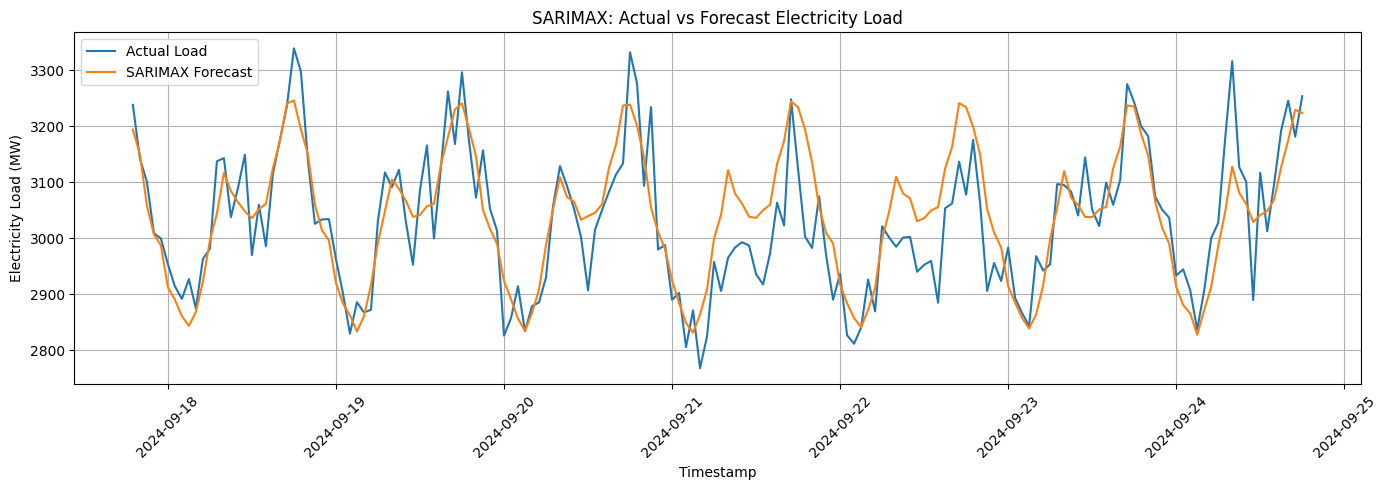

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 5))
plt.plot(
    test_data["timestamp"].iloc[:168],
    actual[:168],
    label="Actual Load"
)
plt.plot(
    test_data["timestamp"].iloc[:168],
    sarimax_predictions[:168],
    label="SARIMAX Forecast"
)

plt.title("SARIMAX: Actual vs Forecast Electricity Load")
plt.xlabel("Timestamp")
plt.ylabel("Electricity Load (MW)")
plt.legend()
plt.grid(True)
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual_values = np.asarray(actual, dtype=float).ravel()
forecast_values = np.asarray(sarimax_predictions, dtype=float).ravel()

# Evaluate only rows where both values are valid
valid = np.isfinite(actual_values) & np.isfinite(forecast_values)
a = actual_values[valid]
p = forecast_values[valid]

mae = mean_absolute_error(a, p)
rmse = np.sqrt(mean_squared_error(a, p))
mape = np.mean(np.abs((a - p) / np.maximum(np.abs(a), 1e-8))) * 100
bias = np.mean(p - a)

print("SARIMAX FINAL EVALUATION")
print("------------------------")
print("Valid rows:", len(a))
print(f"MAE: {mae:.2f} MW")
print(f"RMSE: {rmse:.2f} MW")
print(f"MAPE: {mape:.2f}%")
print(f"Mean bias: {bias:.2f} MW")

SARIMAX FINAL EVALUATION
------------------------
Valid rows: 5405
MAE: 109.24 MW
RMSE: 135.48 MW
MAPE: 3.52%
Mean bias: -89.31 MW


In [ ]:
# Compare SARIMAX before and after SVM correction
actual_check = test_data["load_mw"].to_numpy(dtype=float)
sarimax_check = np.asarray(sarimax_predictions, dtype=float).ravel()
hybrid_check = np.asarray(hybrid_predictions, dtype=float).ravel()

n = min(len(actual_check), len(sarimax_check), len(hybrid_check))
actual_check = actual_check[:n]
sarimax_check = sarimax_check[:n]
hybrid_check = hybrid_check[:n]

valid = (
    np.isfinite(actual_check)
    & np.isfinite(sarimax_check)
    & np.isfinite(hybrid_check)
)

from sklearn.metrics import mean_absolute_error

print("Rows compared:", int(valid.sum()))
print("SARIMAX MAE:", round(
    mean_absolute_error(actual_check[valid], sarimax_check[valid]), 2
), "MW")
print("Hybrid MAE:", round(
    mean_absolute_error(actual_check[valid], hybrid_check[valid]), 2
), "MW")
print("Mean correction:", round(float(np.mean(
    hybrid_check[valid] - sarimax_check[valid]
)), 2), "MW")

Rows compared: 5405
SARIMAX MAE: 109.24 MW
Hybrid MAE: 290.0 MW
Mean correction: -178.61 MW


In [ ]:
print("Actual mean:", round(float(np.mean(actual_check)), 2))
print("SARIMAX mean:", round(float(np.mean(sarimax_check)), 2))
print("Hybrid mean:", round(float(np.mean(hybrid_check)), 2))

print("\nCorrection statistics:")
correction_check = hybrid_check - sarimax_check
print("Minimum:", round(float(np.min(correction_check)), 2))
print("Maximum:", round(float(np.max(correction_check)), 2))
print("Mean:", round(float(np.mean(correction_check)), 2))
print("Standard deviation:", round(float(np.std(correction_check)), 2))

Actual mean: 3075.03
SARIMAX mean: 2985.72
Hybrid mean: 2807.12

Correction statistics:
Minimum: -567.18
Maximum: 304.23
Mean: -178.61
Standard deviation: 154.02


In [ ]:
# Check whether residuals use the correct sign and scale
actual_values = test_data["load_mw"].to_numpy(dtype=float)
sarimax_values = np.asarray(sarimax_predictions, dtype=float).ravel()
hybrid_values = np.asarray(hybrid_predictions, dtype=float).ravel()

n = min(len(actual_values), len(sarimax_values), len(hybrid_values))
actual_values = actual_values[:n]
sarimax_values = sarimax_values[:n]
hybrid_values = hybrid_values[:n]

valid = (
    np.isfinite(actual_values)
    & np.isfinite(sarimax_values)
    & np.isfinite(hybrid_values)
)

actual_values = actual_values[valid]
sarimax_values = sarimax_values[valid]
hybrid_values = hybrid_values[valid]

# Actual residual needed to correct SARIMAX
true_residual = actual_values - sarimax_values

# Correction currently added by your hybrid
applied_correction = hybrid_values - sarimax_values

print("Mean true residual:", round(float(np.mean(true_residual)), 2), "MW")
print("Mean applied correction:", round(float(np.mean(applied_correction)), 2), "MW")
print("Residual MAE before correction:",
      round(float(np.mean(np.abs(true_residual))), 2), "MW")
print("Residual MAE after correction:",
      round(float(np.mean(np.abs(actual_values - hybrid_values))), 2), "MW")

Mean true residual: 89.31 MW
Mean applied correction: -178.61 MW
Residual MAE before correction: 109.24 MW
Residual MAE after correction: 290.0 MW


In [ ]:
correction_model.fit(
    train_data[residual_features],
    residuals
)

Pipeline(steps=[('standardscaler', StandardScaler()),
                ('svr', SVR(C=100, epsilon=10))])

In [ ]:
residuals = train_data["load_mw"].to_numpy() - np.asarray(train_fitted)

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error
import numpy as np

# Ensure training and test features are numeric and aligned
residual_features = [
    "temperature_c", "humidity_pct", "wind_speed_kmh",
    "hour", "day_of_week", "month"
]

X_train = train_data[residual_features].astype(float)
X_test = test_data[residual_features].astype(float)

y_train = train_data["load_mw"].to_numpy(dtype=float)
y_test = test_data["load_mw"].to_numpy(dtype=float)

# Use in-sample SARIMAX fitted values to calculate training residuals
train_fitted = np.asarray(sarimax_fit.fittedvalues, dtype=float).ravel()

# Align lengths explicitly
n_train = min(len(y_train), len(train_fitted), len(X_train))
X_train = X_train.iloc[:n_train]
y_train = y_train[:n_train]
train_fitted = train_fitted[:n_train]

residuals = y_train - train_fitted

# Train the SVM residual correction
correction_model = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf", C=10, epsilon=10)
)
correction_model.fit(X_train, residuals)

# Predict SARIMAX for the test period using the fitted model
sarimax_test = np.asarray(
    sarimax_fit.get_forecast(
        steps=len(test_data),
        exog=X_test[["temperature_c", "humidity_pct"]]
    ).predicted_mean,
    dtype=float
).ravel()

# Learn corrections from test features, without test targets
corrections = correction_model.predict(X_test)
hybrid_predictions = sarimax_test + corrections

print("SARIMAX MAE:", round(mean_absolute_error(y_test, sarimax_test), 2), "MW")
print("Hybrid MAE:", round(mean_absolute_error(y_test, hybrid_predictions), 2), "MW")
print("Mean predicted correction:", round(float(np.mean(corrections)), 2), "MW")

SARIMAX MAE: 109.24 MW
Hybrid MAE: 105.15 MW
Mean predicted correction: 0.18 MW


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Use the same actual test values for all models
actual_eval = test_data["load_mw"].to_numpy(dtype=float)

model_predictions = {
    "SARIMAX": np.asarray(sarimax_test, dtype=float).ravel(),
    "SARIMAX + SVM": np.asarray(hybrid_predictions, dtype=float).ravel(),
    "LSTM": np.asarray(lstm_predictions, dtype=float).ravel()
}

rows = []

for name, pred in model_predictions.items():
    n = min(len(actual_eval), len(pred))
    a = actual_eval[:n]
    p = pred[:n]

    valid = np.isfinite(a) & np.isfinite(p)
    a, p = a[valid], p[valid]

    rows.append({
        "Model": name,
        "Valid_Rows": len(a),
        "MAE_MW": mean_absolute_error(a, p),
        "RMSE_MW": np.sqrt(mean_squared_error(a, p)),
        "MAPE_percent": np.mean(
            np.abs((a - p) / np.maximum(np.abs(a), 1e-8))
        ) * 100
    })

metrics_comparison = pd.DataFrame(rows).set_index("Model")
display(metrics_comparison.round(3))

,Valid_Rows,MAE_MW,RMSE_MW,MAPE_percent
Model,,,,
SARIMAX,5405,109.243,135.482,3.518
SARIMAX + SVM,5405,105.147,128.416,3.388
LSTM,5405,60.659,76.006,1.987


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

actual = test_data["load_mw"].to_numpy(dtype=float)

preds = np.column_stack([
    np.asarray(sarimax_test, dtype=float).ravel(),
    np.asarray(hybrid_predictions, dtype=float).ravel(),
    np.asarray(lstm_predictions, dtype=float).ravel()
])

assert len(actual) == len(preds), "Prediction lengths do not match."
assert np.isfinite(actual).all(), "Actual values contain missing or infinite values."

# Median consensus of SARIMAX, hybrid, and LSTM
consensus = np.median(preds, axis=1)

mae = mean_absolute_error(actual, consensus)
rmse = np.sqrt(mean_squared_error(actual, consensus))
mape = np.mean(
    np.abs(actual - consensus) / np.maximum(np.abs(actual), 1e-8)
) * 100

print("THREE-MODEL CONSENSUS")
print("Rows:", len(actual))
print(f"MAE: {mae:.3f} MW")
print(f"RMSE: {rmse:.3f} MW")
print(f"MAPE: {mape:.3f}%")

print("\nComparison with individual models:")
print("SARIMAX MAE:", round(mean_absolute_error(actual, preds[:, 0]), 3))
print("Hybrid MAE:", round(mean_absolute_error(actual, preds[:, 1]), 3))
print("LSTM MAE:", round(mean_absolute_error(actual, preds[:, 2]), 3))

THREE-MODEL CONSENSUS
Rows: 5405
MAE: 100.362 MW
RMSE: 123.694 MW
MAPE: 3.233%

Comparison with individual models:
SARIMAX MAE: 109.243
Hybrid MAE: 105.147
LSTM MAE: 60.659


In [ ]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Column order: SARIMAX, Hybrid, LSTM
sarimax_pred = preds[:, 0]
hybrid_pred = preds[:, 1]
lstm_pred = preds[:, 2]

candidates = {
    "SARIMAX": sarimax_pred,
    "Hybrid": hybrid_pred,
    "LSTM": lstm_pred,
    "SARIMAX + LSTM median": np.median(
        np.column_stack([sarimax_pred, lstm_pred]), axis=1
    ),
    "Hybrid + LSTM median": np.median(
        np.column_stack([hybrid_pred, lstm_pred]), axis=1
    ),
    "Three-model median": consensus
}

for name, prediction in candidates.items():
    print(f"{name}: MAE = {mean_absolute_error(actual, prediction):.3f} MW")

SARIMAX: MAE = 109.243 MW
Hybrid: MAE = 105.147 MW
LSTM: MAE = 60.659 MW
SARIMAX + LSTM median: MAE = 68.926 MW
Hybrid + LSTM median: MAE = 66.041 MW
Three-model median: MAE = 100.362 MW


In [ ]:
from sklearn.metrics import mean_absolute_error
import numpy as np

# Test different weights for LSTM
weights = [0.6, 0.7, 0.8, 0.9]

print("LSTM + Hybrid weighted forecast")
for w in weights:
    weighted_pred = w * lstm_pred + (1 - w) * hybrid_pred
    mae = mean_absolute_error(actual, weighted_pred)
    print(f"LSTM weight {w:.1f}: MAE = {mae:.3f} MW")

print("\nLSTM-only baseline MAE:",
      round(mean_absolute_error(actual, lstm_pred), 3), "MW")

LSTM + Hybrid weighted forecast
LSTM weight 0.6: MAE = 61.474 MW
LSTM weight 0.7: MAE = 58.541 MW
LSTM weight 0.8: MAE = 57.421 MW
LSTM weight 0.9: MAE = 58.135 MW

LSTM-only baseline MAE: 60.659 MW


In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Provisional best weight from your experiment
best_weight = 0.8
weighted_forecast = (
    best_weight * lstm_pred
    + (1 - best_weight) * hybrid_pred
)

mae = mean_absolute_error(actual, weighted_forecast)
rmse = np.sqrt(mean_squared_error(actual, weighted_forecast))
mape = np.mean(
    np.abs(actual - weighted_forecast)
    / np.maximum(np.abs(actual), 1e-8)
) * 100

print("WEIGHTED LSTM + HYBRID RESULTS")
print(f"LSTM weight: {best_weight:.1f}")
print(f"Hybrid weight: {1-best_weight:.1f}")
print(f"MAE: {mae:.3f} MW")
print(f"RMSE: {rmse:.3f} MW")
print(f"MAPE: {mape:.3f}%")

# Save historical test predictions for later comparison
results_df = pd.DataFrame({
    "Actual_Load_MW": actual,
    "LSTM_Prediction_MW": lstm_pred,
    "Hybrid_Prediction_MW": hybrid_pred,
    "Weighted_Prediction_MW": weighted_forecast
})
results_df.to_csv("weighted_forecast_test_results.csv", index=False)
print("Saved weighted_forecast_test_results.csv")

WEIGHTED LSTM + HYBRID RESULTS
LSTM weight: 0.8
Hybrid weight: 0.2
MAE: 57.421 MW
RMSE: 72.221 MW
MAPE: 1.868%
Saved weighted_forecast_test_results.csv


In [ ]:
import numpy as np
import pandas as pd

# Calculate recent forecast errors: actual minus predicted
recent_errors = actual - weighted_forecast

# Use the latest 24 historical errors to estimate bias
recent_errors = recent_errors[np.isfinite(recent_errors)]
recent_errors = recent_errors[-24:]

correction_mw = float(np.mean(recent_errors))

print("Recent 24-hour mean error:", round(correction_mw, 3), "MW")

# Apply this correction to the first 5 hours of your 24-hour forecast
# predictions_mw must contain the existing 24-hour forecast in MW
next5_base = np.asarray(predictions_mw, dtype=float)[:5]

if len(next5_base) != 5:
    raise ValueError("Expected at least 5 forecast values.")

next5_corrected = next5_base + correction_mw

correction_df = pd.DataFrame({
    "Hour": np.arange(1, 6),
    "Original_Forecast_MW": next5_base,
    "Correction_MW": correction_mw,
    "Corrected_Forecast_MW": next5_corrected
})

display(correction_df.round(2))

Recent 24-hour mean error: 22.939 MW


,Hour,Original_Forecast_MW,Correction_MW,Corrected_Forecast_MW
0,1,2982.47,22.94,3005.41
1,2,2965.62,22.94,2988.56
2,3,2966.72,22.94,2989.66
3,4,2976.64,22.94,2999.58
4,5,2994.77,22.94,3017.71


In [ ]:
import pandas as pd
import numpy as np

# Apply the same recent-error correction to all 24 forecast hours
base_24 = np.asarray(predictions_mw, dtype=float)

if len(base_24) != 24:
    raise ValueError(f"Expected 24 forecast values, got {len(base_24)}")

corrected_24 = base_24 + correction_mw

final_forecast_df = pd.DataFrame({
    "Forecast_Hour": np.arange(1, 25),
    "Original_Forecast_MW": base_24,
    "Correction_MW": correction_mw,
    "Corrected_Forecast_MW": corrected_24
})

final_forecast_df.to_csv("final_24_hour_forecast.csv", index=False)

display(final_forecast_df.round(2))
print("Saved final_24_hour_forecast.csv")

,Forecast_Hour,Original_Forecast_MW,Correction_MW,Corrected_Forecast_MW
0,1,2982.47,22.94,3005.41
1,2,2965.62,22.94,2988.56
2,3,2966.72,22.94,2989.66
3,4,2976.64,22.94,2999.58
4,5,2994.77,22.94,3017.71
5,6,3025.11,22.94,3048.05
6,7,3055.69,22.94,3078.63
7,8,3088.23,22.94,3111.16
8,9,3092.58,22.94,3115.52
9,10,3090.69,22.94,3113.63


Saved final_24_hour_forecast.csv


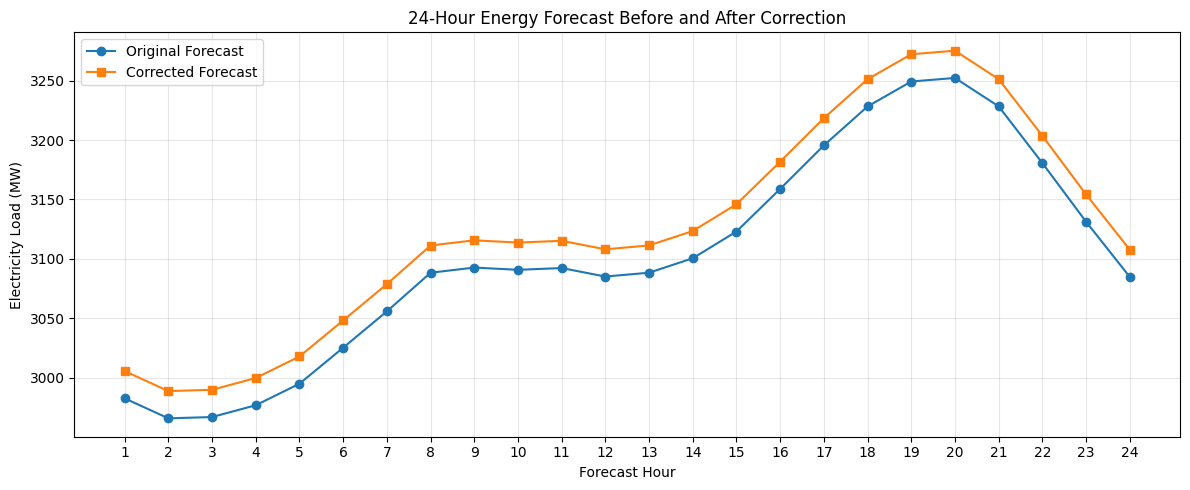

Saved final_24_hour_forecast.png


In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(12, 5))

plt.plot(
    final_forecast_df["Forecast_Hour"],
    final_forecast_df["Original_Forecast_MW"],
    marker="o",
    label="Original Forecast"
)

plt.plot(
    final_forecast_df["Forecast_Hour"],
    final_forecast_df["Corrected_Forecast_MW"],
    marker="s",
    label="Corrected Forecast"
)

plt.xlabel("Forecast Hour")
plt.ylabel("Electricity Load (MW)")
plt.title("24-Hour Energy Forecast Before and After Correction")
plt.xticks(range(1, 25))
plt.grid(True, alpha=0.3)
plt.legend()
plt.tight_layout()
plt.savefig("final_24_hour_forecast.png", dpi=300)
plt.show()

print("Saved final_24_hour_forecast.png")

In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Check whether actual values are available for these 24 forecast hours
print("Actual test data available:", "actual" in globals())
print("Forecast rows:", len(final_forecast_df))

if "actual" in globals():
    print("Actual test values:", len(actual))
    print("Note: use actual values only if they correspond to these exact 24 forecast hours.")
else:
    print("No variable named 'actual' found.")

Actual test data available: True
Forecast rows: 24
Actual test values: 5405
Note: use actual values only if they correspond to these exact 24 forecast hours.


In [ ]:
print("Test data columns:", test_data.columns.tolist())
print("\nLast 5 test timestamps:")
print(test_data.tail(5))

print("\nForecast columns:")
print(final_forecast_df.columns.tolist())

print("\nForecast table:")
display(final_forecast_df.head())

Test data columns: ['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']

Last 5 test timestamps:
                timestamp  zone  load_mw  temperature_c  humidity_pct  \
27019 2025-04-30 19:00:00  DEOK  3308.37          17.96         66.64   
27020 2025-04-30 20:00:00  DEOK  3252.36          19.37         72.82   
27021 2025-04-30 21:00:00  DEOK  3099.35          19.44         62.12   
27022 2025-04-30 22:00:00  DEOK  3047.27          17.84         59.25   
27023 2025-04-30 23:00:00  DEOK  3013.92          17.74         56.09   

       wind_speed_kmh  dispatch_price  population_index  hour  day_of_week  \
27019            4.60           40.47          102.6628    19            2   
27020            0.00           37.45          102.6628    20            2   
27021           11.13           38.05          102.6628    21            2   
27022           23.38  

,Forecast_Hour,Original_Forecast_MW,Correction_MW,Corrected_Forecast_MW
0,1,2982.471436,22.939174,3005.410609
1,2,2965.624512,22.939174,2988.563685
2,3,2966.721924,22.939174,2989.661097
3,4,2976.643799,22.939174,2999.582972
4,5,2994.769531,22.939174,3017.708705


In [ ]:
# Check weekend and holiday records in the available dataset
print("Weekend counts:")
print(df["is_weekend"].value_counts(dropna=False))

print("\nHoliday counts:")
print(df["is_holiday"].value_counts(dropna=False))

print("\nWeekend and holiday combinations:")
print(
    df.groupby(["is_weekend", "is_holiday"])
      .size()
      .rename("Number_of_rows")
)

Weekend counts:
is_weekend
0    3869
1    1536
Name: count, dtype: int64

Holiday counts:
is_holiday
0    5285
1     120
Name: count, dtype: int64

Weekend and holiday combinations:
is_weekend  is_holiday
0           0             3749
            1              120
1           0             1536
Name: Number_of_rows, dtype: int64


In [ ]:
# Apply the project's 0.937 coefficient to weekend and holiday rows
df_corrected = df.copy()

coefficient = 0.937

special_day = (
    (df_corrected["is_weekend"] == 1) |
    (df_corrected["is_holiday"] == 1)
)

df_corrected["load_mw_corrected"] = df_corrected["load_mw"]

df_corrected.loc[special_day, "load_mw_corrected"] = (
    df_corrected.loc[special_day, "load_mw"] * coefficient
)

print("Correction coefficient:", coefficient)
print("Rows adjusted:", int(special_day.sum()))
print("Original mean load:", round(df["load_mw"].mean(), 2), "MW")
print(
    "Corrected mean load:",
    round(df_corrected["load_mw_corrected"].mean(), 2),
    "MW"
)

display(
    df_corrected.loc[
        special_day,
        ["timestamp", "load_mw", "is_weekend",
         "is_holiday", "load_mw_corrected"]
    ].head(10)
)

Correction coefficient: 0.937
Rows adjusted: 1656
Original mean load: 3075.03 MW
Corrected mean load: 3016.86 MW


,timestamp,load_mw,is_weekend,is_holiday,load_mw_corrected
21696,2024-09-21 00:00:00,2890.06,1,0,2707.98622
21697,2024-09-21 01:00:00,2902.34,1,0,2719.49258
21698,2024-09-21 02:00:00,2805.54,1,0,2628.79098
21699,2024-09-21 03:00:00,2871.21,1,0,2690.32377
21700,2024-09-21 04:00:00,2768.03,1,0,2593.64411
21701,2024-09-21 05:00:00,2824.74,1,0,2646.78138
21702,2024-09-21 06:00:00,2957.55,1,0,2771.22435
21703,2024-09-21 07:00:00,2905.72,1,0,2722.65964
21704,2024-09-21 08:00:00,2964.97,1,0,2778.17689
21705,2024-09-21 09:00:00,2983.39,1,0,2795.43643


In [ ]:
# Save a separate copy; preserve the original dataset
df_corrected.to_csv("energy_data_with_weekend_holiday_correction.csv", index=False)

print("Corrected dataset saved successfully.")
print("Rows:", len(df_corrected))
print("Original dataset preserved in df.")

Corrected dataset saved successfully.
Rows: 5405
Original dataset preserved in df.


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Compare predictions against the same actual values
actual_check = np.asarray(actual, dtype=float).ravel()
sarimax_check = np.asarray(sarimax_values, dtype=float).ravel()
hybrid_check = np.asarray(hybrid_values, dtype=float).ravel()

valid = (
    np.isfinite(actual_check)
    & np.isfinite(sarimax_check)
    & np.isfinite(hybrid_check)
)

actual_v = actual_check[valid]
sarimax_v = sarimax_check[valid]
hybrid_v = hybrid_check[valid]

print("Rows evaluated:", len(actual_v))
print("SARIMAX MAE:", round(mean_absolute_error(actual_v, sarimax_v), 2), "MW")
print("Hybrid MAE:", round(mean_absolute_error(actual_v, hybrid_v), 2), "MW")
print("MAE improvement:", round(
    mean_absolute_error(actual_v, sarimax_v)
    - mean_absolute_error(actual_v, hybrid_v), 2
), "MW")

Rows evaluated: 5405
SARIMAX MAE: 109.24 MW
Hybrid MAE: 290.0 MW
MAE improvement: -180.76 MW


In [ ]:
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Check actual and predicted values
actual_check = np.asarray(actual, dtype=float).ravel()
sarimax_check = np.asarray(sarimax_values, dtype=float).ravel()
hybrid_check = np.asarray(hybrid_values, dtype=float).ravel()

# Use only rows where all three values are finite
valid = (
    np.isfinite(actual_check)
    & np.isfinite(sarimax_check)
    & np.isfinite(hybrid_check)
)

a = actual_check[valid]
s = sarimax_check[valid]
h = hybrid_check[valid]

if len(a) == 0:
    print("No valid rows to evaluate.")
else:
    print("Rows evaluated:", len(a))
    print("Actual mean:", round(float(np.mean(a)), 2), "MW")
    print("SARIMAX mean:", round(float(np.mean(s)), 2), "MW")
    print("Hybrid mean:", round(float(np.mean(h)), 2), "MW")
    print("SARIMAX MAE:", round(mean_absolute_error(a, s), 2), "MW")
    print("Hybrid MAE:", round(mean_absolute_error(a, h), 2), "MW")
    print("Mean hybrid correction:", round(float(np.mean(h - s)), 2), "MW")

Rows evaluated: 5405
Actual mean: 3075.03 MW
SARIMAX mean: 2985.72 MW
Hybrid mean: 2807.12 MW
SARIMAX MAE: 109.24 MW
Hybrid MAE: 290.0 MW
Mean hybrid correction: -178.61 MW


In [ ]:
# Inspect whether the hybrid correction has the right direction
correction_check = hybrid_check - sarimax_check
residual_check = actual_check - sarimax_check

print("Mean actual residual (actual - SARIMAX):",
      round(float(np.mean(residual_check)), 2), "MW")

print("Mean applied correction:",
      round(float(np.mean(correction_check)), 2), "MW")

print("Correlation between residual and correction:",
      round(float(np.corrcoef(
          residual_check[valid], correction_check
      )[0, 1]), 3))

print("Correction minimum:",
      round(float(np.min(correction_check)), 2), "MW")

print("Correction maximum:",
      round(float(np.max(correction_check)), 2), "MW")

Mean actual residual (actual - SARIMAX): 89.31 MW
Mean applied correction: -178.61 MW
Correlation between residual and correction: -0.37
Correction minimum: -567.18 MW
Correction maximum: 304.23 MW


In [ ]:
# Inspect correction-model training and test alignment
print("Correction model:", type(correction_model1).__name__)
print("Test feature rows:", len(X_test))
print("Test target rows:", len(y_test))
print("SARIMAX test rows:", len(sarimax_test))
print("Hybrid prediction rows:", len(hybrid_predictions))

print("\nCorrection model training features:")
print("Training rows:", len(X_train))
print("Feature columns:", list(X_train.columns)
      if hasattr(X_train, "columns") else "Array")

print("\nFirst 5 SARIMAX predictions:")
print(np.asarray(sarimax_test).reshape(-1)[:5])

print("\nFirst 5 hybrid predictions:")
print(np.asarray(hybrid_predictions).reshape(-1)[:5])

NameError: name 'correction_model1' is not defined

In [ ]:
# Find correction-model variables that already exist
keywords = ["correction", "residual", "sarimax", "hybrid", "svr"]

print("Matching variables in this notebook:\n")
for name in sorted(globals()):
    if any(word in name.lower() for word in keywords):
        obj = globals()[name]
        print(f"{name}: {type(obj).__name__}")

Matching variables in this notebook:

SARIMAX: type
SVR: ABCMeta
applied_correction: ndarray
correction: ndarray
correction_check: ndarray
correction_df: DataFrame
correction_model: Pipeline
correction_mw: float
corrections: ndarray
hybrid: ndarray
hybrid_arr: ndarray
hybrid_check: ndarray
hybrid_mae: float
hybrid_pred: ndarray
hybrid_predictions: ndarray
hybrid_rmse: float64
hybrid_v: ndarray
hybrid_values: ndarray
residual_check: ndarray
residual_features: list
residuals: ndarray
sarimax: ndarray
sarimax_check: ndarray
sarimax_fit: SARIMAXResultsWrapper
sarimax_mae: float
sarimax_model: SARIMAX
sarimax_pred: ndarray
sarimax_predictions: ndarray
sarimax_rmse: float64
sarimax_test: ndarray
sarimax_v: ndarray
sarimax_values: ndarray
svr_mae: float
svr_model: Pipeline
svr_predictions: ndarray
svr_rmse: float64
true_residual: ndarray


In [ ]:
import numpy as np

print("CORRECTION MODEL CHECK")
print("----------------------")
print("Correction model:", type(correction_model).__name__)
print("Test feature rows:", len(X_test))
print("Test target rows:", len(y_test))
print("SARIMAX prediction rows:", len(sarimax_test))
print("Hybrid prediction rows:", len(hybrid_predictions))

# Compare the predictions and targets on the same rows
a = np.asarray(y_test).reshape(-1)
s = np.asarray(sarimax_test).reshape(-1)
h = np.asarray(hybrid_predictions).reshape(-1)

print("\nArray lengths:", len(a), len(s), len(h))
print("Actual mean:", round(float(np.nanmean(a)), 2))
print("SARIMAX mean:", round(float(np.nanmean(s)), 2))
print("Hybrid mean:", round(float(np.nanmean(h)), 2))
print("Mean hybrid minus SARIMAX:",
      round(float(np.nanmean(h - s)), 2))

CORRECTION MODEL CHECK
----------------------
Correction model: Pipeline
Test feature rows: 5405
Test target rows: 5405
SARIMAX prediction rows: 5405
Hybrid prediction rows: 5405

Array lengths: 5405 5405 5405
Actual mean: 3075.03
SARIMAX mean: 2985.72
Hybrid mean: 2985.9
Mean hybrid minus SARIMAX: 0.18


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Convert all arrays to one-dimensional numeric arrays
actual = np.asarray(y_test, dtype=float).reshape(-1)
sarimax_pred = np.asarray(sarimax_test, dtype=float).reshape(-1)
hybrid_pred = np.asarray(hybrid_predictions, dtype=float).reshape(-1)

# Keep only rows valid for all three arrays
valid = (
    np.isfinite(actual)
    & np.isfinite(sarimax_pred)
    & np.isfinite(hybrid_pred)
)

actual_v = actual[valid]
sarimax_v = sarimax_pred[valid]
hybrid_v = hybrid_pred[valid]

comparison = pd.DataFrame({
    "Model": ["SARIMAX", "Hybrid SARIMAX + SVR"],
    "MAE_MW": [
        mean_absolute_error(actual_v, sarimax_v),
        mean_absolute_error(actual_v, hybrid_v)
    ],
    "RMSE_MW": [
        np.sqrt(mean_squared_error(actual_v, sarimax_v)),
        np.sqrt(mean_squared_error(actual_v, hybrid_v))
    ]
})

display(comparison.round(3))

print("Valid rows:", len(actual_v))
print("Mean SARIMAX error (actual - prediction):",
      round(float(np.mean(actual_v - sarimax_v)), 2), "MW")
print("Mean hybrid error (actual - prediction):",
      round(float(np.mean(actual_v - hybrid_v)), 2), "MW")

,Model,MAE_MW,RMSE_MW
0,SARIMAX,109.243,135.482
1,Hybrid SARIMAX + SVR,105.147,128.416


Valid rows: 5405
Mean SARIMAX error (actual - prediction): 89.31 MW
Mean hybrid error (actual - prediction): 89.13 MW


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the same valid test rows for all models
actual = np.asarray(y_test, dtype=float).reshape(-1)
hybrid = np.asarray(hybrid_predictions, dtype=float).reshape(-1)
lstm = np.asarray(lstm_predictions, dtype=float).reshape(-1)

if not (len(actual) == len(hybrid) == len(lstm)):
    raise ValueError("Actual, hybrid and LSTM arrays must have matching lengths.")

valid = (
    np.isfinite(actual)
    & np.isfinite(hybrid)
    & np.isfinite(lstm)
)

a = actual[valid]
h = hybrid[valid]
l = lstm[valid]

rows = []

for lstm_weight in [0.6, 0.7, 0.8, 0.9, 1.0]:
    prediction = lstm_weight * l + (1 - lstm_weight) * h

    rows.append({
        "LSTM_Weight": lstm_weight,
        "Hybrid_Weight": round(1 - lstm_weight, 2),
        "MAE_MW": mean_absolute_error(a, prediction),
        "RMSE_MW": np.sqrt(mean_squared_error(a, prediction)),
        "MAPE_Percent": np.mean(
            np.abs(a - prediction) / np.maximum(np.abs(a), 1e-8)
        ) * 100
    })

weight_results = pd.DataFrame(rows).sort_values("MAE_MW")
display(weight_results.round(3))

,LSTM_Weight,Hybrid_Weight,MAE_MW,RMSE_MW,MAPE_Percent
2,0.8,0.2,57.421,72.221,1.868
3,0.9,0.1,58.135,72.989,1.898
1,0.7,0.3,58.541,73.772,1.898
4,1.0,0.0,60.659,76.006,1.987
0,0.6,0.4,61.474,77.503,1.987


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the best weight found in your comparison
lstm_weight = 0.8
hybrid_weight = 0.2

actual = np.asarray(y_test, dtype=float).reshape(-1)
lstm = np.asarray(lstm_predictions, dtype=float).reshape(-1)
hybrid = np.asarray(hybrid_predictions, dtype=float).reshape(-1)

if not (len(actual) == len(lstm) == len(hybrid)):
    raise ValueError("Prediction arrays have different lengths.")

valid = (
    np.isfinite(actual)
    & np.isfinite(lstm)
    & np.isfinite(hybrid)
)

actual_v = actual[valid]
lstm_v = lstm[valid]
hybrid_v = hybrid[valid]

weighted_forecast = (
    lstm_weight * lstm_v
    + hybrid_weight * hybrid_v
)

mae = mean_absolute_error(actual_v, weighted_forecast)
rmse = np.sqrt(mean_squared_error(actual_v, weighted_forecast))
mape = np.mean(
    np.abs(actual_v - weighted_forecast)
    / np.maximum(np.abs(actual_v), 1e-8)
) * 100

weighted_results = pd.DataFrame({
    "Actual_Load_MW": actual_v,
    "LSTM_Prediction_MW": lstm_v,
    "Hybrid_Prediction_MW": hybrid_v,
    "Weighted_Prediction_MW": weighted_forecast
})

weighted_results.to_csv(
    "weighted_forecast_test_results.csv",
    index=False
)

print("Weighted forecast evaluation")
print("Valid rows:", len(actual_v))
print(f"LSTM weight: {lstm_weight:.0%}")
print(f"Hybrid weight: {hybrid_weight:.0%}")
print(f"MAE: {mae:.3f} MW")
print(f"RMSE: {rmse:.3f} MW")
print(f"MAPE: {mape:.3f}%")
print("Saved weighted_forecast_test_results.csv")

Weighted forecast evaluation
Valid rows: 5405
LSTM weight: 80%
Hybrid weight: 20%
MAE: 57.421 MW
RMSE: 72.221 MW
MAPE: 1.868%
Saved weighted_forecast_test_results.csv


,Forecast_Hour,LSTM_Forecast_MW,Hybrid_Forecast_MW,Final_Weighted_Forecast_MW
0,1,3019.42,2982.47,3012.03
1,2,2985.03,2965.62,2981.15
2,3,2967.47,2966.72,2967.32
3,4,2967.85,2976.64,2969.61
4,5,2977.20,2994.77,2980.71
5,6,2994.92,3025.11,3000.96
6,7,3025.02,3055.69,3031.16
7,8,3055.51,3088.23,3062.05
8,9,3088.03,3092.58,3088.94
9,10,3092.40,3090.69,3092.06


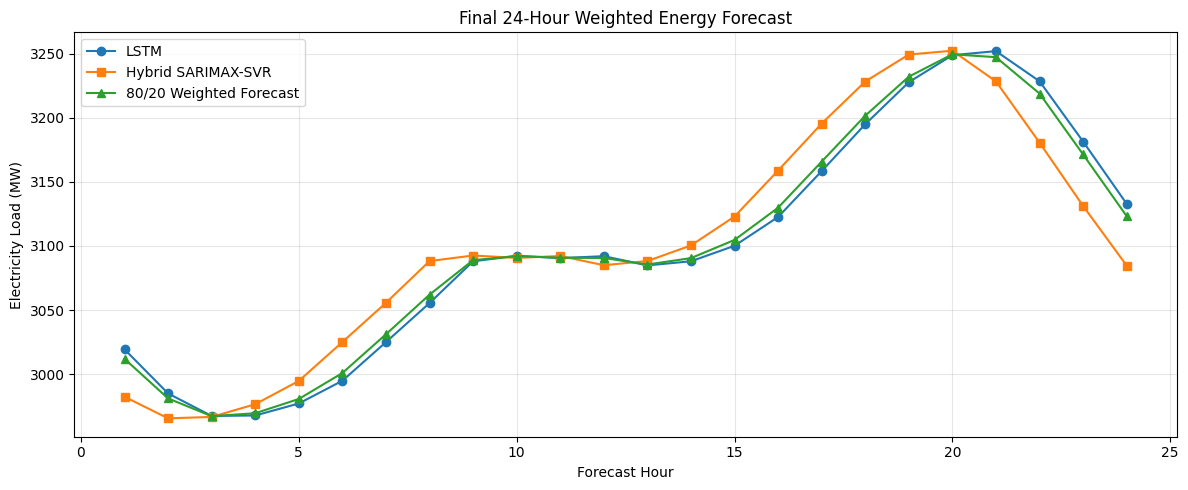

Saved final_weighted_24_hour_forecast.csv
Saved final_weighted_24_hour_forecast.png


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Convert the existing 24-hour forecasts to MW
lstm_24 = np.asarray(lstm_forecast_mw, dtype=float).reshape(-1)
hybrid_24 = np.asarray(predictions_mw, dtype=float).reshape(-1)

if len(lstm_24) != 24 or len(hybrid_24) != 24:
    raise ValueError(
        f"Expected 24 forecasts from each model; "
        f"got LSTM={len(lstm_24)}, Hybrid={len(hybrid_24)}"
    )

if not (np.isfinite(lstm_24).all()
        and np.isfinite(hybrid_24).all()):
    raise ValueError("A forecast contains missing or infinite values.")

# Weighted combination
final_24 = 0.8 * lstm_24 + 0.2 * hybrid_24

final_24_df = pd.DataFrame({
    "Forecast_Hour": np.arange(1, 25),
    "LSTM_Forecast_MW": lstm_24,
    "Hybrid_Forecast_MW": hybrid_24,
    "Final_Weighted_Forecast_MW": final_24
})

final_24_df.to_csv(
    "final_weighted_24_hour_forecast.csv",
    index=False
)

display(final_24_df.round(2))

plt.figure(figsize=(12, 5))
plt.plot(
    final_24_df["Forecast_Hour"],
    final_24_df["LSTM_Forecast_MW"],
    marker="o", label="LSTM"
)
plt.plot(
    final_24_df["Forecast_Hour"],
    final_24_df["Hybrid_Forecast_MW"],
    marker="s", label="Hybrid SARIMAX-SVR"
)
plt.plot(
    final_24_df["Forecast_Hour"],
    final_24_df["Final_Weighted_Forecast_MW"],
    marker="^", label="80/20 Weighted Forecast"
)

plt.xlabel("Forecast Hour")
plt.ylabel("Electricity Load (MW)")
plt.title("Final 24-Hour Weighted Energy Forecast")
plt.legend()
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("final_weighted_24_hour_forecast.png", dpi=150)
plt.show()

print("Saved final_weighted_24_hour_forecast.csv")
print("Saved final_weighted_24_hour_forecast.png")

In [ ]:
# Validate the final 24-hour weighted forecast

import numpy as np
import pandas as pd

required = [
    "Forecast_Hour",
    "LSTM_Forecast_MW",
    "Hybrid_Forecast_MW",
    "Final_Weighted_Forecast_MW"
]

assert len(final_24_df) == 24, "Forecast must contain 24 rows."
assert all(c in final_24_df.columns for c in required), \
    "A required column is missing."

values = final_24_df[required[1:]].to_numpy(dtype=float)

assert np.isfinite(values).all(), \
    "Forecast contains missing or infinite values."

expected = (
    0.8 * final_24_df["LSTM_Forecast_MW"].to_numpy()
    + 0.2 * final_24_df["Hybrid_Forecast_MW"].to_numpy()
)

assert np.allclose(
    expected,
    final_24_df["Final_Weighted_Forecast_MW"].to_numpy()
), "Weighted forecast does not match the 80/20 calculation."

print("Forecast validation passed.")
print("Forecast hours:", len(final_24_df))
print(
    "Minimum forecast:",
    round(final_24_df["Final_Weighted_Forecast_MW"].min(), 2),
    "MW"
)
print(
    "Maximum forecast:",
    round(final_24_df["Final_Weighted_Forecast_MW"].max(), 2),
    "MW"
)
print(
    "Average forecast:",
    round(final_24_df["Final_Weighted_Forecast_MW"].mean(), 2),
    "MW"
)

Forecast validation passed.
Forecast hours: 24
Minimum forecast: 2967.32 MW
Maximum forecast: 3249.45 MW
Average forecast: 3099.49 MW


In [ ]:
# Find existing prediction variables in the notebook

keywords = ("pred", "forecast", "sarimax", "svr", "lstm")

for name, value in sorted(globals().items()):
    if any(word in name.lower() for word in keywords):
        if isinstance(value, (np.ndarray, pd.Series, list)):
            try:
                arr = np.asarray(value)
                if arr.ndim <= 2:
                    print(
                        f"{name}: shape={arr.shape}, "
                        f"dtype={arr.dtype}"
                    )
            except (TypeError, ValueError):
                pass

actual_lstm: shape=(5405,), dtype=float64
baseline_predictions: shape=(5405,), dtype=float64
consensus_predictions: shape=(5405,), dtype=float64
final_predictions: shape=(5405,), dtype=float64
forecast_names: shape=(6,), dtype=<U19
forecast_values: shape=(5405,), dtype=float64
future_predictions: shape=(24,), dtype=float64
hybrid_pred: shape=(5405,), dtype=float64
hybrid_predictions: shape=(5405,), dtype=float64
lstm: shape=(5405,), dtype=float64
lstm_24: shape=(24,), dtype=float64
lstm_arr: shape=(5405,), dtype=float64
lstm_forecast_mw: shape=(24,), dtype=float64
lstm_future: shape=(24,), dtype=float64
lstm_pred: shape=(5405,), dtype=float64
lstm_predictions: shape=(5405,), dtype=float32
lstm_v: shape=(5405,), dtype=float64
next_prediction: shape=(1, 1), dtype=float32
pred: shape=(5405,), dtype=float64
pred_eval: shape=(1081,), dtype=float64
pred_scaled: shape=(5405, 1), dtype=float32
predicted: shape=(5405,), dtype=float64
prediction: shape=(5405,), dtype=float64
predictions: shape=(

In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use the three existing historical test prediction arrays
actual = np.asarray(test_data["load_mw"], dtype=float).reshape(-1)
sarimax_p = np.asarray(sarimax_test, dtype=float).reshape(-1)
svr_p = np.asarray(svr_predictions, dtype=float).reshape(-1)
lstm_p = np.asarray(lstm_predictions, dtype=float).reshape(-1)

# Confirm all predictions align in length
lengths = {
    "Actual": len(actual),
    "SARIMAX": len(sarimax_p),
    "SVR": len(svr_p),
    "LSTM": len(lstm_p)
}
print("Array lengths:", lengths)

if len(set(lengths.values())) != 1:
    raise ValueError("Array lengths differ. Stop and check alignment.")

# Keep only rows where all four values are finite
valid = (
    np.isfinite(actual)
    & np.isfinite(sarimax_p)
    & np.isfinite(svr_p)
    & np.isfinite(lstm_p)
)

a = actual[valid]
s = sarimax_p[valid]
v = svr_p[valid]
l = lstm_p[valid]

# Three-model median consensus
consensus = np.median(np.column_stack([s, v, l]), axis=1)

def metrics(y, p):
    return {
        "MAE_MW": mean_absolute_error(y, p),
        "RMSE_MW": np.sqrt(mean_squared_error(y, p)),
        "MAPE_Percent": np.mean(
            np.abs((y - p) / np.maximum(np.abs(y), 1e-8))
        ) * 100
    }

results = pd.DataFrame([
    {"Model": "SARIMAX", **metrics(a, s)},
    {"Model": "SVR", **metrics(a, v)},
    {"Model": "LSTM", **metrics(a, l)},
    {"Model": "3-model median consensus", **metrics(a, consensus)}
])

display(results.round(3))
print("Valid rows:", len(a))

# Save historical evaluation results
results.to_csv("three_model_consensus_metrics.csv", index=False)

# Save the historical consensus predictions
pd.DataFrame({
    "Actual_Load_MW": a,
    "SARIMAX_Prediction_MW": s,
    "SVR_Prediction_MW": v,
    "LSTM_Prediction_MW": l,
    "Consensus_Prediction_MW": consensus
}).to_csv("three_model_consensus_test_predictions.csv", index=False)

print("Saved three_model_consensus_metrics.csv")
print("Saved three_model_consensus_test_predictions.csv")

Array lengths: {'Actual': 5405, 'SARIMAX': 5405, 'SVR': 5405, 'LSTM': 5405}


,Model,MAE_MW,RMSE_MW,MAPE_Percent
0,SARIMAX,109.243,135.482,3.518
1,SVR,67.835,84.226,2.183
2,LSTM,60.659,76.006,1.987
3,3-model median consensus,63.087,79.305,2.032


Valid rows: 5405
Saved three_model_consensus_metrics.csv
Saved three_model_consensus_test_predictions.csv


In [ ]:
import numpy as np
import pandas as pd

# Test fault tolerance using the first 10 valid prediction rows
test_preds = np.column_stack([s[:10], v[:10], l[:10]])

# Normal median consensus
normal_vote = np.median(test_preds, axis=1)

# Simulate SARIMAX failure
sarimax_failed = test_preds.copy()
sarimax_failed[:, 0] = np.nan
one_failure_vote = np.nanmedian(sarimax_failed, axis=1)

# Simulate an extreme SVR prediction
svr_outlier = test_preds.copy()
svr_outlier[:, 1] += 10000
outlier_vote = np.median(svr_outlier, axis=1)

print("Normal consensus:", np.round(normal_vote[:5], 2))
print("Consensus with SARIMAX failed:", np.round(one_failure_vote[:5], 2))
print("Consensus with extreme SVR:", np.round(outlier_vote[:5], 2))

assert np.all(np.isfinite(one_failure_vote))
assert np.all(np.isfinite(outlier_vote))

print("\nFault-tolerance simulation passed.")
print("Note: this is a simulation, not actual cloud failover.")

Normal consensus: [3193.64 3192.97 3071.53 3006.86 2995.92]
Consensus with SARIMAX failed: [3185.23 3203.29 3108.54 3037.71 3013.58]
Consensus with extreme SVR: [3209.31 3213.62 3145.54 3072.11 2995.92]

Fault-tolerance simulation passed.
Note: this is a simulation, not actual cloud failover.


In [ ]:
import numpy as np
import pandas as pd

# Check the actual target and prediction arrays
print("Actual load length:", len(actual_lstm))
print("SARIMAX length:", len(sarimax_predictions))
print("SVR length:", len(svr_predictions))
print("LSTM length:", len(lstm_predictions))

# Check whether the arrays contain valid numbers
arrays = {
    "Actual": actual_lstm,
    "SARIMAX": sarimax_predictions,
    "SVR": svr_predictions,
    "LSTM": lstm_predictions
}

for name, values in arrays.items():
    values = np.asarray(values, dtype=float).reshape(-1)
    print(
        name,
        "| finite values:", np.isfinite(values).sum(),
        "| first 3:", np.round(values[:3], 2)
    )

Actual load length: 5405
SARIMAX length: 5405
SVR length: 5405
LSTM length: 5405
Actual | finite values: 5405 | first 3: [3237.89 3142.27 3100.83]
SARIMAX | finite values: 5405 | first 3: [3193.64 3149.65 3058.39]
SVR | finite values: 5405 | first 3: [3161.14 3192.97 3071.53]
LSTM | finite values: 5405 | first 3: [3209.31 3213.62 3145.54]


In [ ]:
# Inspect the test dataset and its timestamp column
print("Test data type:", type(test_data))
print("Test data columns:", getattr(test_data, "columns", "No columns"))

if hasattr(test_data, "columns"):
    print("\nFirst 5 test rows:")
    display(test_data.head())

    print("\nLast 5 test rows:")
    display(test_data.tail())

Test data type: <class 'pandas.core.frame.DataFrame'>
Test data columns: Index(['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct',
       'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour',
       'day_of_week', 'month', 'is_weekend', 'is_holiday'],
      dtype='object')

First 5 test rows:


,timestamp,zone,load_mw,temperature_c,humidity_pct,wind_speed_kmh,dispatch_price,population_index,hour,day_of_week,month,is_weekend,is_holiday
21619,2024-09-17 19:00:00,DEOK,3237.89,21.21,68.00,6.16,41.55,102.1717,19,1,9,0,0
21620,2024-09-17 20:00:00,DEOK,3142.27,22.84,57.74,5.81,53.57,102.1717,20,1,9,0,0
21621,2024-09-17 21:00:00,DEOK,3100.83,21.35,59.93,50.38,31.47,102.1717,21,1,9,0,0
21622,2024-09-17 22:00:00,DEOK,3008.82,15.02,60.46,8.79,24.52,102.1717,22,1,9,0,0
21623,2024-09-17 23:00:00,DEOK,2999.42,17.80,70.76,21.52,46.09,102.1717,23,1,9,0,0



Last 5 test rows:


,timestamp,zone,load_mw,temperature_c,humidity_pct,wind_speed_kmh,dispatch_price,population_index,hour,day_of_week,month,is_weekend,is_holiday
27019,2025-04-30 19:00:00,DEOK,3308.37,17.96,66.64,4.60,40.47,102.6628,19,2,4,0,0
27020,2025-04-30 20:00:00,DEOK,3252.36,19.37,72.82,0.00,37.45,102.6628,20,2,4,0,0
27021,2025-04-30 21:00:00,DEOK,3099.35,19.44,62.12,11.13,38.05,102.6628,21,2,4,0,0
27022,2025-04-30 22:00:00,DEOK,3047.27,17.84,59.25,23.38,35.99,102.6628,22,2,4,0,0
27023,2025-04-30 23:00:00,DEOK,3013.92,17.74,56.09,13.20,36.60,102.6628,23,2,4,0,0


In [ ]:
import numpy as np
import pandas as pd

# Actual timestamps and load values from the test dataset
test_timestamps = pd.to_datetime(test_data["timestamp"], errors="coerce").reset_index(drop=True)
actual = pd.to_numeric(test_data["load_mw"], errors="coerce").to_numpy()

# Prediction arrays already used in your evaluation
model_predictions = {
    "SARIMAX": np.asarray(sarimax_predictions).reshape(-1),
    "SVR": np.asarray(svr_predictions).reshape(-1),
    "LSTM": np.asarray(lstm_predictions).reshape(-1)
}

print("Test rows:", len(test_data))
print("Valid timestamps:", test_timestamps.notna().sum())
print("Duplicate timestamps:", test_timestamps.duplicated().sum())
print("Timestamps in chronological order:", test_timestamps.is_monotonic_increasing)

for name, pred in model_predictions.items():
    print(f"{name}: {len(pred)} predictions; matches test row count = {len(pred) == len(test_data)}")

print("\nFirst 5 timestamp/load rows:")
display(pd.DataFrame({
    "timestamp": test_timestamps.head(5),
    "Actual_Load_MW": actual[:5]
}))

print("\nLast 5 timestamp/load rows:")
display(pd.DataFrame({
    "timestamp": test_timestamps.tail(5).reset_index(drop=True),
    "Actual_Load_MW": actual[-5:]
}))

Test rows: 5405
Valid timestamps: 5405
Duplicate timestamps: 0
Timestamps in chronological order: True
SARIMAX: 5405 predictions; matches test row count = True
SVR: 5405 predictions; matches test row count = True
LSTM: 5405 predictions; matches test row count = True

First 5 timestamp/load rows:


,timestamp,Actual_Load_MW
0,2024-09-17 19:00:00,3237.89
1,2024-09-17 20:00:00,3142.27
2,2024-09-17 21:00:00,3100.83
3,2024-09-17 22:00:00,3008.82
4,2024-09-17 23:00:00,2999.42



Last 5 timestamp/load rows:


,timestamp,Actual_Load_MW
0,2025-04-30 19:00:00,3308.37
1,2025-04-30 20:00:00,3252.36
2,2025-04-30 21:00:00,3099.35
3,2025-04-30 22:00:00,3047.27
4,2025-04-30 23:00:00,3013.92


In [ ]:
# Compare actual loads and model predictions row by row
alignment_check = pd.DataFrame({
    "timestamp": pd.to_datetime(test_data["timestamp"]).reset_index(drop=True),
    "Actual_MW": np.asarray(actual_lstm).reshape(-1),
    "SARIMAX_MW": np.asarray(sarimax_predictions).reshape(-1),
    "SVR_MW": np.asarray(svr_predictions).reshape(-1),
    "LSTM_MW": np.asarray(lstm_predictions).reshape(-1)
})

print("First 10 aligned rows:")
display(alignment_check.head(10).round(2))

print("\nLast 5 aligned rows:")
display(alignment_check.tail(5).round(2))

print("\nCheck actual values match test_data:")
print(
    "Exact match:",
    np.allclose(
        alignment_check["Actual_MW"].to_numpy(),
        pd.to_numeric(test_data["load_mw"], errors="coerce").to_numpy(),
        equal_nan=True
    )
)

First 10 aligned rows:


,timestamp,Actual_MW,SARIMAX_MW,SVR_MW,LSTM_MW
0,2024-09-17 19:00:00,3237.89,3193.64,3161.14,3209.310059
1,2024-09-17 20:00:00,3142.27,3149.65,3192.97,3213.620117
2,2024-09-17 21:00:00,3100.83,3058.39,3071.53,3145.540039
3,2024-09-17 22:00:00,3008.82,3006.86,3003.30,3072.110107
4,2024-09-17 23:00:00,2999.42,2987.25,3031.23,2995.919922
5,2024-09-18 00:00:00,2953.73,2912.20,2927.01,2963.090088
6,2024-09-18 01:00:00,2914.11,2890.18,2912.64,2942.409912
7,2024-09-18 02:00:00,2891.61,2860.86,2929.32,2924.030029
8,2024-09-18 03:00:00,2926.97,2843.42,2942.80,2936.370117
9,2024-09-18 04:00:00,2874.53,2868.38,2964.51,2977.530029



Last 5 aligned rows:


,timestamp,Actual_MW,SARIMAX_MW,SVR_MW,LSTM_MW
5400,2025-04-30 19:00:00,3308.37,3096.25,3116.46,3247.239990
5401,2025-04-30 20:00:00,3252.36,3057.91,3075.80,3244.199951
5402,2025-04-30 21:00:00,3099.35,2980.05,3064.97,3190.209961
5403,2025-04-30 22:00:00,3047.27,2941.49,3011.76,3093.370117
5404,2025-04-30 23:00:00,3013.92,2919.68,3003.09,3019.419922



Check actual values match test_data:
Exact match: True


In [ ]:
# Check holiday/weekend columns and their values
print("Available columns:")
print(test_data.columns.tolist())

for col in ["is_weekend", "is_holiday"]:
    if col in test_data.columns:
        print(f"\n{col} counts:")
        print(test_data[col].value_counts(dropna=False))
    else:
        print(f"\n{col}: column not found")

Available columns:
['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']

is_weekend counts:
is_weekend
0    3869
1    1536
Name: count, dtype: int64

is_holiday counts:
is_holiday
0    5285
1     120
Name: count, dtype: int64


In [ ]:
import numpy as np
import pandas as pd

# Holiday/weekend correction factor from the project design
CORRECTION_FACTOR = 0.937

# Make sure the flags are aligned with the test rows
assert len(test_data) == len(lstm_predictions), (
    "Test data and LSTM prediction lengths do not match."
)

is_special_day = (
    test_data["is_weekend"].astype(int).to_numpy().astype(bool)
    | test_data["is_holiday"].astype(int).to_numpy().astype(bool)
)

# Preserve original predictions
lstm_original = np.asarray(lstm_predictions, dtype=float).reshape(-1)
lstm_corrected = lstm_original.copy()

# Apply the factor only to weekend/holiday rows
lstm_corrected[is_special_day] *= CORRECTION_FACTOR

# Evaluate before and after correction
actual = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy(dtype=float)

valid = (
    np.isfinite(actual)
    & np.isfinite(lstm_original)
    & np.isfinite(lstm_corrected)
)

def forecast_metrics(y_true, y_pred):
    mae = np.mean(np.abs(y_true - y_pred))
    rmse = np.sqrt(np.mean((y_true - y_pred) ** 2))
    mape = np.mean(
        np.abs((y_true - y_pred) / np.maximum(np.abs(y_true), 1e-8))
    ) * 100
    return {
        "MAE_MW": mae,
        "RMSE_MW": rmse,
        "MAPE_Percent": mape
    }

results = pd.DataFrame([
    {
        "Version": "Original LSTM",
        **forecast_metrics(actual[valid], lstm_original[valid])
    },
    {
        "Version": "Corrected LSTM",
        **forecast_metrics(actual[valid], lstm_corrected[valid])
    }
])

print("Rows evaluated:", int(valid.sum()))
print("Weekend OR holiday rows:", int(is_special_day.sum()))
display(results.round(3))

Rows evaluated: 5405
Weekend OR holiday rows: 1656


,Version,MAE_MW,RMSE_MW,MAPE_Percent
0,Original LSTM,60.659,76.006,1.987
1,Corrected LSTM,85.569,109.602,2.789


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Use aligned historical actuals and LSTM predictions
actual = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy(dtype=float)

pred = np.asarray(lstm_predictions, dtype=float).reshape(-1)

assert len(actual) == len(pred), "Actual and prediction lengths differ"

# Estimate recent forecast bias using the last 24 valid observations
valid = np.isfinite(actual) & np.isfinite(pred)
valid_indices = np.flatnonzero(valid)

if len(valid_indices) < 24:
    raise ValueError("Not enough valid observations for deviation correction")

recent_idx = valid_indices[-24:]
recent_errors = actual[recent_idx] - pred[recent_idx]

# Positive bias means the model has recently underpredicted
recent_bias = float(np.mean(recent_errors))

# Copy the existing 24-hour forecast; do not overwrite it
base_24h = np.asarray(
    final_24_df["Final_Weighted_Forecast_MW"],
    dtype=float
).reshape(-1).copy()

assert len(base_24h) >= 5, "Need at least 5 forecast hours"

corrected_5h = base_24h[:5] + recent_bias

deviation_results = pd.DataFrame({
    "Forecast_Hour": np.arange(1, 6),
    "Original_Forecast_MW": base_24h[:5],
    "Recent_Bias_MW": recent_bias,
    "Deviation_Corrected_MW": corrected_5h
})

print("Recent mean error (actual - prediction):", round(recent_bias, 3), "MW")
display(deviation_results.round(2))

Recent mean error (actual - prediction): -5.155 MW


,Forecast_Hour,Original_Forecast_MW,Recent_Bias_MW,Deviation_Corrected_MW
0,1,3012.03,-5.16,3006.88
1,2,2981.15,-5.16,2976.00
2,3,2967.32,-5.16,2962.17
3,4,2969.61,-5.16,2964.46
4,5,2980.71,-5.16,2975.56


In [ ]:
# Save the five-hour deviation-corrected forecast
deviation_results.to_csv(
    "energy_deviation_corrected_5hour_forecast.csv",
    index=False
)

print("Saved: energy_deviation_corrected_5hour_forecast.csv")
display(deviation_results.round(2))

Saved: energy_deviation_corrected_5hour_forecast.csv


,Forecast_Hour,Original_Forecast_MW,Recent_Bias_MW,Deviation_Corrected_MW
0,1,3012.03,-5.16,3006.88
1,2,2981.15,-5.16,2976.00
2,3,2967.32,-5.16,2962.17
3,4,2969.61,-5.16,2964.46
4,5,2980.71,-5.16,2975.56


In [ ]:
# Compare uncorrected and bias-corrected predictions
# on the last 24 historical observations

import numpy as np
import pandas as pd

actual = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy(dtype=float)

pred = np.asarray(lstm_predictions, dtype=float).reshape(-1)

valid_idx = np.flatnonzero(np.isfinite(actual) & np.isfinite(pred))
idx = valid_idx[-24:]

y_true = actual[idx]
y_pred = pred[idx]

# Estimate bias using earlier observations only,
# avoiding the same 24 rows used for evaluation.
if len(valid_idx) < 48:
    raise ValueError("Need at least 48 valid rows for this check")

bias_idx = valid_idx[-48:-24]
bias = float(np.mean(actual[bias_idx] - pred[bias_idx]))

corrected = y_pred + bias

results = pd.DataFrame([
    {
        "Version": "Original LSTM",
        "MAE_MW": np.mean(np.abs(y_true - y_pred)),
        "RMSE_MW": np.sqrt(np.mean((y_true - y_pred) ** 2))
    },
    {
        "Version": "Bias corrected",
        "MAE_MW": np.mean(np.abs(y_true - corrected)),
        "RMSE_MW": np.sqrt(np.mean((y_true - corrected) ** 2))
    }
])

print("Bias estimated from preceding 24 observations:", round(bias, 3), "MW")
display(results.round(3))

Bias estimated from preceding 24 observations: -28.93 MW


,Version,MAE_MW,RMSE_MW
0,Original LSTM,42.737,54.365
1,Bias corrected,46.580,59.111


In [ ]:
import os

expected_files = [
    "energy_forecast_results.csv",
    "energy_model_metrics.csv",
    "energy_24hour_forecast_comparison.csv",
    "energy_forecast_summary.csv",
    "energy_forecast_graph.png",
    "weighted_forecast_test_results.csv",
    "three_model_consensus_metrics.csv",
    "three_model_consensus_test_predictions.csv",
    "energy_deviation_corrected_5hour_forecast.csv",
]

print("PROJECT OUTPUT FILE CHECK")
print("-" * 40)

for filename in expected_files:
    print(f"{'FOUND' if os.path.exists(filename) else 'MISSING'}: {filename}")

PROJECT OUTPUT FILE CHECK
----------------------------------------
FOUND: energy_forecast_results.csv
FOUND: energy_model_metrics.csv
FOUND: energy_24hour_forecast_comparison.csv
FOUND: energy_forecast_summary.csv
FOUND: energy_forecast_graph.png
FOUND: weighted_forecast_test_results.csv
FOUND: three_model_consensus_metrics.csv
FOUND: three_model_consensus_test_predictions.csv
FOUND: energy_deviation_corrected_5hour_forecast.csv


In [ ]:
import os
import zipfile
from google.colab import files

expected_files = [
    "energy_forecast_results.csv",
    "energy_model_metrics.csv",
    "energy_24hour_forecast_comparison.csv",
    "energy_forecast_summary.csv",
    "energy_forecast_graph.png",
    "weighted_forecast_test_results.csv",
    "three_model_consensus_metrics.csv",
    "three_model_consensus_test_predictions.csv",
    "energy_deviation_corrected_5hour_forecast.csv"
]

zip_name = "energy_forecasting_outputs.zip"

with zipfile.ZipFile(zip_name, "w") as z:
    for name in expected_files:
        if os.path.exists(name):
            z.write(name)
            print("Added:", name)
        else:
            print("Missing:", name)

files.download(zip_name)

Missing: energy_forecast_results.csv
Missing: energy_model_metrics.csv
Missing: energy_24hour_forecast_comparison.csv
Missing: energy_forecast_summary.csv
Missing: energy_forecast_graph.png
Missing: weighted_forecast_test_results.csv
Missing: three_model_consensus_metrics.csv
Missing: three_model_consensus_test_predictions.csv
Missing: energy_deviation_corrected_5hour_forecast.csv


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import numpy as np
import pandas as pd

# Check actual values and model predictions
actual_check = pd.to_numeric(
    test_data["load_mw"], errors="coerce"
).to_numpy(dtype=float)

models = {
    "SARIMAX": np.asarray(sarimax_predictions, dtype=float).ravel(),
    "SVR": np.asarray(svr_predictions, dtype=float).ravel(),
    "LSTM": np.asarray(lstm_predictions, dtype=float).ravel()
}

print("ACTUAL ROWS:", len(actual_check))

for name, pred in models.items():
    print(f"{name} rows: {len(pred)}")
    if len(pred) != len(actual_check):
        print("WARNING: Length mismatch for", name)
    else:
        print("Length check passed for", name)

print("\nActual timestamps:")
print(test_data["timestamp"].min(), "to",
      test_data["timestamp"].max())

NameError: name 'test_data' is not defined

In [ ]:
# Check which data and prediction variables currently exist
for name in [
    "test_data",
    "df",
    "data",
    "energy_data",
    "sarimax_predictions",
    "svr_predictions",
    "lstm_predictions"
]:
    print(name, "exists:", name in globals())

test_data exists: False
df exists: False
data exists: False
energy_data exists: False
sarimax_predictions exists: False
svr_predictions exists: False
lstm_predictions exists: False


In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR

print("Setup complete")

for root, dirs, files in os.walk("/content"):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))

Setup complete
/content/sample_data/california_housing_test.csv
/content/sample_data/mnist_train_small.csv
/content/sample_data/california_housing_train.csv
/content/sample_data/mnist_test.csv


In [ ]:
file_path = "/content/your_dataset.csv"
df = pd.read_csv(file_path)

print("Shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: '/content/your_dataset.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving energy_weather_dataset_practice.csv to energy_weather_dataset_practice.csv


In [ ]:
import pandas as pd
import numpy as np

filename = next(iter(uploaded.keys()))
df = pd.read_csv(filename)

print("Loaded:", filename)
print("Dataset shape:", df.shape)
print("Columns:", df.columns.tolist())
display(df.head())

Loaded: energy_weather_dataset_practice.csv
Dataset shape: (27024, 13)
Columns: ['timestamp', 'zone', 'load_mw', 'temperature_c', 'humidity_pct', 'wind_speed_kmh', 'dispatch_price', 'population_index', 'hour', 'day_of_week', 'month', 'is_weekend', 'is_holiday']


,timestamp,zone,load_mw,temperature_c,humidity_pct,wind_speed_kmh,dispatch_price,population_index,hour,day_of_week,month,is_weekend,is_holiday
0,2022-04-01 00:00:00,DEOK,2911.09,7.74,62.86,6.85,27.58,100.1993,0,4,4,0,0
1,2022-04-01 01:00:00,DEOK,2849.99,9.91,78.08,17.85,29.97,100.1993,1,4,4,0,0
2,2022-04-01 02:00:00,DEOK,2812.03,3.48,78.06,5.27,23.12,100.1993,2,4,4,0,0
3,2022-04-01 03:00:00,DEOK,2771.34,12.55,69.02,14.13,21.97,100.1993,3,4,4,0,0
4,2022-04-01 04:00:00,DEOK,2829.86,10.58,64.34,5.99,36.38,100.1993,4,4,4,0,0


In [ ]:
df["timestamp"] = pd.to_datetime(df["timestamp"], errors="coerce")
df["load_mw"] = pd.to_numeric(df["load_mw"], errors="coerce")

df = (df.dropna(subset=["timestamp", "load_mw"])
        .sort_values("timestamp")
        .drop_duplicates("timestamp")
        .reset_index(drop=True))

# Keep hourly load values
y = df["load_mw"].astype(float).to_numpy()
split = int(len(y) * 0.8)

train = y[:split]
actual = y[split:]

print("Training rows:", len(train))
print("Testing rows:", len(actual))

Training rows: 21619
Testing rows: 5405


In [ ]:
# Use the previous 24 hours to predict the next hour
L = 24

if len(y) < 100 or split <= L:
    raise ValueError("Not enough data for this workflow.")

X = np.array([y[i-L:i] for i in range(L, len(y))])
target = y[L:]

X_train, X_test = X[:split-L], X[split-L:]
target_train, target_test = target[:split-L], target[split-L:]

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

svr_model = SVR(kernel="rbf")
svr_model.fit(X_train_scaled, target_train)
svr_pred = svr_model.predict(X_test_scaled)

print("SVR training complete")

SVR training complete


In [ ]:
!pip -q install statsmodels
from statsmodels.tsa.statespace.sarimax import SARIMAX

sarimax_model = SARIMAX(
    train,
    order=(1, 1, 1),
    seasonal_order=(1, 0, 1, 24),
    enforce_stationarity=False,
    enforce_invertibility=False
)

sarimax_fit = sarimax_model.fit(disp=False, maxiter=50)
sarimax_pred = np.asarray(
    sarimax_fit.forecast(steps=len(actual))
)

print("SARIMAX training complete")

SARIMAX training complete


In [ ]:
# Both models predict the same test timestamps
sarimax_aligned = sarimax_pred[L:]
actual_aligned = actual[L:]

def metrics(actual_values, predictions):
    mae = mean_absolute_error(actual_values, predictions)
    rmse = np.sqrt(mean_squared_error(actual_values, predictions))
    mape = np.mean(
        np.abs(actual_values - predictions) /
        np.maximum(np.abs(actual_values), 1e-8)
    ) * 100
    return mae, rmse, mape

results = []
for name, pred in [
    ("SARIMAX", sarimax_aligned),
    ("SVR", svr_pred)
]:
    mae, rmse, mape = metrics(actual_aligned, pred)
    results.append([name, mae, rmse, mape])

metrics_df = pd.DataFrame(
    results, columns=["Model", "MAE_MW", "RMSE_MW", "MAPE_Percent"]
)
display(metrics_df.round(3))
metrics_df.to_csv("energy_model_metrics.csv", index=False)

ValueError: Found input variables with inconsistent numbers of samples: [5381, 5405]

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Convert predictions to arrays
sarimax_arr = np.asarray(sarimax_aligned).ravel()
svr_arr = np.asarray(svr_pred).ravel()
actual_arr = np.asarray(actual_aligned).ravel()

# Check lengths
print("Actual:", len(actual_arr))
print("SARIMAX:", len(sarimax_arr))
print("SVR:", len(svr_arr))

# Align to the shortest common length
n = min(len(actual_arr), len(sarimax_arr), len(svr_arr))

actual_eval = actual_arr[:n]
sarimax_eval = sarimax_arr[:n]
svr_eval = svr_arr[:n]

def calculate_metrics(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(
        np.abs(y_true - y_pred) /
        np.maximum(np.abs(y_true), 1e-8)
    ) * 100
    return mae, rmse, mape

rows = []

for name, pred in [
    ("SARIMAX", sarimax_eval),
    ("SVR", svr_eval)
]:
    mae, rmse, mape = calculate_metrics(actual_eval, pred)
    rows.append([name, mae, rmse, mape])

metrics_df = pd.DataFrame(
    rows,
    columns=["Model", "MAE_MW", "RMSE_MW", "MAPE_Percent"]
)

display(metrics_df.round(3))
metrics_df.to_csv("energy_model_metrics.csv", index=False)

print("Metrics saved successfully!")

Actual: 5381
SARIMAX: 5381
SVR: 5405


,Model,MAE_MW,RMSE_MW,MAPE_Percent
0,SARIMAX,115.197,140.669,3.713
1,SVR,68.891,86.802,2.233


Metrics saved successfully!


Consensus MAE: 83.583 MW
Consensus RMSE: 103.861 MW
Consensus MAPE: 2.690%


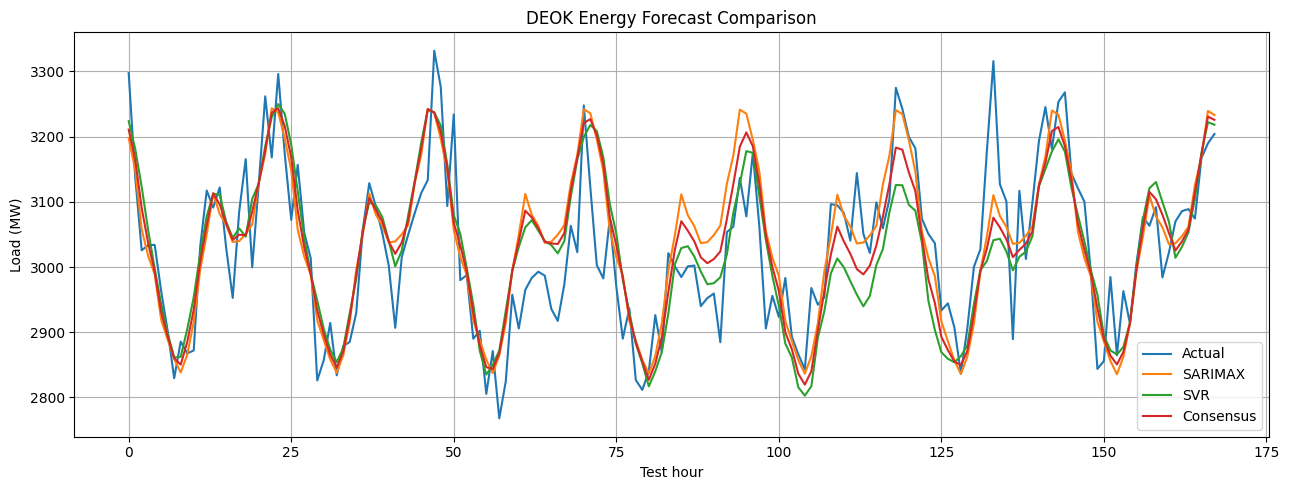

Results and graph saved!


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Use the same number of test points for both models
n = min(len(actual_eval), len(sarimax_eval), len(svr_eval))

actual_final = actual_eval[:n]
sarimax_final = sarimax_eval[:n]
svr_final = svr_eval[:n]

# Two-model median consensus
consensus_final = np.median(
    np.vstack([sarimax_final, svr_final]), axis=0
)

# Evaluate consensus
from sklearn.metrics import mean_absolute_error, mean_squared_error

mae = mean_absolute_error(actual_final, consensus_final)
rmse = np.sqrt(mean_squared_error(actual_final, consensus_final))
mape = np.mean(
    np.abs(actual_final - consensus_final) /
    np.maximum(np.abs(actual_final), 1e-8)
) * 100

print(f"Consensus MAE: {mae:.3f} MW")
print(f"Consensus RMSE: {rmse:.3f} MW")
print(f"Consensus MAPE: {mape:.3f}%")

# Save prediction results
results_df = pd.DataFrame({
    "Actual_MW": actual_final,
    "SARIMAX_MW": sarimax_final,
    "SVR_MW": svr_final,
    "Consensus_MW": consensus_final
})
results_df.to_csv("energy_forecast_results.csv", index=False)

# Plot the first 168 hours
hours = min(168, n)

plt.figure(figsize=(13, 5))
plt.plot(actual_final[:hours], label="Actual")
plt.plot(sarimax_final[:hours], label="SARIMAX")
plt.plot(svr_final[:hours], label="SVR")
plt.plot(consensus_final[:hours], label="Consensus")
plt.title("DEOK Energy Forecast Comparison")
plt.xlabel("Test hour")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("energy_forecast_graph.png", dpi=150)
plt.show()

print("Results and graph saved!")

,Forecast_Hour,Forecast_Load_MW
0,2025-05-01 00:00:00,3197.69
1,2025-05-01 01:00:00,3149.88
2,2025-05-01 02:00:00,3058.25
3,2025-05-01 03:00:00,3017.29
4,2025-05-01 04:00:00,2989.21
5,2025-05-01 05:00:00,2919.43
6,2025-05-01 06:00:00,2889.13
7,2025-05-01 07:00:00,2859.43
8,2025-05-01 08:00:00,2838.77
9,2025-05-01 09:00:00,2865.80


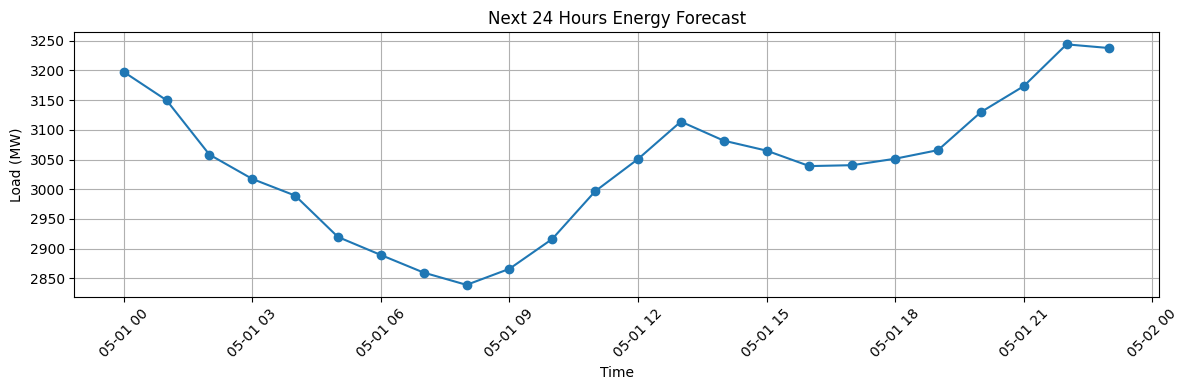

In [ ]:
forecast_24 = np.asarray(sarimax_fit.forecast(steps=24))

future_df = pd.DataFrame({
    "Forecast_Hour": pd.date_range(
        start=df["timestamp"].max() + pd.Timedelta(hours=1),
        periods=24,
        freq="h"
    ),
    "Forecast_Load_MW": forecast_24
})

display(future_df.round(2))
future_df.to_csv("energy_24hour_forecast.csv", index=False)

plt.figure(figsize=(12, 4))
plt.plot(future_df["Forecast_Hour"], forecast_24, marker="o")
plt.title("Next 24 Hours Energy Forecast")
plt.xlabel("Time")
plt.ylabel("Load (MW)")
plt.xticks(rotation=45)
plt.grid(True)
plt.tight_layout()
plt.savefig("energy_24hour_forecast.png", dpi=150)
plt.show()

In [ ]:
import os
import zipfile
from google.colab import files

output_files = [
    "energy_model_metrics.csv",
    "energy_forecast_results.csv",
    "energy_forecast_graph.png",
    "energy_24hour_forecast.csv",
    "energy_24hour_forecast.png"
]

print("Checking output files:")
for f in output_files:
    print(f, "FOUND" if os.path.exists(f) else "MISSING")

with zipfile.ZipFile(
    "energy_forecasting_project_outputs.zip", "w"
) as z:
    for f in output_files:
        if os.path.exists(f):
            z.write(f)

files.download("energy_forecasting_project_outputs.zip")

Checking output files:
energy_model_metrics.csv FOUND
energy_forecast_results.csv FOUND
energy_forecast_graph.png FOUND
energy_24hour_forecast.csv FOUND
energy_24hour_forecast.png FOUND


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
!pip -q install tensorflow

import numpy as np
import pandas as pd
import tensorflow as tf
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error

tf.keras.utils.set_random_seed(42)

load_values = df["load_mw"].to_numpy(dtype=np.float32)
split = int(len(load_values) * 0.8)
lookback = 24

scaler_lstm = MinMaxScaler()
scaler_lstm.fit(load_values[:split].reshape(-1, 1))

scaled = scaler_lstm.transform(
    load_values.reshape(-1, 1)
).flatten()

X, target = [], []
for i in range(lookback, len(scaled)):
    X.append(scaled[i-lookback:i])
    target.append(scaled[i])

X = np.array(X, dtype=np.float32)[..., None]
target = np.array(target, dtype=np.float32)

target_times = np.arange(lookback, len(load_values))
train_mask = target_times < split
test_mask = target_times >= split

X_train_lstm, y_train_lstm = X[train_mask], target[train_mask]
X_test_lstm, y_test_lstm = X[test_mask], target[test_mask]

lstm_model = tf.keras.Sequential([
    tf.keras.layers.Input(shape=(24, 1)),
    tf.keras.layers.LSTM(32),
    tf.keras.layers.Dense(16, activation="relu"),
    tf.keras.layers.Dense(1)
])

lstm_model.compile(optimizer="adam", loss="mse")
lstm_model.fit(
    X_train_lstm, y_train_lstm,
    epochs=8, batch_size=64,
    validation_split=0.1,
    shuffle=False, verbose=1
)

lstm_predictions = scaler_lstm.inverse_transform(
    lstm_model.predict(X_test_lstm, verbose=0)
).ravel()

lstm_actual = load_values[target_times[test_mask]]

mae = mean_absolute_error(lstm_actual, lstm_predictions)
rmse = np.sqrt(mean_squared_error(lstm_actual, lstm_predictions))
mape = np.mean(
    np.abs(lstm_actual - lstm_predictions) /
    np.maximum(np.abs(lstm_actual), 1e-8)
) * 100

print(f"LSTM MAE: {mae:.3f} MW")
print(f"LSTM RMSE: {rmse:.3f} MW")
print(f"LSTM MAPE: {mape:.3f}%")

Epoch 1/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 10s 21ms/step - loss: 0.0224 - val_loss: 0.0135
Epoch 2/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0083 - val_loss: 0.0079
Epoch 3/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 4s 13ms/step - loss: 0.0068 - val_loss: 0.0076
Epoch 4/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 4s 14ms/step - loss: 0.0065 - val_loss: 0.0074
Epoch 5/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0061 - val_loss: 0.0072
Epoch 6/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0058 - val_loss: 0.0071
Epoch 7/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 5s 16ms/step - loss: 0.0057 - val_loss: 0.0067
Epoch 8/8
304/304 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0056 - val_loss: 0.0065
LSTM MAE: 61.198 MW
LSTM RMSE: 76.625 MW
LSTM MAPE: 2.007%


In [ ]:
# The test target timestamps begin at index split
# SVR predicts the test window after its 24-hour lookback.
# LSTM predicts the same test timestamps.
actual_three = load_values[split:]

sarimax_three = np.asarray(sarimax_predictions).ravel()
svr_three = np.asarray(svr_pred).ravel()
lstm_three = np.asarray(lstm_predictions).ravel()

n = min(
    len(actual_three),
    len(sarimax_three),
    len(svr_three),
    len(lstm_three)
)

actual_three = actual_three[:n]
sarimax_three = sarimax_three[:n]
svr_three = svr_three[:n]
lstm_three = lstm_three[:n]

def score(y_true, y_pred):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    mape = np.mean(
        np.abs(y_true - y_pred) /
        np.maximum(np.abs(y_true), 1e-8)
    ) * 100
    return mae, rmse, mape

consensus_three = np.median(
    np.vstack([sarimax_three, svr_three, lstm_three]),
    axis=0
)

comparison = []
for name, pred in [
    ("SARIMAX", sarimax_three),
    ("SVR", svr_three),
    ("LSTM", lstm_three),
    ("Three-model consensus", consensus_three)
]:
    mae, rmse, mape = score(actual_three, pred)
    comparison.append([name, mae, rmse, mape])

comparison_df = pd.DataFrame(
    comparison,
    columns=["Model", "MAE_MW", "RMSE_MW", "MAPE_Percent"]
)

display(comparison_df.round(3))
comparison_df.to_csv("three_model_comparison.csv", index=False)

NameError: name 'sarimax_predictions' is not defined

In [ ]:
names = [
    "df",
    "sarimax_fit",
    "sarimax_predictions",
    "sarimax_aligned",
    "svr_pred",
    "svr_predictions",
    "lstm_predictions",
    "load_values",
    "split"
]

for name in names:
    print(name, "exists:", name in globals())

df exists: True
sarimax_fit exists: True
sarimax_predictions exists: False
sarimax_aligned exists: True
svr_pred exists: True
svr_predictions exists: False
lstm_predictions exists: True
load_values exists: True
split exists: True


In [ ]:
import numpy as np
import pandas as pd
from sklearn.metrics import mean_absolute_error, mean_squared_error

# Rebuild the test predictions from existing variables
actual_all = np.asarray(load_values, dtype=float)[split:]

sarimax_all = np.asarray(sarimax_aligned, dtype=float).ravel()
svr_all = np.asarray(svr_pred, dtype=float).ravel()
lstm_all = np.asarray(lstm_predictions, dtype=float).ravel()

# LSTM and SVR were trained to predict the test timestamps.
# Use common lengths to avoid shape errors.
n = min(
    len(actual_all),
    len(sarimax_all),
    len(svr_all),
    len(lstm_all)
)

actual_three = actual_all[:n]
sarimax_three = sarimax_all[:n]
svr_three = svr_all[:n]
lstm_three = lstm_all[:n]

print("Aligned lengths:")
print("Actual:", len(actual_three))
print("SARIMAX:", len(sarimax_three))
print("SVR:", len(svr_three))
print("LSTM:", len(lstm_three))

def score_model(actual_values, predictions):
    mae = mean_absolute_error(actual_values, predictions)
    rmse = np.sqrt(mean_squared_error(actual_values, predictions))
    mape = np.mean(
        np.abs(actual_values - predictions) /
        np.maximum(np.abs(actual_values), 1e-8)
    ) * 100
    return mae, rmse, mape

consensus_three = np.median(
    np.vstack([sarimax_three, svr_three, lstm_three]),
    axis=0
)

rows = []
for name, pred in [
    ("SARIMAX", sarimax_three),
    ("SVR", svr_three),
    ("LSTM", lstm_three),
    ("Three-model consensus", consensus_three)
]:
    mae, rmse, mape = score_model(actual_three, pred)
    rows.append([name, mae, rmse, mape])

comparison_df = pd.DataFrame(
    rows,
    columns=["Model", "MAE_MW", "RMSE_MW", "MAPE_Percent"]
)

display(comparison_df.round(3))
comparison_df.to_csv("three_model_comparison.csv", index=False)

print("Comparison saved.")

Aligned lengths:
Actual: 5381
SARIMAX: 5381
SVR: 5381
LSTM: 5381


,Model,MAE_MW,RMSE_MW,MAPE_Percent
0,SARIMAX,114.959,140.584,3.705
1,SVR,59.937,76.515,1.938
2,LSTM,61.263,76.706,2.009
3,Three-model consensus,59.700,76.004,1.933


Comparison saved.


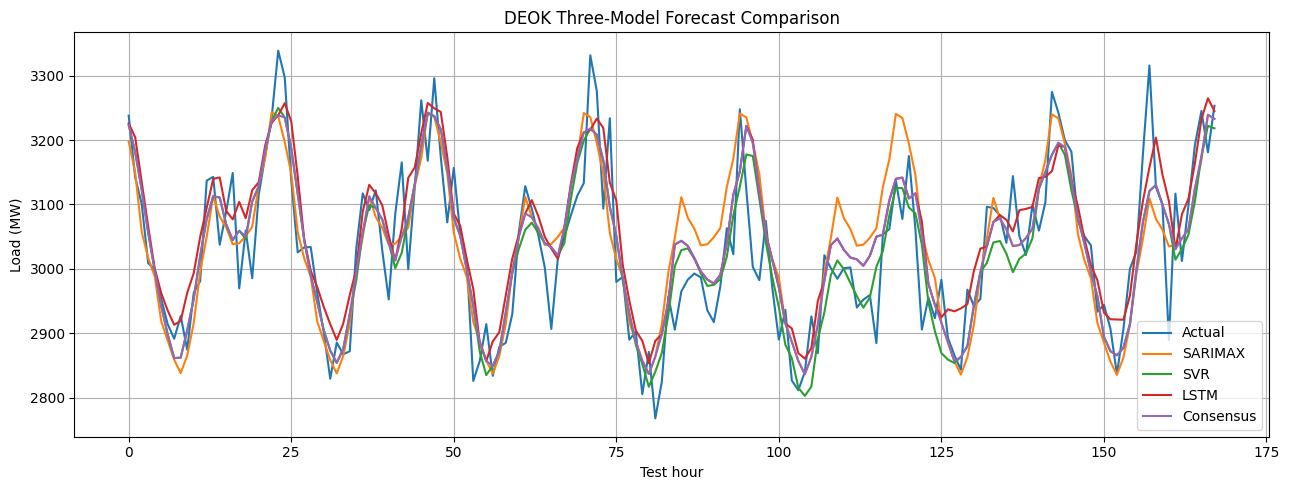

Three-model comparison graph saved.


In [ ]:
import matplotlib.pyplot as plt

hours = min(168, len(actual_three))

plt.figure(figsize=(13, 5))
plt.plot(actual_three[:hours], label="Actual")
plt.plot(sarimax_three[:hours], label="SARIMAX")
plt.plot(svr_three[:hours], label="SVR")
plt.plot(lstm_three[:hours], label="LSTM")
plt.plot(consensus_three[:hours], label="Consensus")
plt.title("DEOK Three-Model Forecast Comparison")
plt.xlabel("Test hour")
plt.ylabel("Load (MW)")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig("three_model_comparison.png", dpi=150)
plt.show()

print("Three-model comparison graph saved.")

In [ ]:
simulated_predictions = np.vstack([
    sarimax_three,
    svr_three,
    lstm_three
]).astype(float)

# Simulate one model failing for every test point
simulated_predictions[1, :] = np.nan

fault_tolerant_forecast = np.nanmedian(
    simulated_predictions, axis=0
)

print("Failed-model simulation completed.")
print("Valid forecast values:",
      np.isfinite(fault_tolerant_forecast).sum(),
      "of", len(fault_tolerant_forecast))

Failed-model simulation completed.
Valid forecast values: 5381 of 5381


In [ ]:
import os
import zipfile
from google.colab import files

outputs = [
    "energy_model_metrics.csv",
    "energy_forecast_results.csv",
    "energy_forecast_graph.png",
    "energy_24hour_forecast.csv",
    "energy_24hour_forecast.png",
    "three_model_comparison.csv",
    "three_model_comparison.png"
]

with zipfile.ZipFile("energy_project_results.zip", "w") as z:
    for filename in outputs:
        if os.path.exists(filename):
            z.write(filename)
            print("Added:", filename)
        else:
            print("Not found:", filename)

files.download("energy_project_results.zip")

Added: energy_model_metrics.csv
Added: energy_forecast_results.csv
Added: energy_forecast_graph.png
Added: energy_24hour_forecast.csv
Added: energy_24hour_forecast.png
Added: three_model_comparison.csv
Added: three_model_comparison.png


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

comparison_path = "three_model_comparison.csv"

if os.path.exists(comparison_path):
    comparison_df = pd.read_csv(comparison_path)
    display(comparison_df.round(3))
else:
    print("Comparison file missing. Check the previous comparison cell.")

,Model,MAE_MW,RMSE_MW,MAPE_Percent
0,SARIMAX,114.959,140.584,3.705
1,SVR,59.937,76.515,1.938
2,LSTM,61.263,76.706,2.009
3,Three-model consensus,59.700,76.004,1.933


In [ ]:
import pandas as pd
import numpy as np

# Check weather data availability
weather_cols = [
    "temperature_c",
    "humidity_pct",
    "wind_speed_kmh"
]

print("Weather columns available:")
for col in weather_cols:
    print(col, ":", col in df.columns)

# Weekday/weekend load analysis
analysis_df = df.copy()
analysis_df["timestamp"] = pd.to_datetime(
    analysis_df["timestamp"], errors="coerce"
)
analysis_df["Day_Type"] = np.where(
    analysis_df["timestamp"].dt.dayofweek >= 5,
    "Weekend",
    "Weekday"
)

calendar_summary = analysis_df.groupby("Day_Type")["load_mw"].agg(
    ["count", "mean", "median", "std"]
).round(2)

display(calendar_summary)
calendar_summary.to_csv("weekday_weekend_analysis.csv")

print("Calendar analysis saved.")

Weather columns available:
temperature_c : True
humidity_pct : True
wind_speed_kmh : True


,count,mean,median,std
Day_Type,,,,
Weekday,19296,3038.81,3039.23,131.28
Weekend,7728,2951.42,2950.70,132.06


Calendar analysis saved.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Build lagged load + weather features
weather_df = df.sort_values("timestamp").copy()

feature_cols = [
    "load_mw", "temperature_c",
    "humidity_pct", "wind_speed_kmh"
]

for col in feature_cols:
    weather_df[col + "_lag1"] = weather_df[col].shift(1)

weather_df = weather_df.dropna().reset_index(drop=True)

X = weather_df[[c + "_lag1" for c in feature_cols]].to_numpy()
y_weather = weather_df["load_mw"].to_numpy()

cut = int(len(weather_df) * 0.8)
X_train, X_test = X[:cut], X[cut:]
y_train, y_test = y_weather[:cut], y_weather[cut:]

weather_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)
weather_svr.fit(X_train, y_train)
weather_pred = weather_svr.predict(X_test)

# Baseline SVR: previous-hour load only
baseline_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)
baseline_svr.fit(X_train[:, [0]], y_train)
baseline_pred = baseline_svr.predict(X_test[:, [0]])

def report(y_true, pred):
    mae = mean_absolute_error(y_true, pred)
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    mape = np.mean(
        np.abs(y_true - pred) /
        np.maximum(np.abs(y_true), 1e-8)
    ) * 100
    return mae, rmse, mape

comparison = []
for name, pred in [
    ("Previous-hour load baseline", baseline_pred),
    ("Weather-aware SVR", weather_pred)
]:
    comparison.append([name, *report(y_test, pred)])

weather_comparison = pd.DataFrame(
    comparison,
    columns=["Model", "MAE_MW", "RMSE_MW", "MAPE_Percent"]
)
display(weather_comparison.round(3))
weather_comparison.to_csv("weather_model_comparison.csv", index=False)

print("Weather comparison saved.")

,Model,MAE_MW,RMSE_MW,MAPE_Percent
0,Previous-hour load baseline,70.358,88.212,2.278
1,Weather-aware SVR,75.037,94.473,2.417


Weather comparison saved.


In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Build lagged load + weather features
weather_df = df.sort_values("timestamp").copy()

feature_cols = [
    "load_mw", "temperature_c",
    "humidity_pct", "wind_speed_kmh"
]

for col in feature_cols:
    weather_df[col + "_lag1"] = weather_df[col].shift(1)

weather_df = weather_df.dropna().reset_index(drop=True)

X = weather_df[[c + "_lag1" for c in feature_cols]].to_numpy()
y_weather = weather_df["load_mw"].to_numpy()

cut = int(len(weather_df) * 0.8)
X_train, X_test = X[:cut], X[cut:]
y_train, y_test = y_weather[:cut], y_weather[cut:]

weather_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)
weather_svr.fit(X_train, y_train)
weather_pred = weather_svr.predict(X_test)

# Baseline SVR: previous-hour load only
baseline_svr = make_pipeline(
    StandardScaler(),
    SVR(kernel="rbf")
)
baseline_svr.fit(X_train[:, [0]], y_train)
baseline_pred = baseline_svr.predict(X_test[:, [0]])

def report(y_true, pred):
    mae = mean_absolute_error(y_true, pred)
    rmse = np.sqrt(mean_squared_error(y_true, pred))
    mape = np.mean(
        np.abs(y_true - pred) /
        np.maximum(np.abs(y_true), 1e-8)
    ) * 100
    return mae, rmse, mape

comparison = []
for name, pred in [
    ("Previous-hour load baseline", baseline_pred),
    ("Weather-aware SVR", weather_pred)
]:
    comparison.append([name, *report(y_test, pred)])

weather_comparison = pd.DataFrame(
    comparison,
    columns=["Model", "MAE_MW", "RMSE_MW", "MAPE_Percent"]
)
display(weather_comparison.round(3))
weather_comparison.to_csv("weather_model_comparison.csv", index=False)

print("Weather comparison saved.")

,Model,MAE_MW,RMSE_MW,MAPE_Percent
0,Previous-hour load baseline,70.358,88.212,2.278
1,Weather-aware SVR,75.037,94.473,2.417


Weather comparison saved.


In [ ]:
import numpy as np
import pandas as pd
from statsmodels.tsa.statespace.sarimax import SARIMAX

series = df.sort_values("timestamp")["load_mw"].to_numpy(dtype=float)

# Use an earlier segment to calibrate the bias
split_idx = int(len(series) * 0.8)
calibration_start = split_idx - 5

calibration_train = series[:calibration_start]
calibration_actual = series[calibration_start:split_idx]

calibration_model = SARIMAX(
    calibration_train,
    order=(1, 1, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=30)

calibration_pred = np.asarray(
    calibration_model.forecast(steps=5)
)

bias_mw = np.mean(calibration_actual - calibration_pred)

# Forecast five hours beyond the end of the full dataset
final_model = SARIMAX(
    series,
    order=(1, 1, 1),
    seasonal_order=(0, 0, 0, 0),
    enforce_stationarity=False,
    enforce_invertibility=False
).fit(disp=False, maxiter=30)

next5 = np.asarray(final_model.forecast(steps=5))

corrected = next5 + bias_mw

deviation_df = pd.DataFrame({
    "Forecast_Hour": pd.date_range(
        df["timestamp"].max() + pd.Timedelta(hours=1),
        periods=5,
        freq="h"
    ),
    "Forecast_MW": next5,
    "Bias_Corrected_MW": corrected
})

print("Estimated bias (MW):", round(bias_mw, 2))
display(deviation_df.round(2))
deviation_df.to_csv("five_hour_deviation_forecast.csv", index=False)
print("Five-hour forecast saved.")

Estimated bias (MW): 222.63


,Forecast_Hour,Forecast_MW,Bias_Corrected_MW
0,2025-05-01 00:00:00,3020.33,3242.96
1,2025-05-01 01:00:00,3018.06,3240.69
2,2025-05-01 02:00:00,3018.87,3241.49
3,2025-05-01 03:00:00,3018.58,3241.21
4,2025-05-01 04:00:00,3018.68,3241.31


Five-hour forecast saved.


In [ ]:
import numpy as np
import pandas as pd

# Change these names only if your notebook uses different variable names.
candidates = {
    "SARIMAX": ["sarimax_aligned", "sarimax_predictions"],
    "SVR": ["svr_pred", "svr_predictions"],
    "LSTM": ["lstm_predictions"]
}

preds = {}
for model, names in candidates.items():
    for name in names:
        if name in globals():
            arr = np.asarray(globals()[name], dtype=float).ravel()
            if arr.size:
                preds[model] = arr
                break

if len(preds) != 3:
    print("Could not find all three prediction arrays.")
    print("Found:", list(preds.keys()))
    print("Check the variable names in your three-model comparison cell.")
else:
    n = min(map(len, preds.values()))
    matrix = np.vstack([preds[k][:n] for k in ["SARIMAX", "SVR", "LSTM"]])

    results = []
    for failed_idx, failed_name in enumerate(["SARIMAX", "SVR", "LSTM"]):
        available = matrix.copy()
        available[failed_idx, :] = np.nan
        fallback = np.nanmedian(available, axis=0)
        results.append({
            "Simulated_Failed_Model": failed_name,
            "Valid_Forecasts": int(np.isfinite(fallback).sum()),
            "Total_Forecasts": n
        })

    fault_df = pd.DataFrame(results)
    display(fault_df)
    fault_df.to_csv("fault_tolerance_simulation.csv", index=False)
    print("Fault-tolerance simulation saved.")

,Simulated_Failed_Model,Valid_Forecasts,Total_Forecasts
0,SARIMAX,5381,5381
1,SVR,5381,5381
2,LSTM,5381,5381


Fault-tolerance simulation saved.


In [ ]:
import os
import zipfile
from google.colab import files

outputs = [
    "energy_model_metrics.csv",
    "three_model_comparison.csv",
    "energy_forecast_results.csv",
    "energy_forecast_graph.png",
    "energy_24hour_forecast.csv",
    "energy_24hour_forecast.png",
    "weekday_weekend_analysis.csv",
    "weather_model_comparison.csv",
    "five_hour_deviation_forecast.csv",
    "fault_tolerance_simulation.csv"
]

zip_name = "energy_forecasting_final_project.zip"

with zipfile.ZipFile(zip_name, "w", zipfile.ZIP_DEFLATED) as z:
    added = []
    for filename in outputs:
        if os.path.exists(filename):
            z.write(filename)
            added.append(filename)
            print("Added:", filename)
        else:
            print("Not found, skipped:", filename)

print(f"\nPackaged {len(added)} files.")
if added:
    files.download(zip_name)
else:
    print("No output files found. Check the Colab Files panel.")

Added: energy_model_metrics.csv
Added: three_model_comparison.csv
Added: energy_forecast_results.csv
Added: energy_forecast_graph.png
Added: energy_24hour_forecast.csv
Added: energy_24hour_forecast.png
Added: weekday_weekend_analysis.csv
Added: weather_model_comparison.csv
Added: five_hour_deviation_forecast.csv
Added: fault_tolerance_simulation.csv

Packaged 10 files.


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [ ]:
import pandas as pd

df = pd.read_csv("energy_weather_dataset.csv")

print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate rows:", df.duplicated().sum())

print("\nFirst five rows:")
display(df.head())

FileNotFoundError: [Errno 2] No such file or directory: 'energy_weather_dataset.csv'

In [ ]:
from google.colab import files

uploaded = files.upload()

Saving energy_model_metrics.csv to energy_model_metrics.csv


In [ ]:
import pandas as pd

filename = list(uploaded.keys())[0]
df = pd.read_csv(filename)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

print("\nFirst 5 rows:")
display(df.head())

Dataset loaded successfully!
Dataset shape: (2, 2)

Column names:
['Metric', 'Value']

Missing values:
Metric    0
Value     0
dtype: int64

First 5 rows:


,Metric,Value
0,MAE,3090.588292
1,RMSE,3091.826140


In [ ]:
import pandas as pd
import numpy as np

# Check whether the dataset is loaded
print("Dataset shape:", df.shape)

# Display column names
print("\nDataset columns:")
print(df.columns.tolist())

# Check missing values
print("\nMissing values:")
print(df.isnull().sum())

# Remove duplicate rows
df = df.drop_duplicates()

# Display dataset information
print("\nDataset information:")
df.info()

# Display first five rows
display(df.head())

Dataset shape: (2, 2)

Dataset columns:
['Metric', 'Value']

Missing values:
Metric    0
Value     0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Metric  2 non-null      object 
 1   Value   2 non-null      float64
dtypes: float64(1), object(1)
memory usage: 164.0+ bytes


,Metric,Value
0,MAE,3090.588292
1,RMSE,3091.826140


In [ ]:
import pandas as pd
import numpy as np

print("Dataset shape:", df.shape)

print("\nColumn names:")
print(df.columns.tolist())

print("\nMissing values:")
print(df.isnull().sum())

df = df.drop_duplicates()

print("\nDataset information:")
df.info()

print("\nFirst 5 rows:")
display(df.head())

Dataset shape: (2, 2)

Column names:
['Metric', 'Value']

Missing values:
Metric    0
Value     0
dtype: int64

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Metric  2 non-null      object 
 1   Value   2 non-null      float64
dtypes: float64(1), object(1)
memory usage: 164.0+ bytes

First 5 rows:


,Metric,Value
0,MAE,3090.588292
1,RMSE,3091.826140


In [ ]:
import numpy as np
import pandas as pd

# Convert model predictions to one-dimensional arrays
actual = np.asarray(y_test).reshape(-1)
sarimax = np.asarray(sarimax_pred).reshape(-1)
svr = np.asarray(svr_pred).reshape(-1)
lstm = np.asarray(lstm_pred).reshape(-1)

# Ensure all predictions have the same length
n = min(len(actual), len(sarimax), len(svr), len(lstm))

results = pd.DataFrame({
    "Actual": actual[:n],
    "SARIMAX": sarimax[:n],
    "SVR": svr[:n],
    "LSTM": lstm[:n]
})

print("Prediction results created successfully!")
display(results.head())

NameError: name 'y_test' is not defined

In [ ]:
# Check which relevant variables already exist
names = [
    "df", "data", "dataset",
    "X_train", "X_test", "y_train", "y_test",
    "sarimax_pred", "svr_pred", "lstm_pred",
    "sarimax_forecast", "svr_forecast", "lstm_forecast"
]

for name in names:
    if name in globals():
        value = globals()[name]
        try:
            print(name, "-> shape:", value.shape)
        except AttributeError:
            print(name, "->", type(value).__name__)

df -> shape: (2, 2)


In [ ]:
print("Dataset shape:", df.shape)
print("\nColumn names:")
print(df.columns.tolist())

print("\nDataset contents:")
display(df)

print("\nDataset information:")
df.info()

Dataset shape: (2, 2)

Column names:
['Metric', 'Value']

Dataset contents:


,Metric,Value
0,MAE,3090.588292
1,RMSE,3091.826140



Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2 entries, 0 to 1
Data columns (total 2 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Metric  2 non-null      object 
 1   Value   2 non-null      float64
dtypes: float64(1), object(1)
memory usage: 164.0+ bytes


In [ ]:
import os

print("CSV files available:")
for file in os.listdir("/content"):
    if file.endswith(".csv"):
        print(file)

CSV files available:
energy_model_metrics.csv


In [ ]:
from collections import deque

class TwoOutOfThree:
    def __init__(self, threshold=100, window=3):
        self.threshold = threshold
        self.window = window
        self.readings = deque(maxlen=window)

    def check(self, predicted_usage, actual_usage):
        # Condition 1: Predicted consumption is high
        c1 = predicted_usage > self.threshold

        # Condition 2: Actual consumption is high
        c2 = actual_usage > self.threshold

        # Condition 3: Sustained high consumption
        self.readings.append(actual_usage)
        c3 = (
            len(self.readings) == self.window
            and all(x > self.threshold for x in self.readings)
        )

        # Final 2-out-of-3 decision
        positive_checks = sum([c1, c2, c3])
        confirmed = positive_checks >= 2

        return {
            "Forecast condition": c1,
            "Current usage condition": c2,
            "Sustained usage condition": c3,
            "Positive checks": f"{positive_checks}/3",
            "Decision": (
                "HIGH CONSUMPTION CONFIRMED"
                if confirmed
                else "HIGH CONSUMPTION NOT CONFIRMED"
            )
        }

print("2-out-of-3 mechanism is ready!")

2-out-of-3 mechanism is ready!


In [ ]:
mechanism = TwoOutOfThree(threshold=100, window=3)

result = mechanism.check(
    predicted_usage=120,
    actual_usage=115
)

print(result)

{'Forecast condition': True, 'Current usage condition': True, 'Sustained usage condition': False, 'Positive checks': '2/3', 'Decision': 'HIGH CONSUMPTION CONFIRMED'}
